# ĐỀ TÀI: MÔ HÌNH AI DỰ ĐOÁN GIÁ NHÀ Ở PHƯỜNG PHÚ HÒA, TP. THỦ DẦU MỘT (phiên bản 2)

**Mã sinh viên:** 2324801030095
**Họ và tên:** Nguyễn Quang Long
**Lớp:** D23KTPM01
**Môn:** Học máy

**Bài toán học máy** (theo định nghĩa trong bài giảng: chương trình học từ kinh nghiệm **E** để làm nhiệm vụ **T** tốt hơn theo độ đo **P**):
- **T (nhiệm vụ):** dự đoán giá rao bán (tỷ đồng) của một căn nhà từ các thông số của nó → **học có giám sát, hồi quy**.
- **E (kinh nghiệm):** các tin rao bán thật đã biết giá (dữ liệu huấn luyện).
- **P (độ đo):** sai số phần trăm trung bình **MAPE** trên những căn mô hình **chưa từng thấy** (tập test).

**Mô tả:** cho thông tin một căn nhà (diện tích, kích thước, số tầng, số phòng, lối vào, vị trí, mô tả tin), mô hình dự đoán **giá bán (tỷ đồng)** kèm **khoảng giá tin cậy**, rồi **chẩn đoán** giá rao đang rẻ, hợp lý hay cao so với mặt bằng thị trường. Đây là bài toán **học có giám sát – hồi quy**.

**Phiên bản 2 khắc phục các hạn chế của phiên bản 1** (bản cũ đã gỡ khỏi project, còn trong lịch sử git):

| Hạn chế ở phiên bản 1 | Cách khắc phục trong phiên bản 2 |
|---|---|
| Ít dữ liệu, 1 nguồn (guland) | Thu thập thêm **Chợ Tốt Nhà** (API công khai, toàn Bình Dương cũ) và **alonhadat** (Thủ Dầu Một): số căn gấp nhiều lần (bảng ở Bước 1 và Bước 4) |
| Không có vị trí chi tiết | Tọa độ từ Chợ Tốt; tin không có tọa độ được gán theo **tuyến đường** → tính **giá khu vực** (k căn gần nhất, phường, tuyến đường) |
| Chưa khai thác phần mô tả tin | Đọc **từ khóa** (khu dân cư, hẻm xe hơi, sổ riêng/sổ chung, nhà nát, dãy trọ, bán gấp…) và **mô hình chữ TF‑IDF** xếp chồng (stacking) |
| Tin rác lẫn vào dữ liệu | Quy tắc làm sạch có giải thích: tin cho thuê, nhà lắp ghép, nhà ở xã hội, giá mồi ("2 tỷ xxx"), đất chưa thổ cư, đơn giá lệch > 3 lần khu vực; **sửa** diện tích nhập nhầm |
| Chỉ có 1 con số dự đoán | **Khoảng giá 80%** hiệu chỉnh từ sai số ngoài-fold (ý tưởng conformal), có kiểm tra độ phủ trên tập test |
| Đánh giá trên 1 lần chia, tập test vài chục căn | **Kiểm định chéo lặp 3 lần, chia theo nhóm tin gần trùng** (không rò rỉ), kèm khoảng tin cậy 95%; tập test giữ riêng chỉ để kiểm tra lần cuối |
| Chỉ thử mô hình mặc định | So sánh 6 mô hình + baseline; chọn **mô hình đơn giản nhất không kém mô hình tốt nhất một cách có ý nghĩa thống kê** |

**Phạm vi:** notebook này định giá **nhà gắn liền với đất** (nhà phố, nhà hẻm, liền kề, biệt thự). **Căn hộ chung cư** được định giá theo cơ chế khác (theo dự án và m² sử dụng), nên nằm ở notebook riêng `du_doan_gia_can_ho.ipynb`, dùng chung quy trình đánh giá.

**Toàn bộ dữ liệu là tin rao thật (guland 12/11/2026; Chợ Tốt và alonhadat: lần thu thập mới nhất, xem bảng ở Bước 1). Không có dữ liệu mô phỏng.**

**Cấu trúc notebook:**

| Phần | Các bước | Liên hệ tài liệu môn học |
|---|---|---|
| **PHẦN A – CƠ BẢN** | 1. Thu thập → 2. Hợp nhất → 3. Trích đặc trưng từ văn bản → 4. Làm sạch (thiếu, trùng, ngoại lai) → 5. Khám phá dữ liệu + **phân cụm K-means** → 6. Chia train/test → 7. Học có giám sát: hồi quy tuyến tính, **cây quyết định** (quá khớp, chọn độ sâu), KNN, **SVM**, **mạng nơ-ron MLP**, Random Forest; chọn mô hình bằng kiểm định chéo K-fold, **không dùng tập test**; mô hình tốt nhất là **mô hình cuối của đề tài** (được chấm trên tập test ở Bước 9) | Bài giảng 1 (định nghĩa bài toán T–E–P), 3 (cây quyết định, quá khớp), 4 (mạng nơ-ron, gradient descent, lan truyền ngược), 6 (SVM). Thực hành: tiền xử lý (TH4), văn bản (TH6), xây dựng mô hình có giám sát (TH9–TH10), phân cụm K-means (TH12–TH15) |
| **PHẦN B – ĐÁNH GIÁ SÂU VÀ ỨNG DỤNG** | 8. Kiểm định chéo lặp + bootstrap cho mô hình cuối, so với **một** mô hình đối chứng ngoài bài giảng (LightGBM + giá khu vực) → 9. Kiểm tra trên test, giải thích sai số → 10. Khoảng giá 80% → 11. Chẩn đoán từng căn → 12. Lưu mô hình, giải thích từng dự đoán | Mô hình cuối vẫn là mô hình của môn học (Phần A). Kiến thức ngoài bài giảng (gradient boosting, bootstrap, khoảng hiệu chỉnh) chỉ dùng để đối chứng và đo độ tin cậy của kết quả |

Giải thuật di truyền (bài giảng 5) không dùng: bài toán có đủ dữ liệu để chọn tham số bằng kiểm định chéo, không cần tìm kiếm tiến hóa.

Các notebook khác (`du_doan_gia_can_ho`, `du_doan_gia_dat`, `du_doan_gia_thue`, `du_doan_xu_huong_gia`, `tro_ly_y_dinh`) đều thuộc **phần mở rộng**.

> Chạy lần lượt các ô từ trên xuống (Restart & Run All, vài phút do kiểm định chéo lặp). Các lớp mô hình nằm trong `src/mo_hinh_gia.py` để mô hình đã lưu nạp lại được ở notebook khác.

---
# PHẦN A – CƠ BẢN (theo bài giảng và các bài thực hành)
---

## Bước 1: Thu thập dữ liệu

| Nguồn | Script | Phạm vi | Thông tin đặc biệt |
|---|---|---|---|
| guland.vn | `scripts/guland_thu_thap.js` (chạy trong trình duyệt) | Phường Phú Hòa | Bảng thông số chi tiết: loại hẻm, độ rộng hẻm, diện tích sàn |
| Chợ Tốt Nhà (nhatot.com) | `src/thu_thap.py chotot` | Toàn Bình Dương cũ, loại "Nhà ở" | **Tọa độ**, ngang × dài, số tầng, phòng, WC, loại nhà, pháp lý, **giá gốc lúc đăng** |
| alonhadat.com.vn | `src/thu_thap.py alonhadat` | TP. Thủ Dầu Một, loại nhà | Địa chỉ cũ kèm phường, kích thước, đường trước nhà, ngày đăng |

**Vì sao lấy cả khu vực ngoài Phú Hòa?** Mô hình học được quy luật chung (diện tích, số tầng, hẻm/mặt tiền… ảnh hưởng giá ra sao) từ nhiều căn hơn. Khác biệt về vị trí được mô hình xử lý bằng đặc trưng "giá khu vực". Bước 8 kiểm chứng điều này: huấn luyện trên toàn vùng cho sai số **trên chính các căn Phú Hòa** thấp hơn so với chỉ học trên Phú Hòa.

**Hợp nhất các kỳ thu thập.** Mỗi trang chỉ hiện tin đang rao, nên mỗi kỳ thu thập (lưu trong `dataset/history/`) có một phần tin mới và một phần tin đã gỡ. Notebook dùng **mọi kỳ**: một tin đã gỡ vẫn là một giá rao thật tại thời điểm thu; tin có ở nhiều kỳ chỉ giữ **bản mới nhất**. Nhờ vậy dữ liệu (nhất là số căn Phú Hòa) tăng dần sau mỗi lần thu thập định kỳ. Trang demo chỉ hiển thị các tin **còn rao ở kỳ mới nhất**.

**Giới hạn:** giá là **giá rao bán**, chưa phải giá giao dịch. Không lưu tên, số điện thoại người đăng.

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
nx = lambda s: display(Markdown(s))     # in nhận xét: mọi con số lấy thẳng từ kết quả vừa tính, không viết tay
vn = lambda x, d=1: f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")   # 1234.5 -> "1.234,5"

import sys
# Thư mục gốc của đề tài: notebook nằm trong notebooks/, mã dùng chung ở src/, dữ liệu ở dataset/
GOC = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(GOC / "src"))
RAW, PROC, LICH_SU = GOC / "dataset" / "raw", GOC / "dataset" / "processed", GOC / "dataset" / "history"
MODEL_DIR, KET_QUA = GOC / "models", GOC / "results"
MODEL_DIR.mkdir(exist_ok=True); KET_QUA.mkdir(exist_ok=True); PROC.mkdir(parents=True, exist_ok=True)
from mo_hinh_gia import (khong_dau, ten_phuong, ten_quan, ten_duong, trich_dac_trung_chu, nhom_gan_trung,
                         MoHinhGia, BaselineDonGiaPhuong, chi_so_danh_gia)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

RANDOM_STATE = 42

def doc_cac_ky(ten_raw, mau_lich_su):
    # Hợp nhất mọi kỳ thu thập: bản mới nhất (dataset/raw) + các ảnh chụp có ghi ngày (dataset/history).
    # Tin đã gỡ ở kỳ sau vẫn là một giá rao thật tại thời điểm thu; mỗi tin chỉ giữ bản MỚI NHẤT (giá, mô tả cập nhật nhất).
    ky = [pd.read_csv(RAW / ten_raw, dtype={"id": str})] + [pd.read_csv(f, dtype={"id": str}) for f in sorted(LICH_SU.glob(mau_lich_su))]
    d = pd.concat(ky, ignore_index=True)
    return d.sort_values("ngay_thu_thap", kind="stable").drop_duplicates("id", keep="last").reset_index(drop=True)

raw_guland = doc_cac_ky("nha_phu_hoa_guland_raw.csv", "guland_*.csv")
raw_guland = raw_guland[raw_guland["loai_bds"] == "Nhà phố"].reset_index(drop=True)   # script thu thập trả về mọi loại BĐS
raw_chotot = doc_cac_ky("chotot_binh_duong_raw.csv", "chotot_20*.csv")
raw_alon = doc_cac_ky("alonhadat_tdm_raw.csv", "alonhadat_20*.csv")
pd.DataFrame({
    "Số tin": [len(raw_guland), len(raw_chotot), len(raw_alon)],
    "Các kỳ thu thập": [f"{d['ngay_thu_thap'].min()} → {d['ngay_thu_thap'].max()} ({d['ngay_thu_thap'].nunique()} kỳ)" for d in (raw_guland, raw_chotot, raw_alon)],
    "Tin còn rao ở kỳ mới nhất": [int((d["ngay_thu_thap"] == d["ngay_thu_thap"].max()).sum()) for d in (raw_guland, raw_chotot, raw_alon)],
}, index=["guland (Phú Hòa)", "Chợ Tốt (Bình Dương cũ)", "alonhadat (Thủ Dầu Một)"])

,Số tin,Các kỳ thu thập,Tin còn rao ở kỳ mới nhất
guland (Phú Hòa),193,2026-11-12 → 2026-11-24 (2 kỳ),191
Chợ Tốt (Bình Dương cũ),2991,2026-11-14 → 2026-11-26 (5 kỳ),2094
alonhadat (Thủ Dầu Một),306,2026-11-14 → 2026-11-26 (5 kỳ),269


In [2]:
print("Chợ Tốt - loại tin:", raw_chotot["loai_tin"].value_counts().to_dict())
print("Chợ Tốt - tin bán theo quận/huyện:")
raw_chotot[raw_chotot["loai_tin"] == "ban"]["quan_huyen"].value_counts().to_frame("Số tin bán")

Chợ Tốt - loại tin: {'ban': 2248, 'cho_thue': 743}
Chợ Tốt - tin bán theo quận/huyện:


,Số tin bán
quan_huyen,
Thành phố Thủ Dầu Một,608
Thành phố Dĩ An,598
Thành phố Thuận An,514
Thị xã Bến Cát,268
Thị xã Tân Uyên,215
Huyện Bàu Bàng,27
Huyện Dầu Tiếng,11
Huyện Phú Giáo,4
Huyện Bắc Tân Uyên,3


**Quan sát:** Chợ Tốt trả về cả **tin cho thuê** (giá theo tháng). Các tin này phải loại ngay, nếu không mô hình sẽ học nhầm giá thuê 5 triệu/tháng là giá bán. Tin bán tập trung ở Thủ Dầu Một, Dĩ An, Thuận An.

## Bước 2: Hợp nhất 3 nguồn về cùng một bảng
Mỗi nguồn đặt tên cột và đơn vị khác nhau. Ta đưa về một lược đồ chung (giá tỷ đồng, diện tích m², ngang/dài m, tên phường và tên đường viết thường không dấu để so khớp).

In [3]:
def so(x):
    # '5,5m' -> 5.5
    if pd.isna(x):
        return np.nan
    m = re.search(r"\d+(?:[.,]\d+)?", str(x))
    return float(m.group().replace(",", ".")) if m else np.nan

# ten_phuong, ten_quan, ten_duong (chuẩn hóa tên để so khớp giữa các nguồn) nằm trong mo_hinh_gia.py

# --- guland ---
g = raw_guland
MA_VI_TRI = {"Hẻm nhỏ, sâu, cụt (< 2,5m)": 0, "Hẻm xe máy (2,5m ≤ rộng < 3,5m)": 1, "Hẻm 1 xe hơi (3,5m ≤ rộng < 5m)": 2,
             "Hẻm xe tải, 2 ô tô tránh (5m ≤ rộng < 7m)": 3, "Hẻm rất lớn, 2 xe tải tránh nhau (7m ≤ rộng < 10m)": 4,
             "Mặt đường chính": 5}
def tang_guland(r):
    k = r["tret_lau_mota"]
    if isinstance(k, str):
        if k == "cap4": return 1.0
        if k == "gac": return 1.5
        if k.startswith("1+"): return 1 + int(k[2:])
    return r["so_tang"]
G = pd.DataFrame({
    "nguon": "guland", "id": g["id"].astype(str), "url": g["url"], "ngay_thu_thap": g["ngay_thu_thap"], "ngay_dang": g["ngay_thu_thap"],
    "tieu_de": g["tieu_de"], "mo_ta": g["mo_ta"].fillna("") if "mo_ta" in g.columns else "",   # bản thu thập mới của guland có mô tả
    "gia_ty": g["gia"] / 1e9, "dt_dat": g["dt_dat"],
    "ngang": g["mat_tien"].replace(0, np.nan), "dai": g["chieu_dai"].replace(0, np.nan),
    "so_tang": g.apply(tang_guland, axis=1), "dt_san": g["dt_san"].replace(0, np.nan),
    "phong_ngu": g["phong_ngu"].fillna(g["pn_mota"]), "so_wc": g["phong_tam"].fillna(g["wc_mota"]),
    "mat_tien_duong": (g["vi_tri"] == "Mặt đường chính").astype(float).where(g["vi_tri"].notna()),
    "cap_loi_vao": g["vi_tri"].map(MA_VI_TRI), "hem_rong": g["hem_rong"].replace(0, np.nan),
    "quan": "thu dau mot", "phuong": "phu hoa", "duong": g["duong"].map(ten_duong),
    "lat": np.nan, "lon": np.nan, "toa_do_rieng": 0, "so_chung": np.nan,
    "noi_that": g["noi_that"].isin(["Đầy đủ nội thất", "Nội thất cơ bản"]).astype(float), "form_dac_diem": "",
})

# --- Chợ Tốt: chỉ tin bán ---
c = raw_chotot[raw_chotot["loai_tin"] == "ban"]
so_tin_cung_toa_do = c.groupby(["lat", "lon"])["id"].transform("size")
C = pd.DataFrame({
    "nguon": "chotot", "id": c["id"].astype(str), "url": c["url"], "ngay_thu_thap": c["ngay_thu_thap"], "ngay_dang": c["ngay_dang"],
    "tieu_de": c["tieu_de"], "mo_ta": c["mo_ta"].fillna(""), "gia_ty": c["gia"] / 1e9, "dt_dat": c["dt_dat"],
    "ngang": c["ngang"], "dai": c["dai"], "so_tang": c["so_tang"], "dt_san": c["dt_su_dung"],
    "phong_ngu": c["phong_ngu"], "so_wc": c["so_wc"],
    "mat_tien_duong": (c["loai_nha"] == "Nhà mặt tiền").astype(float),
    "cap_loi_vao": np.where(c["loai_nha"] == "Nhà mặt tiền", 5, np.nan), "hem_rong": np.nan,
    "quan": c["quan_huyen"].map(ten_quan), "phuong": c["phuong"].map(ten_phuong), "duong": c["duong"].map(ten_duong),
    "lat": c["lat"], "lon": c["lon"],
    # tọa độ "riêng" = gắn với 1 đối tượng bản đồ (osm) hoặc không bị dùng chung bởi nhiều tin (không phải tâm phường)
    "toa_do_rieng": (c["dia_chi_ma_vi_tri"].astype(str).str.startswith("osm") | (so_tin_cung_toa_do <= 3)).astype(int),
    "so_chung": c["phap_ly"].isin(["Sổ chung / công chứng vi bằng", "Giấy tờ viết tay"]).astype(float).where(c["phap_ly"].notna()),
    "noi_that": c["noi_that"].isin(["Nội thất đầy đủ", "Nội thất cao cấp"]).astype(float).where(c["noi_that"].notna()),
    "form_dac_diem": c["dac_diem"].fillna(""),
})

# --- alonhadat ---
a = raw_alon
kt = a["kich_thuoc"].fillna("").str.replace(",", ".").str.extract(r"([\d.]+)\s*x\s*([\d.]+)").astype(float)
dc = a["dia_chi_cu"].fillna("").str.split(",")
A = pd.DataFrame({
    "nguon": "alonhadat", "id": a["id"].astype(str), "url": a["url"], "ngay_thu_thap": a["ngay_thu_thap"], "ngay_dang": a["ngay_dang"],
    "tieu_de": a["tieu_de"], "mo_ta": a["mo_ta"].fillna(""), "gia_ty": pd.to_numeric(a["gia"]) / 1e9,
    "dt_dat": a["dt_dat"].map(so), "ngang": kt[0], "dai": kt[1], "so_tang": a["so_tang"].map(so), "dt_san": np.nan,
    "phong_ngu": a["phong_ngu"], "so_wc": np.nan,
    "mat_tien_duong": (a["loai_nha"] == "nha-mat-tien").astype(float),
    "cap_loi_vao": np.where(a["loai_nha"] == "nha-mat-tien", 5, np.nan), "hem_rong": a["duong_rong"].map(so),
    "quan": "thu dau mot", "phuong": dc.map(lambda p: ten_phuong(p[1]) if len(p) > 2 else None),
    "duong": dc.map(lambda p: ten_duong(p[0]) if len(p) > 2 else None),
    "lat": np.nan, "lon": np.nan, "toa_do_rieng": 0, "so_chung": np.nan, "noi_that": np.nan, "form_dac_diem": "",
})

df = pd.concat([G, C, A], ignore_index=True)
# Tọa độ nằm ngoài Bình Dương cũ (người đăng ghim nhầm sang tỉnh khác) -> coi như không có tọa độ
ngoai_vung = df["lat"].notna() & ~(df["lat"].between(10.82, 11.65) & df["lon"].between(106.30, 106.95))
df.loc[ngoai_vung, ["lat", "lon"]] = np.nan
df.loc[ngoai_vung, "toa_do_rieng"] = 0
print("Tin có tọa độ ngoài vùng (đã bỏ tọa độ):", int(ngoai_vung.sum()))
df["van_ban"] = (df["tieu_de"].fillna("") + " . " + df["mo_ta"].fillna("")).map(khong_dau)
print("Bảng hợp nhất:", df.shape)
df.groupby("nguon")[["dt_dat", "ngang", "dai", "so_tang", "dt_san", "phong_ngu", "so_wc", "hem_rong", "duong"]] \
  .agg(lambda s: s.notna().mean() * 100).round(0).T.rename_axis("% có dữ liệu")

Tin có tọa độ ngoài vùng (đã bỏ tọa độ): 3


Bảng hợp nhất: (2747, 28)


nguon,alonhadat,chotot,guland
% có dữ liệu,,,
dt_dat,100.0,95.0,100.0
ngang,88.0,74.0,70.0
dai,88.0,66.0,55.0
so_tang,89.0,61.0,92.0
dt_san,0.0,33.0,85.0
phong_ngu,99.0,90.0,67.0
so_wc,0.0,64.0,44.0
hem_rong,99.0,0.0,42.0
duong,92.0,76.0,60.0


**Quan sát:** Mỗi nguồn mạnh ở một chỗ: guland có diện tích sàn và độ rộng hẻm; Chợ Tốt có số WC, diện tích sử dụng; alonhadat gần như luôn có kích thước và đường trước nhà. Phần còn thiếu sẽ được bổ sung từ **mô tả tin** ở Bước 3.

## Bước 3: Trích đặc trưng từ tiêu đề và mô tả tin
Người đăng thường viết thông tin quan trọng trong phần mô tả chứ không điền vào ô thông số: "hẻm xe hơi 6m", "1 trệt 2 lầu", "khu dân cư", "sổ riêng", "bán gấp"… Hàm `trich_dac_trung_chu` (trong `src/mo_hinh_gia.py`) dùng biểu thức chính quy trên văn bản đã bỏ dấu để tạo:
- **Cờ 0/1:** hẻm xe hơi, hẻm nhỏ, mặt tiền, khu dân cư, đường nội bộ, nhà cấp 4, nhà nát, nhà mới, sổ riêng, sổ chung/vi bằng, chưa hoàn công, căn góc, kinh doanh được, dãy trọ, bán gấp, nội thất, nở hậu, thổ cư, thang máy, biệt thự, gần trung tâm.
- **Số đo:** độ rộng hẻm/đường, ngang, kích thước "5x20", số tầng (từ "x trệt y lầu"), phòng ngủ, WC, diện tích sàn, diện tích thổ cư.

In [4]:
T = trich_dac_trung_chu(df["van_ban"])
df = pd.concat([df, T], axis=1)

# Ô thông số trống -> lấy số đọc từ mô tả. Giá trị vô lý (ví dụ 30 tầng, 50 phòng ngủ) coi là thiếu.
df["ngang"] = df["ngang"].fillna(df["t_ngang"]).fillna(df["t_kt_ngang"])
df["dai"] = df["dai"].fillna(df["t_kt_dai"])
df["so_tang"] = df["so_tang"].where(df["so_tang"].between(1, 8)).fillna(df["t_so_tang"])
df["phong_ngu"] = df["phong_ngu"].where(df["phong_ngu"].between(1, 15)).fillna(df["t_pn"])
df["so_wc"] = df["so_wc"].where(df["so_wc"].between(1, 15)).fillna(df["t_wc"])
df["dt_san"] = df["dt_san"].fillna(df["t_dt_san"])
df["hem_rong"] = df["hem_rong"].where(df["hem_rong"].between(1.5, 60)).fillna(df["t_hem_rong"])
df["mat_tien_duong"] = df["mat_tien_duong"].fillna(df["t_mat_tien"])
df["so_chung"] = df["so_chung"].fillna(df["t_so_chung"])
df["noi_that"] = df["noi_that"].fillna(df["t_noi_that"])
f = df["form_dac_diem"]
df["t_hem_xe_hoi"] = (df["t_hem_xe_hoi"].astype(bool) | f.str.contains("Hẻm xe hơi")).astype(int)
df["t_no_hau"] = (df["t_no_hau"].astype(bool) | f.str.contains("nở hậu")).astype(int)
df["t_chua_hc"] = (df["t_chua_hc"].astype(bool) | f.str.contains("chưa hoàn công")).astype(int)
df["t_nha_nat"] = (df["t_nha_nat"].astype(bool) | f.str.contains("Nhà nát")).astype(int)

# Cấp lối vào 0..5 thống nhất cho mọi nguồn: hẻm nhỏ (0) ... mặt đường chính (5)
tu_do_rong = pd.cut(df["hem_rong"], [0, 2.5, 3.5, 5, 7, 10, 100], labels=[0, 1, 2, 3, 4, 4.5], right=False).astype(float)
cap = df["cap_loi_vao"].where(df["cap_loi_vao"].notna(), np.where(df["mat_tien_duong"] == 1, 5, np.nan))
cap = cap.fillna(tu_do_rong)
cap = cap.where(cap.notna(), np.where(df["t_hem_xe_hoi"] == 1, 2, np.where(df["t_hem_nho"] == 1, 0.5, np.nan)))
df["cap_loi_vao"] = cap

CO_CHU = [c for c in T.columns if T[c].dtype.kind == "i"]
pt_chu = (df[CO_CHU].mean() * 100).sort_values(ascending=False)
display(pt_chu.round(1).to_frame("% số tin có nhắc tới").T)
nx(f'''**Quan sát:** {vn(pt_chu["t_tho_cu"], 0)}% số tin nhắc tới "thổ cư", {vn(pt_chu["t_kdc"], 0)}% nhắc "khu dân cư", {vn(pt_chu["t_so_rieng"], 0)}% nhắc "sổ riêng" và {vn(pt_chu["t_ban_gap"], 0)}% có dấu hiệu "bán gấp / giảm giá". Đây là những thông tin phiên bản 1 chưa dùng tới (phiên bản 1 chỉ ra hạn chế: "chưa có đặc trưng khu dân cư").''')

,t_tho_cu,t_trung_tam,t_kdc,t_so_rieng,t_hem_xe_hoi,t_ban_gap,t_noi_that,t_mat_tien,t_kinh_doanh,t_cap4,t_tro,t_nha_moi,t_goc,t_no_hau,t_biet_thu,t_so_chung,t_noi_bo,t_chua_hc,t_nha_nat,t_thang_may,t_hem_nho
% số tin có nhắc tới,48.3,36.3,28.1,25.7,22.6,19.2,17.8,17.5,17.2,12.8,11.8,11.7,7.6,7.5,4.1,2.8,2.4,1.5,1.4,0.7,0.3


**Quan sát:** 48% số tin nhắc tới "thổ cư", 28% nhắc "khu dân cư", 26% nhắc "sổ riêng" và 19% có dấu hiệu "bán gấp / giảm giá". Đây là những thông tin phiên bản 1 chưa dùng tới (phiên bản 1 chỉ ra hạn chế: "chưa có đặc trưng khu dân cư").

## Bước 4: Làm sạch dữ liệu

### 4.1 Sửa diện tích nhập nhầm
Một số tin Chợ Tốt ghi **chiều dài vào ô diện tích** (ví dụ tiêu đề "5x28" nhưng diện tích = 28 m², đơn giá thành 70 triệu/m² ở vùng giá 15 triệu/m²). Nếu diện tích **trùng đúng** chiều dài (hoặc chiều ngang) và nhỏ hơn hẳn ngang × dài, ta sửa thành ngang × dài. Các trường hợp mơ hồ khác giữ nguyên.

In [5]:
nd = df["ngang"] * df["dai"]
ghi_nham = ((df["dt_dat"] - df["dai"]).abs() <= 1) | ((df["dt_dat"] - df["ngang"]).abs() <= 0.5)
sua = nd.between(25, 1000) & (df["dt_dat"].isna() | (ghi_nham & (df["dt_dat"] < 0.6 * nd)))
display(df.loc[sua, ["nguon", "tieu_de", "gia_ty", "dt_dat", "ngang", "dai"]].head(6))
df.loc[sua, "dt_dat"] = nd[sua]
print(f"Đã sửa diện tích cho {sua.sum()} tin")

,nguon,tieu_de,gia_ty,dt_dat,ngang,dai
195,chotot,"Bán nhà Phước Điền 4.7x13m, 2.6 tỷ",2.60,NaN,4.7,13.0
239,chotot,"Bán nhà Tân An, Thủ Dầu Một, đường ĐX 132 nhựa...",3.29,38.0,5.0,38.0
240,chotot,"Bán nhà mái thái 2 mặt tiền Tân Định, Bình Dương",1.95,15.0,6.0,15.0
241,chotot,"Nhà cấp 4 Tân Định, Bình Dương, 1.89 tỷ",1.89,20.0,5.0,20.0
244,chotot,"Bán nhà 1 trệt 1 lầu Phường Chánh Phú Hòa, 3PN...",1.95,20.0,5.0,20.0
251,chotot,"Nhà Gác Lửng sân vườn Chánh Phú Hòa, 2.19 tỷ",2.19,36.0,5.0,36.0


Đã sửa diện tích cho 120 tin


### 4.2 Lọc phạm vi nhà ở dân dụng và loại tin trùng
- Giữ giá 0,5–60 tỷ, diện tích đất 25–1.000 m², đơn giá 5–250 triệu/m².
- **Tin trùng:** cùng một căn thường được đăng ở nhiều trang hoặc đăng lại. Coi là trùng nếu cùng quận, cùng giá (làm tròn 10 triệu) và cùng diện tích (làm tròn 1 m²). Mỗi nhóm trùng chỉ giữ 1 dòng, **ô nào trống thì lấy từ bản trùng khác** (ví dụ lấy tọa độ từ Chợ Tốt, độ rộng hẻm từ guland).

In [6]:
n0 = len(df)
df = df[df["gia_ty"].between(0.5, 60) & df["dt_dat"].between(25, 1000)].copy()
df["don_gia"] = df["gia_ty"] * 1000 / df["dt_dat"]           # triệu/m² đất
df = df[df["don_gia"].between(5, 250)].copy()
n1 = len(df)
uu_tien = {"chotot": 0, "guland": 1, "alonhadat": 2}         # bản giữ lại ưu tiên nguồn có tọa độ
df = df.sort_values("nguon", key=lambda s: s.map(uu_tien), kind="stable")   # sắp xếp ổn định -> chạy lại cho cùng kết quả
df["nhom_trung"] = df.groupby(["quan", (df["gia_ty"] * 100).round(), df["dt_dat"].round()]).ngroup()
df["so_ban_trung"] = df.groupby("nhom_trung")["id"].transform("size")
df["cac_nguon"] = df.groupby("nhom_trung")["nguon"].transform(lambda s: "+".join(sorted(set(s))))
df = df.groupby("nhom_trung", as_index=False).first()
print(f"Ngoài phạm vi: {n0 - n1} tin | Trùng: {n1 - len(df)} tin | Còn lại: {len(df)} căn")
df["cac_nguon"].value_counts().head(6).to_frame("Số căn")

Ngoài phạm vi: 157 tin | Trùng: 559 tin | Còn lại: 2031 căn


,Số căn
cac_nguon,
chotot,1640
alonhadat,176
guland,135
alonhadat+chotot,46
chotot+guland,15
alonhadat+guland,13


**Quan sát:** Có nhiều tin trùng: cùng một căn được môi giới đăng ở cả Chợ Tốt, alonhadat và guland. Nếu không gộp lại, căn đó có thể vừa nằm trong tập train vừa nằm trong tập test, làm kết quả đánh giá **đẹp giả tạo**. Bước này chỉ bắt được tin trùng **khớp hẳn** giá và diện tích; các tin *gần trùng* (cùng căn nhưng đăng lại với giá khác vài %) được xử lý ở mục 4.4 bằng cách gom nhóm.

### 4.3 Gán tọa độ
Tọa độ là đầu vào cho đặc trưng "giá khu vực". Thứ tự ưu tiên:
1. Tọa độ riêng của tin trên Chợ Tốt (gắn với đối tượng bản đồ);
2. Tọa độ trung vị của **tuyến đường** đó (tính từ các tin Chợ Tốt có tọa độ riêng trên cùng đường). Nếu tin chưa ghi tên đường, tìm tên đường trong tiêu đề/mô tả (kể cả viết tắt NTMK, LHP);
3. Tâm **phường**; 4. Tâm quận.

Chỉ dùng vị trí, không dùng giá, nên bước này không làm rò rỉ nhãn.

In [7]:
co_xy = df[df["toa_do_rieng"] == 1]
xy_duong = co_xy.groupby(["quan", "duong"])[["lat", "lon"]].median()
xy_phuong = df.dropna(subset=["lat"]).groupby(["quan", "phuong"])[["lat", "lon"]].median()
xy_quan = df.dropna(subset=["lat"]).groupby("quan")[["lat", "lon"]].median()

ds_duong = sorted({d for d in xy_duong.index.get_level_values(1) if isinstance(d, str) and len(d) >= 6},
                  key=lambda d: (-len(d), d))        # tên dài trước; cùng độ dài thì theo ABC -> chạy lại luôn cho cùng kết quả
VIET_TAT = {"ntmk": "nguyen thi minh khai", "lhp": "le hong phong", "dt743": "dt743"}
def tim_duong(t):
    for k, v in VIET_TAT.items():
        if re.search(rf"\b{k}\b", t):
            return v
    return next((d for d in ds_duong if d in t), None)
df["duong"] = df["duong"].fillna(df["van_ban"].map(tim_duong))

muc = []
for i, r in df.iterrows():
    if r["toa_do_rieng"] == 1:
        muc.append("1. tọa độ riêng"); continue
    if (r["quan"], r["duong"]) in xy_duong.index:
        df.loc[i, ["lat", "lon"]] = xy_duong.loc[(r["quan"], r["duong"])].values; muc.append("2. theo tuyến đường")
    elif (r["quan"], r["phuong"]) in xy_phuong.index:
        df.loc[i, ["lat", "lon"]] = xy_phuong.loc[(r["quan"], r["phuong"])].values; muc.append("3. tâm phường")
    else:
        df.loc[i, ["lat", "lon"]] = xy_quan.loc[r["quan"]].values; muc.append("4. tâm quận")
df["muc_toa_do"] = muc
TRUNG_TAM_TDM = (10.9805, 106.6520)       # chợ Thủ Dầu Một
df["kc_trung_tam_km"] = np.hypot((df["lat"] - TRUNG_TAM_TDM[0]) * 110.6, (df["lon"] - TRUNG_TAM_TDM[1]) * 109.3)
pd.crosstab(df["nguon"], df["muc_toa_do"])

muc_toa_do,1. tọa độ riêng,2. theo tuyến đường,3. tâm phường,4. tâm quận
nguon,,,,
alonhadat,0,94,76,6
chotot,496,371,839,1
guland,0,91,57,0


### 4.4 Loại tin không phản ánh giá nhà thị trường
Phân tích sai số ở bản nháp cho thấy phần lớn sai số rất lớn đến từ các tin **không phải giá một căn nhà ở bình thường**. Các quy tắc sau áp dụng như nhau cho mọi tin (cả train lẫn test), mỗi tin bị loại đều ghi lý do:

| Quy tắc | Lý do |
|---|---|
| Nhà gỗ lắp ghép, nhà tiền chế, "hoàn thiện toàn quốc" | Giá thi công, không phải giá bất động sản |
| Nhà ở xã hội | Giá do Nhà nước quy định, thị trường riêng |
| Tiêu đề là bán **căn hộ chung cư** (không nhắc "nhà", "mặt tiền") | Căn hộ đăng nhầm mục nhà; định giá ở notebook căn hộ |
| Giá mồi: "2 tỷ xxx", "giá 1,5 - 2 tỷ" | Số giá trên tin thấp hơn giá thật |
| Diện tích thổ cư < 50% diện tích đất | Phần lớn là đất nông nghiệp, đơn giá thấp hơn hẳn |
| Đơn giá lệch hơn **3 lần** so với trung vị 15 căn gần nhất | Gần như chắc chắn là lỗi nhập (sai đơn vị, nhầm diện tích) |

Đây là bước **xử lý ngoại lai** của bài thực hành tiền xử lý (TH4). Khác ở chỗ ngoại lai được so với **các căn lân cận** thay vì với toàn bộ dữ liệu (như phương pháp IQR/boxplot), vì đơn giá ở lõi Thủ Dầu Một và ở Bàu Bàng chênh nhau vài lần mà đều là giá thật. Hai bước dùng kỹ thuật nâng cao được đóng gói thành hàm trong `src/mo_hinh_gia.py`, Phần A chỉ gọi hàm và dùng kết quả: `lech_don_gia_khu_vuc` (tìm 15 căn gần nhất) và `nhom_gan_trung` (gom tin gần trùng, ngay sau đây). Chúng phải chạy **trước** khi chia train/test nên không thể dời xuống dưới; cách hoạt động được giải thích trong bảng kỹ thuật ở Phần B (Bước 8).

**Lưu ý trung thực:** quy tắc "đơn giá lệch > 3 lần khu vực" dùng **giá** của chính tin đó, và được áp trước khi chia train/test, nên các tin bất thường bị loại khỏi cả tập test. Điều này có thể làm sai số đo được đẹp hơn một chút so với khi gặp tin thật ngoài thị trường. Bước 11 (phép kiểm 2) học và chấm lại với 4 ngưỡng, kể cả **không lọc**: sai số gần như không đổi (bảng ở phép kiểm 2), nên ảnh hưởng này nhỏ.

In [8]:
from mo_hinh_gia import lech_don_gia_khu_vuc

ly_do = pd.Series("", index=df.index)
def danh_dau(mask, s):
    ly_do[mask & (ly_do == "")] = s
v = df["van_ban"]
danh_dau(v.str.contains(r"\bnha go\b[^.\n]{0,20}(?:hien dai|lap|tam hop|thi cong)|lap ghep|tien che|toan quoc|nha container|thi cong tron goi|khung thep"),
         "Nhà lắp ghép / thi công")
danh_dau(v.str.contains(r"nha o xa hoi|\bnoxh\b"), "Nhà ở xã hội")
tieu_de_kd = df["tieu_de"].fillna("").map(khong_dau)
danh_dau(tieu_de_kd.str.contains(r"can ho|chung cu|\bcan (?:happy|c sky|the )") & ~tieu_de_kd.str.contains(r"\bnha\b|mat tien|mini|day tro"),
         "Căn hộ chung cư đăng nhầm mục nhà")
danh_dau(v.str.contains(r"\d\s*(?:ty|t)\s*x{2,}|gia[^\n\d]{0,12}\d+(?:[.,]\d+)?\s*(?:ty)?\s*-\s*\d+(?:[.,]\d+)?\s*ty\b"), "Giá mồi / không rõ ràng")
danh_dau(df["t_dt_tho_cu"] / df["dt_dat"] < 0.5, "Thổ cư < 50% diện tích")
df["lech_log"] = lech_don_gia_khu_vuc(df, k=15)      # |log đơn giá − log trung vị đơn giá 15 căn gần nhất| (cách tính: Phần B)
danh_dau(df["lech_log"] > np.log(3), "Đơn giá lệch > 3 lần khu vực")
df["ly_do_loai"] = ly_do
df_truoc_loc = df.copy()                       # giữ lại để thử các ngưỡng lọc khác (Bước 11, kiểm tra độ nhạy)

bang_loai = df[ly_do != ""].groupby("ly_do_loai").agg(so_tin=("id", "size"), don_gia_tv=("don_gia", "median"))
display(bang_loai.round(1))
# Quy tắc lọc có loại tin của một nguồn nhiều bất thường không? (nếu có, pipeline đang thiên lệch theo website)
theo_nguon = pd.crosstab(df["nguon"], ly_do.replace("", "Giữ lại"))
theo_nguon["Tỷ lệ bị loại (%)"] = (1 - theo_nguon["Giữ lại"] / theo_nguon.sum(axis=1)) * 100
print("Tin bị loại theo nguồn và lý do:"); display(theo_nguon.round(1))
df[ly_do != ""][["nguon", "url", "tieu_de", "gia_ty", "dt_dat", "don_gia", "ly_do_loai"]].to_csv(
    PROC / "tin_bi_loai.csv", index=False, encoding="utf-8-sig")
df = df[ly_do == ""].reset_index(drop=True)
df["y"] = np.log(df["gia_ty"])
df["log_dt"] = np.log(df["dt_dat"])
df["ty_le_san"] = df["dt_san"] / df["dt_dat"]
df["nhom"] = nhom_gan_trung(df)          # nhóm tin gần trùng, dùng khi chia train/test (Bước 6)
df["phu_hoa"] = (df["phuong"] == "phu hoa").astype(int)
df["tdm"] = (df["quan"] == "thu dau mot").astype(int)
print(f"Còn {len(df)} căn | Thủ Dầu Một: {df['tdm'].sum()} | Phú Hòa: {df['phu_hoa'].sum()}  (danh sách tin bị loại: dataset/processed/tin_bi_loai.csv)")
kich_co = df["nhom"].map(df["nhom"].value_counts())
print(f"Nhóm gần trùng: {df['nhom'].nunique()} nhóm cho {len(df)} căn; {int((kich_co > 1).sum())} căn nằm trong nhóm có từ 2 tin trở lên")

,so_tin,don_gia_tv
ly_do_loai,,
Căn hộ chung cư đăng nhầm mục nhà,3,51.6
Giá mồi / không rõ ràng,39,35.4
Nhà lắp ghép / thi công,3,10.0
Nhà ở xã hội,19,33.8
Thổ cư < 50% diện tích,47,27.0
Đơn giá lệch > 3 lần khu vực,38,55.8


Tin bị loại theo nguồn và lý do:


col_0,Căn hộ chung cư đăng nhầm mục nhà,Giá mồi / không rõ ràng,Giữ lại,Nhà lắp ghép / thi công,Nhà ở xã hội,Thổ cư < 50% diện tích,Đơn giá lệch > 3 lần khu vực,Tỷ lệ bị loại (%)
nguon,,,,,,,,
alonhadat,0,0,154,0,1,11,10,12.5
chotot,2,39,1588,3,18,30,27,7.0
guland,1,0,140,0,0,6,1,5.4


Còn 1882 căn | Thủ Dầu Một: 707 | Phú Hòa: 221  (danh sách tin bị loại: dataset/processed/tin_bi_loai.csv)
Nhóm gần trùng: 1522 nhóm cho 1882 căn; 577 căn nằm trong nhóm có từ 2 tin trở lên


**Quan sát:** Số tin bị loại nhỏ so với tổng, nhưng đây là những điểm có thể làm lệch mô hình mạnh nhất (ví dụ nhà lắp ghép 720 triệu được đăng như "bán nhà"). Danh sách tin bị loại và lý do được lưu ra `dataset/processed/tin_bi_loai.csv` để có thể kiểm tra lại.

**Nhóm tin gần trùng (cột `nhom`).** Hàm `nhom_gan_trung` gom các tin nhiều khả năng là **cùng một căn** đăng lại: cùng quận, diện tích lệch ≤ 3%, giá lệch ≤ 12%, và có thêm một bằng chứng (mô tả giống nhau, hoặc cùng phường và cùng kích thước ngang × dài, hoặc cùng phường và cùng tuyến đường). Dữ liệu vẫn giữ nguyên các tin này, nhưng khi đánh giá, **cả nhóm luôn nằm về một phía** (cùng train hoặc cùng test). Quy tắc cố ý gom rộng: gom thừa chỉ làm kết quả đánh giá khắt khe hơn, còn bỏ sót thì kết quả đẹp giả.

## Bước 5: Khám phá dữ liệu

In [9]:
tdm = df[df["tdm"] == 1]
bang = (tdm.groupby("phuong").agg(so_can=("y", "size"), gia_tv_ty=("gia_ty", "median"), don_gia_tv=("don_gia", "median"),
                                   dt_tv=("dt_dat", "median"))
        .query("so_can >= 8").sort_values("don_gia_tv", ascending=False))
bang.round(1)

,so_can,gia_tv_ty,don_gia_tv,dt_tv
phuong,,,,
phu cuong,9,9.5,60.6,100.0
hiep thanh,45,4.8,51.7,100.0
phu my,65,3.8,42.1,96.0
phu loi,54,4.3,40.7,101.5
phu tho,22,4.5,40.4,125.0
hoa phu,34,5.3,38.8,124.5
phu hoa,221,3.9,38.5,107.0
chanh nghia,36,3.8,36.8,111.0
dinh hoa,25,2.8,31.9,103.0


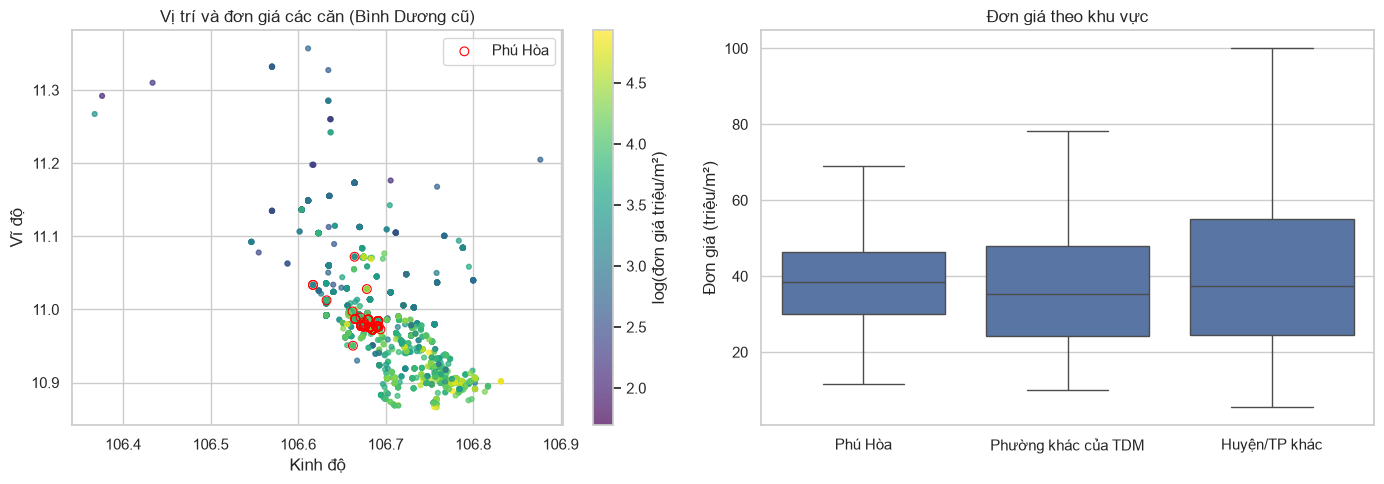

**Quan sát:** Đơn giá phụ thuộc mạnh vào vị trí: trung vị cao nhất ở Dĩ An, Thuận An, Thủ Dầu Một và thấp nhất ở Bắc Tân Uyên, Dầu Tiếng. Phú Hòa có đơn giá trung vị 38,5 triệu/m², đứng thứ 6/11 phường Thủ Dầu Một có từ 20 căn trở lên (các phường khác của TDM 35,4, huyện/TP khác 37,5 triệu/m²). Ngay trong Thủ Dầu Một đơn giá đã chênh nhiều giữa các phường, nên mô hình cần đặc trưng **giá khu vực** chứ không chỉ "tên phường".

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
sc = ax.scatter(df["lon"], df["lat"], c=np.log(df["don_gia"]), cmap="viridis", s=12, alpha=0.7)
ph = df[df["phu_hoa"] == 1]
ax.scatter(ph["lon"], ph["lat"], facecolors="none", edgecolors="red", s=40, lw=0.8, label="Phú Hòa")
cb = plt.colorbar(sc, ax=ax); cb.set_label("log(đơn giá triệu/m²)")
ax.set(title="Vị trí và đơn giá các căn (Bình Dương cũ)", xlabel="Kinh độ", ylabel="Vĩ độ"); ax.legend()
ax = axes[1]
nhom = np.where(df["phu_hoa"] == 1, "Phú Hòa", np.where(df["tdm"] == 1, "Phường khác của TDM", "Huyện/TP khác"))
sns.boxplot(x=nhom, y=df["don_gia"], ax=ax, showfliers=False, order=["Phú Hòa", "Phường khác của TDM", "Huyện/TP khác"])
ax.set(title="Đơn giá theo khu vực", ylabel="Đơn giá (triệu/m²)", xlabel="")
plt.tight_layout(); plt.show()
dg_quan = df.groupby("quan")["don_gia"].median().sort_values(ascending=False)
dg_ph = df[df["tdm"] == 1].groupby("phuong")["don_gia"].agg(["median", "size"]).query("size >= 20")["median"].sort_values(ascending=False)   # phường < 20 căn: chưa đủ mẫu
ten_q = {ten_quan(q): re.sub(r"^(Thành phố|Thị xã|Huyện)\s+", "", q) for q in raw_chotot["quan_huyen"].dropna().unique()}   # tên có dấu để in
dg_vung = df.groupby(nhom)["don_gia"].median()
nx(f'''**Quan sát:** Đơn giá phụ thuộc mạnh vào vị trí: trung vị cao nhất ở {", ".join(ten_q.get(q, q) for q in dg_quan.index[:3])} và thấp nhất ở {", ".join(ten_q.get(q, q) for q in dg_quan.index[-2:])}. Phú Hòa có đơn giá trung vị {vn(dg_vung["Phú Hòa"])} triệu/m², đứng thứ {list(dg_ph.index).index("phu hoa") + 1}/{len(dg_ph)} phường Thủ Dầu Một có từ 20 căn trở lên (các phường khác của TDM {vn(dg_vung["Phường khác của TDM"])}, huyện/TP khác {vn(dg_vung["Huyện/TP khác"])} triệu/m²). Ngay trong Thủ Dầu Một đơn giá đã chênh nhiều giữa các phường, nên mô hình cần đặc trưng **giá khu vực** chứ không chỉ "tên phường".''')

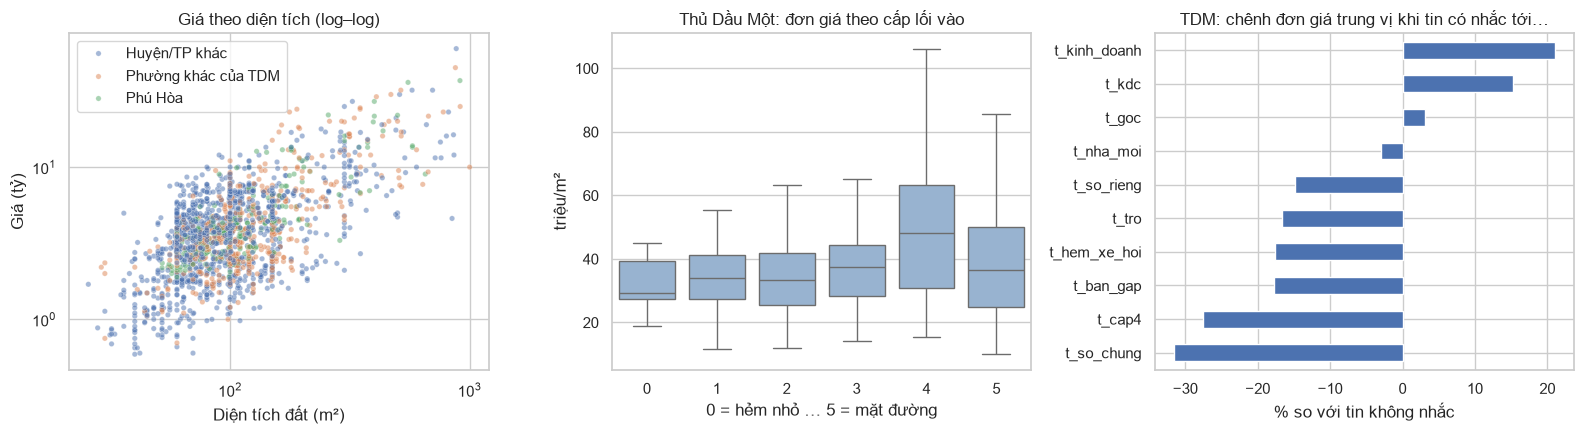

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.scatterplot(data=df, x="dt_dat", y="gia_ty", hue=nhom, alpha=0.5, s=15, ax=axes[0])
axes[0].set(xscale="log", yscale="log", title="Giá theo diện tích (log–log)", xlabel="Diện tích đất (m²)", ylabel="Giá (tỷ)")
lv = df.dropna(subset=["cap_loi_vao"]).assign(cap=lambda d: d["cap_loi_vao"].round().astype(int))
sns.boxplot(data=lv[lv["tdm"] == 1], x="cap", y="don_gia", showfliers=False, ax=axes[1], color="#8fb3d9")
axes[1].set(title="Thủ Dầu Một: đơn giá theo cấp lối vào", xlabel="0 = hẻm nhỏ … 5 = mặt đường", ylabel="triệu/m²")
anh_huong = {}
for c_ in ["t_kdc", "t_hem_xe_hoi", "t_so_rieng", "t_nha_moi", "t_cap4", "t_tro", "t_ban_gap", "t_so_chung", "t_kinh_doanh", "t_goc"]:
    co_, khong_ = tdm[tdm[c_] == 1]["don_gia"].median(), tdm[tdm[c_] == 0]["don_gia"].median()
    anh_huong[c_] = (co_ / khong_ - 1) * 100
pd.Series(anh_huong).sort_values().plot.barh(ax=axes[2], color="#4C72B0")
axes[2].set(title="TDM: chênh đơn giá trung vị khi tin có nhắc tới…", xlabel="% so với tin không nhắc")
plt.tight_layout(); plt.show()

**Quan sát:**
- Giá theo diện tích vẫn gần tuyến tính trên thang log–log → học trên **log(giá)** là hợp lý (sai số được đo theo tỷ lệ %).
- Đơn giá tăng theo cấp lối vào: hẻm nhỏ < hẻm xe hơi < mặt đường.
- Từ khóa trong mô tả có liên hệ rõ với đơn giá. Đây chỉ là so sánh thô (chưa tách ảnh hưởng của diện tích, vị trí), nên mô hình ở Bước 7–8 sẽ ước lượng tác động thật sự.

### 5.1 Phân cụm khu vực giá bằng K-means (học không giám sát)
Như các bài thực hành TH12–TH15: không dùng nhãn, gom các căn ở Thủ Dầu Một thành K cụm theo **vị trí (vĩ độ, kinh độ) và log(đơn giá)** đã chuẩn hóa. Chọn K bằng **phương pháp Elbow** (tổng bình phương khoảng cách trong cụm – inertia) kết hợp **hệ số Silhouette** (càng gần 1 thì các cụm càng tách bạch). Kết quả cho biết thị trường tự chia thành những "vùng giá" nào – chính là lý do Phần B cần đặc trưng giá khu vực. Phân cụm chỉ để khám phá, **không** đưa vào mô hình.

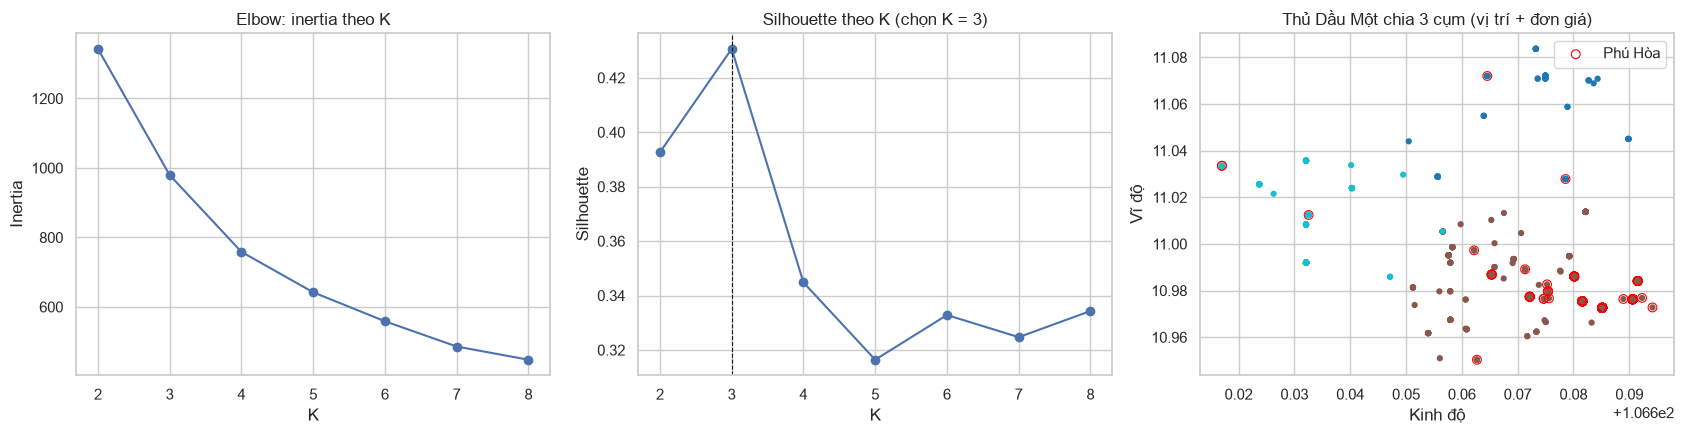

Silhouette với K = 3: 0.43


,so_can,don_gia_tv,ty_le_phu_hoa,phuong_chinh
cum,,,,
0,62,40.7,3.2,hoa phu
1,441,40.6,48.8,phu hoa
2,204,24.8,2.0,chanh my


In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

Z = StandardScaler().fit_transform(np.column_stack([tdm["lat"], tdm["lon"], np.log(tdm["don_gia"])]))
CAC_K = list(range(2, 9))
km = {k: KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z) for k in CAC_K}
sil = [silhouette_score(Z, km[k].labels_) for k in CAC_K]
K_CUM = CAC_K[int(np.argmax(sil))]
cum = km[K_CUM].labels_

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(CAC_K, [km[k].inertia_ for k in CAC_K], "o-"); axes[0].set(title="Elbow: inertia theo K", xlabel="K", ylabel="Inertia")
axes[1].plot(CAC_K, sil, "o-"); axes[1].axvline(K_CUM, color="k", ls="--", lw=0.8)
axes[1].set(title=f"Silhouette theo K (chọn K = {K_CUM})", xlabel="K", ylabel="Silhouette")
sc = axes[2].scatter(tdm["lon"], tdm["lat"], c=cum, cmap="tab10", s=12)
p_ = tdm["phu_hoa"] == 1
axes[2].scatter(tdm.loc[p_, "lon"], tdm.loc[p_, "lat"], facecolors="none", edgecolors="red", s=40, lw=0.8, label="Phú Hòa")
axes[2].set(title=f"Thủ Dầu Một chia {K_CUM} cụm (vị trí + đơn giá)", xlabel="Kinh độ", ylabel="Vĩ độ"); axes[2].legend()
plt.tight_layout(); plt.show()
bang_cum = (tdm.assign(cum=cum).groupby("cum")
            .agg(so_can=("y", "size"), don_gia_tv=("don_gia", "median"), ty_le_phu_hoa=("phu_hoa", "mean"),
                 phuong_chinh=("phuong", lambda s: s.value_counts().index[0]))
            .sort_values("don_gia_tv", ascending=False))
bang_cum["ty_le_phu_hoa"] *= 100
print(f"Silhouette với K = {K_CUM}: {max(sil):.2f}"); display(bang_cum.round(1))

In [13]:
cao, thap = bang_cum.iloc[0], bang_cum.iloc[-1]
ph_cao = ((tdm["phu_hoa"].to_numpy() == 1) & (cum == bang_cum.index[0])).sum() / (tdm["phu_hoa"] == 1).sum() * 100
nx(f'''**Quan sát:** Silhouette cao nhất ở K = {K_CUM} (≈ {vn(max(sil), 2)}). Thủ Dầu Một tách thành **vùng giá cao** ({int(cao.so_can)} căn, đơn giá trung vị ≈ {vn(cao.don_gia_tv, 0)} triệu/m²; {vn(ph_cao, 0)}% số căn Phú Hòa nằm trong cụm này) và **vùng giá thấp nhất** ({int(thap.so_can)} căn, ≈ {vn(thap.don_gia_tv, 0)} triệu/m², nhiều nhất ở phường "{thap.phuong_chinh}"). {"Silhouette dưới 0,5 (cấu trúc cụm yếu) và đường Elbow không có “khuỷu” rõ: thị trường không chia thành các khối tách bạch mà thay đổi **liên tục** theo vị trí. Vì vậy mô hình mô tả vị trí bằng đại lượng liên tục (tọa độ, khoảng cách tới trung tâm) thay vì gán nhãn cụm; mô hình đối chứng ở Phần B thêm đơn giá của các căn lân cận." if max(sil) < 0.5 else "Các cụm tách khá rõ (Silhouette ≥ 0,5); Phần B vẫn dùng đơn giá của các căn lân cận vì con số liên tục giữ được nhiều thông tin hơn nhãn cụm."}''')

**Quan sát:** Silhouette cao nhất ở K = 3 (≈ 0,43). Thủ Dầu Một tách thành **vùng giá cao** (62 căn, đơn giá trung vị ≈ 41 triệu/m²; 1% số căn Phú Hòa nằm trong cụm này) và **vùng giá thấp nhất** (204 căn, ≈ 25 triệu/m², nhiều nhất ở phường "chanh my"). Silhouette dưới 0,5 (cấu trúc cụm yếu) và đường Elbow không có “khuỷu” rõ: thị trường không chia thành các khối tách bạch mà thay đổi **liên tục** theo vị trí. Vì vậy mô hình mô tả vị trí bằng đại lượng liên tục (tọa độ, khoảng cách tới trung tâm) thay vì gán nhãn cụm; mô hình đối chứng ở Phần B thêm đơn giá của các căn lân cận.

## Bước 6: Chia tập huấn luyện (train) và tập kiểm tra (test)
Như bài giảng: mô hình học trên tập **train**, rồi được chấm trên tập **test** gồm những căn nó **chưa từng thấy**. Chấm trên chính dữ liệu đã học sẽ cho kết quả đẹp giả (mô hình chỉ "nhớ bài").

- **Tập test** = 20% số căn ở Thủ Dầu Một, giữ riêng, không dùng cho bất kỳ quyết định nào (chọn mô hình, chọn tham số).
- **Không rò rỉ:** cùng một căn thường được đăng nhiều lần. Các tin gần trùng (cột `nhom`, Bước 4) luôn được chia **về cùng một phía**, nếu không mô hình sẽ "gặp lại" căn đang kiểm tra dưới một tin khác. Vì vậy dùng `StratifiedGroupKFold` (lấy 1 trong 5 phần = 20%) thay cho `train_test_split` của bài thực hành: vừa chia **theo nhóm**, vừa **phân tầng** (stratify, như tham số `stratify=` của `train_test_split`) theo Phú Hòa / không Phú Hòa, để tập test luôn có tỷ lệ căn Phú Hòa giống toàn bộ dữ liệu. Chia ngẫu nhiên thuần túy (`GroupShuffleSplit`) thì số căn Phú Hòa trong test dao động mạnh theo hạt giống ngẫu nhiên (ô dưới in thử 5 hạt giống), mà Phú Hòa là nơi cần đánh giá.

In [14]:
from sklearn.model_selection import StratifiedGroupKFold

idx_tdm = df.index[df["tdm"] == 1].to_numpy()
# 1 trong 5 phần (20%), chia theo nhóm tin gần trùng và phân tầng theo Phú Hòa -> tập test có tỷ lệ căn Phú Hòa như toàn bộ
_, vt_test = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
                  .split(idx_tdm, y=df.loc[idx_tdm, "phu_hoa"], groups=df.loc[idx_tdm, "nhom"]))
df["tap"] = np.where(df.index.isin(idx_tdm[vt_test]), "test", "train")
train, test = df[df["tap"] == "train"].reset_index(drop=True), df[df["tap"] == "test"].reset_index(drop=True)
from sklearn.model_selection import GroupShuffleSplit
so_ph = [int(df.loc[idx_tdm[v], "phu_hoa"].sum()) for v in (next(GroupShuffleSplit(1, test_size=0.2, random_state=h).split(idx_tdm, groups=df.loc[idx_tdm, "nhom"]))[1] for h in range(5))]
print(f"So sánh: chia ngẫu nhiên theo nhóm với 5 hạt giống cho {so_ph} căn Phú Hòa trong test; chia phân tầng cho {int(test['phu_hoa'].sum())} căn.")
assert not set(train["nhom"]) & set(test["nhom"])            # không nhóm nào nằm ở cả hai tập
pd.crosstab(df["tap"], np.where(df["phu_hoa"] == 1, "Phú Hòa", np.where(df["tdm"] == 1, "TDM khác", "Ngoài TDM")))

So sánh: chia ngẫu nhiên theo nhóm với 5 hạt giống cho [49, 61, 35, 41, 38] căn Phú Hòa trong test; chia phân tầng cho 44 căn.


col_0,Ngoài TDM,Phú Hòa,TDM khác
tap,,,
test,0,44,98
train,1175,177,388


## Bước 7: Các mô hình học có giám sát trong môn học
Mọi mô hình dưới đây đều nằm trong bài giảng hoặc bài thực hành, cùng một mốc so sánh tối thiểu:

| Mô hình | Nguồn trong môn học | Ý tưởng |
|---|---|---|
| Baseline – đơn giá phường | – | Giá = đơn giá trung vị của phường × diện tích. Mô hình học máy phải vượt mốc này mới có ý nghĩa |
| Hồi quy tuyến tính | Thực hành TH6 | log(giá) = tổng có trọng số của các đặc trưng |
| **Cây quyết định** | Bài giảng 3, TH9/TH10 | Chia dữ liệu bằng các câu hỏi if-then trên đặc trưng; mỗi lá cho một mức giá |
| k láng giềng gần nhất (KNN) | Thực hành TH10 | Giá = trung bình giá của k căn giống nhất (khoảng cách trên các đặc trưng đã chuẩn hóa) |
| **SVM hồi quy (SVR)** | Bài giảng 6, TH10 | Tìm hàm có lề rộng nhất sao cho phần lớn điểm lệch không quá ε; kernel RBF cho quan hệ phi tuyến |
| **Mạng nơ-ron nhiều lớp (MLP)** | Bài giảng 4 | Các nơ-ron sigmoid/ReLU xếp thành lớp ẩn, học trọng số bằng **gradient descent + lan truyền ngược (backpropagation)** |
| Random Forest | Thực hành TH10 | Trung bình của nhiều cây, mỗi cây học trên một mẫu bootstrap và một phần đặc trưng → giảm phương sai của cây đơn |

**Đặc trưng:** thông số căn nhà (log diện tích, ngang, dài, số tầng, diện tích sàn, phòng ngủ, WC, mặt tiền, cấp lối vào, độ rộng hẻm, sổ chung, nội thất), vị trí (vĩ độ, kinh độ, khoảng cách tới trung tâm) và 21 từ khóa đọc từ mô tả (Bước 3). Mục tiêu là **log(giá)**, vì với giá nhà sai số tính theo % mới có ý nghĩa (Bước 5). Ô thiếu được điền bằng trung vị **của tập train** (như bài thực hành tiền xử lý TH4). KNN, SVR và MLP dựa trên khoảng cách / gradient nên cần **chuẩn hóa** đặc trưng (StandardScaler) trước.

**Cây quyết định cho bài toán hồi quy.** Bài giảng trình bày ID3 cho bài toán phân lớp: ở mỗi nút chọn thuộc tính có **information gain** lớn nhất, tức làm **entropy** của nhãn giảm nhiều nhất. Với giá (một số liên tục), ý tưởng giữ nguyên nhưng độ "lẫn lộn" của một nút đo bằng **phương sai** (sai số bình phương) của giá trong nút thay cho entropy: cây chọn ngưỡng chia làm phương sai giảm nhiều nhất, và mỗi lá dự đoán giá trung bình của các căn trong lá.

**Quá khớp (overfitting) và cắt tỉa cây.** Cây càng sâu càng khớp tập train, nhưng tới một mức thì sai số trên dữ liệu mới **tăng lên**: cây bắt đầu học thuộc nhiễu. Bài giảng dùng một **tập kiểm định** (validation) để quyết định cắt tỉa (reduced-error pruning). Ở đây giới hạn độ sâu tối đa và chọn độ sâu theo sai số trên tập kiểm định (kiểm định chéo 5-fold trên tập train, như TH10), không dùng tập test. Số láng giềng k của KNN được chọn theo cùng cách; SVR (C, ε, γ) và MLP (số nơ-ron, hệ số phạt α) có nhiều siêu tham số nên dò lưới bằng `GridSearchCV` như TH11, trên cùng 5 fold.

> Chia fold **theo nhóm tin gần trùng** (GroupKFold) là kỹ thuật nâng cao (giải thích ở Phần B); về bản chất vẫn là kiểm định chéo K-fold của bài thực hành, chỉ thêm điều kiện các tin của cùng một căn không bị tách ra hai phía.

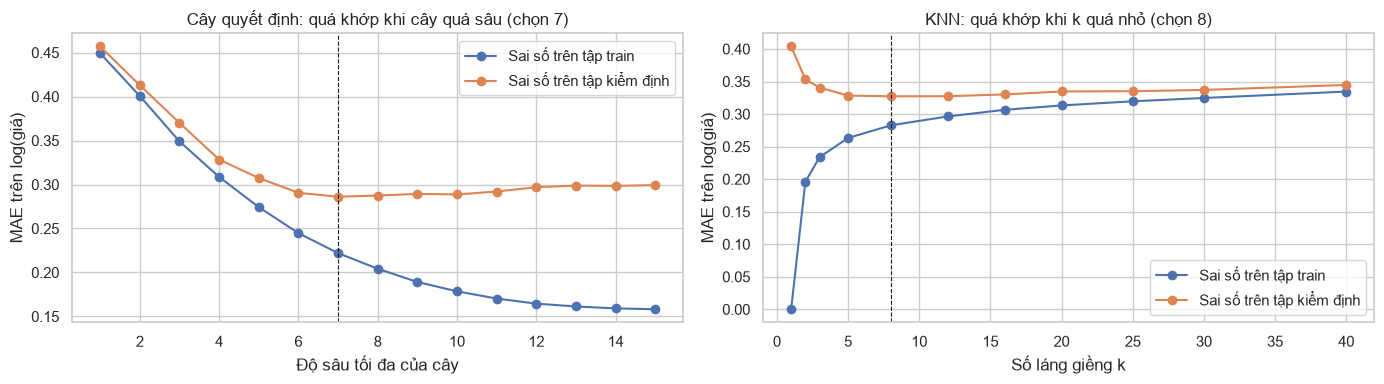

Độ sâu cây tốt nhất: 7 | số láng giềng tốt nhất: k = 8


SVR chọn được: {'svr__C': 1, 'svr__epsilon': 0.05, 'svr__gamma': 0.01}
MLP chọn được: {'mlpregressor__alpha': 1.0, 'mlpregressor__hidden_layer_sizes': (32, 16)}
Random Forest chọn được: {'randomforestregressor__max_features': 0.7, 'randomforestregressor__min_samples_leaf': 1}


In [15]:
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from mo_hinh_gia import bang_danh_gia

DT_CO_BAN = ["log_dt", "ngang", "dai", "so_tang", "dt_san", "ty_le_san", "phong_ngu", "so_wc", "mat_tien_duong",
             "cap_loi_vao", "hem_rong", "so_chung", "noi_that", "lat", "lon", "kc_trung_tam_km"] + CO_CHU
Xtr, ytr = train[DT_CO_BAN].astype(float), train["y"].to_numpy()
Xte = test[DT_CO_BAN].astype(float)
cay = lambda d: make_pipeline(SimpleImputer(strategy="median"), DecisionTreeRegressor(max_depth=d, min_samples_leaf=5, random_state=0))
knn = lambda k: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsRegressor(n_neighbors=k))
FOLD = list(GroupKFold(5, shuffle=True, random_state=RANDOM_STATE).split(Xtr, groups=train["nhom"]))   # 5 fold chung cho mọi mô hình

def mae_cheo(tao):
    # Kiểm định chéo 5-fold trên tập train: trả về (MAE trên phần học, MAE trên phần kiểm định), đo trên log(giá)
    tr_, va_ = [], []
    for a, b in FOLD:
        m = tao().fit(Xtr.iloc[a], ytr[a])
        tr_.append(np.mean(np.abs(m.predict(Xtr.iloc[a]) - ytr[a]))); va_.append(np.mean(np.abs(m.predict(Xtr.iloc[b]) - ytr[b])))
    return np.mean(tr_), np.mean(va_)

DO_SAU, SO_K = list(range(1, 16)), [1, 2, 3, 5, 8, 12, 16, 20, 25, 30, 40]
loi_cay = np.array([mae_cheo(lambda: cay(d)) for d in DO_SAU])
loi_knn = np.array([mae_cheo(lambda: knn(k)) for k in SO_K])
DO_SAU_TOT, K_TOT = DO_SAU[int(np.argmin(loi_cay[:, 1]))], SO_K[int(np.argmin(loi_knn[:, 1]))]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, x, loi, tot, ten, nhan in [(axes[0], DO_SAU, loi_cay, DO_SAU_TOT, "Cây quyết định: quá khớp khi cây quá sâu", "Độ sâu tối đa của cây"),
                                   (axes[1], SO_K, loi_knn, K_TOT, "KNN: quá khớp khi k quá nhỏ", "Số láng giềng k")]:
    ax.plot(x, loi[:, 0], "o-", label="Sai số trên tập train"); ax.plot(x, loi[:, 1], "o-", label="Sai số trên tập kiểm định")
    ax.axvline(tot, color="k", ls="--", lw=0.8); ax.set(title=f"{ten} (chọn {tot})", xlabel=nhan, ylabel="MAE trên log(giá)"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Độ sâu cây tốt nhất: {DO_SAU_TOT} | số láng giềng tốt nhất: k = {K_TOT}")

# SVR và MLP có nhiều siêu tham số: dò lưới bằng GridSearchCV (như TH11) trên cùng 5 fold của tập train
def do_luoi(pipe, luoi):
    return GridSearchCV(pipe, luoi, cv=FOLD, scoring="neg_mean_absolute_error").fit(Xtr, ytr).best_params_
TS_SVR = do_luoi(make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), SVR()),
                 {"svr__C": [0.3, 1, 3, 10], "svr__epsilon": [0.05, 0.1], "svr__gamma": ["scale", 0.01]})
TS_MLP = do_luoi(make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), MLPRegressor(early_stopping=True, max_iter=2000, random_state=0)),
                 {"mlpregressor__hidden_layer_sizes": [(16,), (32, 16), (64, 32)], "mlpregressor__alpha": [1e-3, 1e-1, 1.0]})
TS_RF = do_luoi(make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(300, n_jobs=-1, random_state=0)),
                {"randomforestregressor__max_features": [0.2, 0.4, 0.7], "randomforestregressor__min_samples_leaf": [1, 2, 5]})
print("SVR chọn được:", TS_SVR); print("MLP chọn được:", TS_MLP); print("Random Forest chọn được:", TS_RF)

In [16]:
# Các mô hình của môn học, với siêu tham số đã chọn bằng kiểm định chéo ở ô trên
MO_HINH_CO_BAN = {
    "Hồi quy tuyến tính": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()),
    f"Cây quyết định (độ sâu {DO_SAU_TOT})": lambda: cay(DO_SAU_TOT),
    f"KNN (k = {K_TOT})": lambda: knn(K_TOT),
    "SVM hồi quy (SVR, kernel RBF)": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), SVR()).set_params(**TS_SVR),
    "Mạng nơ-ron MLP": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                              MLPRegressor(early_stopping=True, max_iter=2000, random_state=0)).set_params(**TS_MLP),
    "Random Forest (300 cây)": lambda: make_pipeline(SimpleImputer(strategy="median"),
                                                     RandomForestRegressor(300, n_jobs=-1, random_state=0)).set_params(**TS_RF),
}
# Chọn mô hình bằng kiểm định chéo trên tập train (không nhìn tập test)
bang_cheo = pd.DataFrame({ten: mae_cheo(tao) for ten, tao in MO_HINH_CO_BAN.items()}, index=["MAE log – phần học", "MAE log – kiểm định"]).T
# Baseline trên cùng 5 fold (baseline cần cột phường và diện tích nên tính riêng)
bang_cheo.loc["Baseline (đơn giá phường)"] = [np.nan, np.mean([np.mean(np.abs(BaselineDonGiaPhuong().fit(train.iloc[a], ytr[a]).predict(train.iloc[b]) - ytr[b]))
                                                                for a, b in FOLD])]
bang_cheo["MAE ≈ sai số %"] = (np.exp(bang_cheo["MAE log – kiểm định"]) - 1) * 100
print("Kiểm định chéo 5-fold trên tập train (sắp theo sai số kiểm định):"); display(bang_cheo.sort_values("MAE log – kiểm định").round(3))
TOT_CO_BAN = bang_cheo.drop("Baseline (đơn giá phường)")["MAE log – kiểm định"].idxmin()
print(f"Mô hình cơ bản tốt nhất theo kiểm định chéo: {TOT_CO_BAN}")

Kiểm định chéo 5-fold trên tập train (sắp theo sai số kiểm định):


,MAE log – phần học,MAE log – kiểm định,MAE ≈ sai số %
Random Forest (300 cây),0.080,0.226,25.331
"SVM hồi quy (SVR, kernel RBF)",0.187,0.243,27.449
Mạng nơ-ron MLP,0.197,0.250,28.419
Hồi quy tuyến tính,0.250,0.255,29.060
Cây quyết định (độ sâu 7),0.222,0.286,33.127
KNN (k = 8),0.283,0.327,38.712
Baseline (đơn giá phường),NaN,0.341,40.608


Mô hình cơ bản tốt nhất theo kiểm định chéo: Random Forest (300 cây)


In [17]:
# Tập test KHÔNG dùng ở Phần A: mô hình tốt nhất được chấm trên tập test MỘT lần, ở Bước 9.
cay_tot = cay(DO_SAU_TOT).fit(Xtr, ytr)
print("Ba tầng đầu của cây quyết định (học trên toàn bộ tập train), dạng luật if-then (giá trị lá = log giá dự đoán):")
print(export_text(cay_tot.named_steps["decisiontreeregressor"], feature_names=DT_CO_BAN, max_depth=2))

Ba tầng đầu của cây quyết định (học trên toàn bộ tập train), dạng luật if-then (giá trị lá = log giá dự đoán):
|--- log_dt <= 5.12
|   |--- so_chung <= 0.50
|   |   |--- so_wc <= 2.50
|   |   |   |--- truncated branch of depth 5
|   |   |--- so_wc >  2.50
|   |   |   |--- truncated branch of depth 5
|   |--- so_chung >  0.50
|   |   |--- log_dt <= 4.28
|   |   |   |--- truncated branch of depth 5
|   |   |--- log_dt >  4.28
|   |   |   |--- truncated branch of depth 3
|--- log_dt >  5.12
|   |--- log_dt <= 5.66
|   |   |--- lat <= 11.06
|   |   |   |--- truncated branch of depth 5
|   |   |--- lat >  11.06
|   |   |   |--- truncated branch of depth 3
|   |--- log_dt >  5.66
|   |   |--- lat <= 11.10
|   |   |   |--- truncated branch of depth 5
|   |   |--- lat >  11.10
|   |   |   |--- truncated branch of depth 2



In [18]:
bc = bang_cheo.sort_values("MAE log – kiểm định")
pct = lambda t: vn(bc.loc[t, "MAE ≈ sai số %"], 0)
ml = [t for t in bc.index if not t.startswith("Baseline")]
cay_ = cay_tot.named_steps["decisiontreeregressor"].tree_
goc_cay = [DT_CO_BAN[cay_.feature[i]] for i in (0, cay_.children_left[0], cay_.children_right[0]) if cay_.feature[i] >= 0]
ten_mlp, ten_knn, ten_lr = "Mạng nơ-ron MLP", f"KNN (k = {K_TOT})", "Hồi quy tuyến tính"
mlp_kem = bc.loc[ten_mlp, "MAE log – kiểm định"] >= bc.loc[ten_lr, "MAE log – kiểm định"]
nx(f'''**Đọc kết quả phần cơ bản:**
- **Quá khớp** (bài giảng 3) thấy rõ ở cả hai đường cong: cây càng sâu, hay k càng nhỏ, thì sai số trên phần học càng giảm (KNN với k = 1 gần như "thuộc lòng" tập train) trong khi sai số kiểm định đi lên. Siêu tham số được chọn ở điểm sai số kiểm định thấp nhất: độ sâu {DO_SAU_TOT}, k = {K_TOT}.
- Các luật if-then ở gốc cây cho biết mô hình "hỏi" gì đầu tiên: `{goc_cay[0]}`, rồi `{"` và `".join(goc_cay[1:])}` (log_dt = log diện tích; lat = vĩ độ) – khớp với phần khám phá dữ liệu.
- **Dò lưới siêu tham số** (GridSearchCV) quan trọng với SVR và MLP: SVR chọn C = {TS_SVR["svr__C"]}, ε = {TS_SVR["svr__epsilon"]}, γ = {TS_SVR["svr__gamma"]}; MLP chọn lớp ẩn {TS_MLP["mlpregressor__hidden_layer_sizes"]} với hệ số phạt α = {TS_MLP["mlpregressor__alpha"]}; Random Forest chọn tỷ lệ đặc trưng mỗi lần tách max_features = {TS_RF["randomforestregressor__max_features"]}, số căn tối thiểu mỗi lá = {TS_RF["randomforestregressor__min_samples_leaf"]}.
- **Chọn mô hình bằng kiểm định chéo** (không nhìn tập test), xếp theo sai số kiểm định: {"; ".join(f"{t} ≈ {pct(t)}%" for t in ml)}. Mọi mô hình đều thắng baseline đơn giá phường (≈ {pct("Baseline (đơn giá phường)")}%).
- **Cây quyết định đơn lẻ** có **phương sai cao** (dữ liệu train đổi một chút là cấu trúc cây đổi hẳn). **Random Forest** trung bình 300 cây học trên các mẫu bootstrap khác nhau nên phương sai giảm – đúng lý do mô hình này được đưa vào TH10. Sai số phần học của Random Forest ({vn(bc.loc["Random Forest (300 cây)", "MAE log – phần học"], 3)}) thấp hơn nhiều so với kiểm định ({vn(bc.loc["Random Forest (300 cây)", "MAE log – kiểm định"], 3)}): nó khớp tập train khá sát, nhưng sai số trên dữ liệu mới vẫn là thước đo dùng để chọn.
- **Mạng nơ-ron MLP** {"chưa thắng" if mlp_kem else "thắng"} hồi quy tuyến tính: {vn(len(train), 0)} căn train với nhiều ô thiếu (điền trung vị) là ít cho một mạng học hàng trăm trọng số bằng gradient descent; mạng nơ-ron phát huy khi có nhiều dữ liệu hơn (như bài toán ảnh ở bài giảng 4). **KNN** {"kém nhất trong các mô hình học máy" if ml[-1] == ten_knn else "xếp thứ " + str(ml.index(ten_knn) + 1) + " trong " + str(len(ml)) + " mô hình"}: mọi đặc trưng có trọng số như nhau trong khoảng cách, kể cả 21 cờ từ khóa 0/1 ít liên quan, nên "căn giống nhất" theo KNN chưa chắc giống về giá.
- **Tập test chưa được dùng ở Phần A.** Mô hình được chọn được chấm trên tập test **một lần duy nhất**, ở Bước 9.

**Kết thúc phần cơ bản – mô hình cuối của đề tài: {TOT_CO_BAN}** (kiểm định chéo ≈ {pct(TOT_CO_BAN)}%, baseline ≈ {pct("Baseline (đơn giá phường)")}%). Đây là mô hình được lưu và dùng cho trang demo. Phần B đánh giá nó chặt chẽ hơn (kiểm định chéo lặp, khoảng tin cậy bootstrap), so với **một** mô hình đối chứng ngoài bài giảng, rồi dùng nó để tính khoảng giá và chẩn đoán từng căn.''')

**Đọc kết quả phần cơ bản:**
- **Quá khớp** (bài giảng 3) thấy rõ ở cả hai đường cong: cây càng sâu, hay k càng nhỏ, thì sai số trên phần học càng giảm (KNN với k = 1 gần như "thuộc lòng" tập train) trong khi sai số kiểm định đi lên. Siêu tham số được chọn ở điểm sai số kiểm định thấp nhất: độ sâu 7, k = 8.
- Các luật if-then ở gốc cây cho biết mô hình "hỏi" gì đầu tiên: `log_dt`, rồi `so_chung` và `log_dt` (log_dt = log diện tích; lat = vĩ độ) – khớp với phần khám phá dữ liệu.
- **Dò lưới siêu tham số** (GridSearchCV) quan trọng với SVR và MLP: SVR chọn C = 1, ε = 0.05, γ = 0.01; MLP chọn lớp ẩn (32, 16) với hệ số phạt α = 1.0; Random Forest chọn tỷ lệ đặc trưng mỗi lần tách max_features = 0.7, số căn tối thiểu mỗi lá = 1.
- **Chọn mô hình bằng kiểm định chéo** (không nhìn tập test), xếp theo sai số kiểm định: Random Forest (300 cây) ≈ 25%; SVM hồi quy (SVR, kernel RBF) ≈ 27%; Mạng nơ-ron MLP ≈ 28%; Hồi quy tuyến tính ≈ 29%; Cây quyết định (độ sâu 7) ≈ 33%; KNN (k = 8) ≈ 39%. Mọi mô hình đều thắng baseline đơn giá phường (≈ 41%).
- **Cây quyết định đơn lẻ** có **phương sai cao** (dữ liệu train đổi một chút là cấu trúc cây đổi hẳn). **Random Forest** trung bình 300 cây học trên các mẫu bootstrap khác nhau nên phương sai giảm – đúng lý do mô hình này được đưa vào TH10. Sai số phần học của Random Forest (0,080) thấp hơn nhiều so với kiểm định (0,226): nó khớp tập train khá sát, nhưng sai số trên dữ liệu mới vẫn là thước đo dùng để chọn.
- **Mạng nơ-ron MLP** thắng hồi quy tuyến tính: 1.740 căn train với nhiều ô thiếu (điền trung vị) là ít cho một mạng học hàng trăm trọng số bằng gradient descent; mạng nơ-ron phát huy khi có nhiều dữ liệu hơn (như bài toán ảnh ở bài giảng 4). **KNN** kém nhất trong các mô hình học máy: mọi đặc trưng có trọng số như nhau trong khoảng cách, kể cả 21 cờ từ khóa 0/1 ít liên quan, nên "căn giống nhất" theo KNN chưa chắc giống về giá.
- **Tập test chưa được dùng ở Phần A.** Mô hình được chọn được chấm trên tập test **một lần duy nhất**, ở Bước 9.

**Kết thúc phần cơ bản – mô hình cuối của đề tài: Random Forest (300 cây)** (kiểm định chéo ≈ 25%, baseline ≈ 41%). Đây là mô hình được lưu và dùng cho trang demo. Phần B đánh giá nó chặt chẽ hơn (kiểm định chéo lặp, khoảng tin cậy bootstrap), so với **một** mô hình đối chứng ngoài bài giảng, rồi dùng nó để tính khoảng giá và chẩn đoán từng căn.

---
# PHẦN B – ĐÁNH GIÁ SÂU VÀ ỨNG DỤNG MÔ HÌNH CUỐI
---

## Bước 8: Đánh giá mô hình cuối, so với một mô hình đối chứng

**Mô hình cuối là mô hình tốt nhất của Phần A** (trong các mô hình của môn học, chọn bằng kiểm định chéo), học trên đúng các đặc trưng của Phần A. Phần B không thay mô hình này mà:
- **Đánh giá chặt chẽ hơn:** kiểm định chéo 5-fold **lặp 3 lần** (3 cách chia khác nhau, chia theo nhóm tin gần trùng), mỗi căn được dự đoán 3 lần bởi mô hình không học nó. Mỗi chỉ số kèm **khoảng tin cậy 95%** (bootstrap theo nhóm): với số căn Phú Hòa không lớn trong tập train (in ở Bước 6), MAPE dao động vài điểm % chỉ do may rủi, nên chênh lệch nhỏ hơn mức đó **không có nghĩa**.
- **So với một mô hình đối chứng ngoài bài giảng:** LightGBM (gradient boosting) cộng đặc trưng **giá khu vực**. Nếu đối chứng không hơn **rõ** (khoảng tin cậy của chênh lệch chứa 0), dùng mô hình của môn học không làm mất độ chính xác đo được; nếu hơn rõ, kết luận nêu mức chênh.

Tập test vẫn chỉ dùng một lần, ở Bước 9.

**Giải thích nhanh các kỹ thuật dùng trong bài** (để trình bày):

| Kỹ thuật | Nói ngắn gọn | Vì sao cần |
|---|---|---|
| Học trên log(giá) | Mô hình dự đoán log của giá rồi đổi ngược bằng `exp` | Giá lệch phải; sai số được đo theo % chứ không theo tỷ đồng |
| Giá khu vực (`GiaLangGieng`, chỉ trong mô hình đối chứng) | Với mỗi căn, lấy đơn giá trung bình của 12 căn gần nhất / cùng phường / cùng đường **trong tập học** | Đưa "vị trí" vào mô hình bằng con số có nghĩa. Mỗi căn không được dùng giá của chính nó, nên không lộ đáp án |
| Gradient boosting (LightGBM, mô hình đối chứng) | Nhiều cây quyết định nhỏ học nối tiếp, cây sau sửa lỗi cây trước | Kỹ thuật mạnh ngoài bài giảng, dùng để kiểm tra mô hình của môn học có thua xa không |
| Ngoại lai theo khu vực (`lech_don_gia_khu_vuc`, dùng ở Bước 4.4) | Với mỗi căn, tìm 15 căn gần nhất bằng `BallTree` (cây chia không gian, khoảng cách trên mặt cầu – haversine), so log đơn giá của căn với trung vị của 15 căn đó | Đơn giá thật chênh vài lần giữa các vùng, nên ngoại lai phải so với hàng xóm chứ không với toàn bộ dữ liệu như IQR |
| Gom tin gần trùng (`nhom_gan_trung`, dùng ở Bước 4.4) | Hai tin cùng quận, diện tích lệch ≤ 3%, giá lệch ≤ 12% **và** có thêm bằng chứng (mô tả giống nhau – độ tương đồng cosine TF-IDF ≥ 0,45 – hoặc cùng kích thước, cùng đường) thì nối lại; các tin nối với nhau (trực tiếp hay qua tin khác) thành một nhóm (union-find) | Cùng một căn đăng nhiều lần không lọt sang cả train và test |
| StratifiedGroupKFold, GroupKFold (Bước 6–8) | Chia train/test và chia fold sao cho các tin cùng nhóm không bị tách ra (khi chia train/test còn phân tầng theo Phú Hòa) | Chống rò rỉ từ tin đăng lại; tập test có đủ căn Phú Hòa |
| Bootstrap | Lấy mẫu lại dữ liệu nhiều lần để xem chỉ số dao động bao nhiêu | Biết chênh lệch nào là thật, chênh lệch nào do may rủi |
| Khoảng hiệu chỉnh từ sai số ngoài-fold (ý tưởng conformal) | Lấy phân vị của sai số ngoài-fold làm biên của khoảng giá | Khoảng giá có độ phủ kiểm chứng được trên test (thực nghiệm, không phải bảo đảm lý thuyết) |

**Các mô hình trong bảng:**

| Mô hình | Vai trò |
|---|---|
| Baseline – đơn giá phường | Giá = đơn giá trung vị của phường × diện tích. Mốc tối thiểu phải vượt |
| Mô hình tốt nhất của Phần A (tên in ở ô dưới) | **Mô hình cuối**: đúng mô hình và đặc trưng của Phần A |
| LightGBM + giá khu vực | **Đối chứng** ngoài bài giảng |

**Chỉ số** (tính trên giá tỷ đồng): **MAPE** – sai số % trung bình; **MdAPE** – sai số % trung vị; **Trong ±10% / ±20%** – tỷ lệ căn đoán đúng trong biên độ đó; **R²**.

In [19]:
from sklearn.linear_model import Ridge
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from lightgbm import LGBMRegressor
from mo_hinh_gia import du_doan_cheo_lap, sai_so_tung_can, ktc_bootstrap

DAC_TRUNG = DT_CO_BAN                     # đặc trưng căn nhà như Phần A; mô hình đối chứng được MoHinhGia ghép thêm giá khu vực
lgb = lambda **k: LGBMRegressor(n_estimators=600, learning_rate=0.02, num_leaves=15, min_child_samples=10, subsample=0.8,
                                subsample_freq=1, colsample_bytree=0.6, reg_lambda=1.0, verbose=-1, random_state=0, n_jobs=1, **k)
TEN_DOI_CHUNG = "Đối chứng: LightGBM + giá khu vực"
MO_HINH = {
    "Baseline (đơn giá phường)": lambda: BaselineDonGiaPhuong(),
    # mô hình cuối: đúng mô hình tốt nhất của Phần A, cùng đặc trưng (khong_gian=False: không thêm giá khu vực)
    TOT_CO_BAN: lambda: MoHinhGia(MO_HINH_CO_BAN[TOT_CO_BAN](), DT_CO_BAN, khong_gian=False),
    TEN_DOI_CHUNG: lambda: MoHinhGia(lgb(), DAC_TRUNG),
}
SO_LAN = 3
OOF = {}
for ten, tao in MO_HINH.items():
    OOF[ten] = du_doan_cheo_lap(tao, train, so_lan=SO_LAN)       # 5-fold x 3 lần, chia theo nhóm
    print("xong:", ten)

la_ph, la_tdm = (train["phu_hoa"] == 1).to_numpy(), (train["tdm"] == 1).to_numpy()
bang_cv_ph = bang_danh_gia(train, OOF, la_ph).sort_values("MAPE (%)")
bang_cv_tdm = bang_danh_gia(train, OOF, la_tdm).sort_values("MAPE (%)")
print(f"Kiểm định chéo lặp {SO_LAN} lần – các căn PHÚ HÒA trong tập train:"); display(bang_cv_ph.round(2))
print(f"Kiểm định chéo lặp {SO_LAN} lần – các căn THỦ DẦU MỘT trong tập train:"); display(bang_cv_tdm.round(2))

xong: Baseline (đơn giá phường)


xong: Random Forest (300 cây)


xong: Đối chứng: LightGBM + giá khu vực


Kiểm định chéo lặp 3 lần – các căn PHÚ HÒA trong tập train:


,MAPE (%),MAPE thấp (95%),MAPE cao (95%),MdAPE (%),Trong ±10% (%),Trong ±20% (%),MAE (tỷ),R²,Số căn
Random Forest (300 cây),23.45,20.44,27.31,17.66,30.89,54.43,1.70,0.58,177.0
Đối chứng: LightGBM + giá khu vực,23.56,20.77,27.08,18.02,28.25,53.86,1.61,0.66,177.0
Baseline (đơn giá phường),30.70,26.08,36.14,23.35,22.79,43.31,1.83,0.66,177.0


Kiểm định chéo lặp 3 lần – các căn THỦ DẦU MỘT trong tập train:


,MAPE (%),MAPE thấp (95%),MAPE cao (95%),MdAPE (%),Trong ±10% (%),Trong ±20% (%),MAE (tỷ),R²,Số căn
Random Forest (300 cây),24.75,22.71,26.96,18.25,29.26,53.33,1.53,0.61,565.0
Đối chứng: LightGBM + giá khu vực,25.16,23.12,27.40,18.35,28.26,53.10,1.47,0.67,565.0
Baseline (đơn giá phường),37.26,33.90,40.75,27.81,20.18,38.05,2.00,0.50,565.0


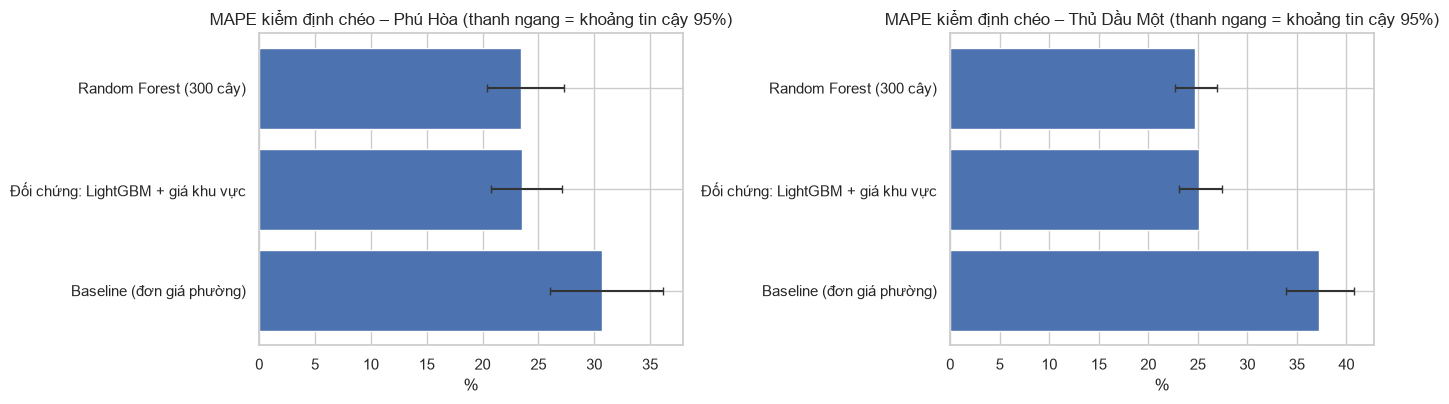

**Quan sát (Thủ Dầu Một):** mọi mô hình học máy đều vượt rõ baseline (khoảng tin cậy không chồng nhau). Giữa các mô hình học máy, khoảng tin cậy của mọi mô hình **chồng lên nhau**: thứ hạng trong bảng không đủ để kết luận mô hình nào tốt hơn. Vì vậy không chọn theo kiểu "ai đứng đầu bảng", mà dùng quy tắc dưới đây.

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, (ten, b) in zip(axes, [("Phú Hòa", bang_cv_ph), ("Thủ Dầu Một", bang_cv_tdm)]):
    b = b.sort_values("MAPE (%)", ascending=False)
    ax.barh(b.index, b["MAPE (%)"], color="#4C72B0",
            xerr=[b["MAPE (%)"] - b["MAPE thấp (95%)"], b["MAPE cao (95%)"] - b["MAPE (%)"]], capsize=3, ecolor="#333")
    ax.set(title=f"MAPE kiểm định chéo – {ten} (thanh ngang = khoảng tin cậy 95%)", xlabel="%")
plt.tight_layout(); plt.show()
bl_, b_ = "Baseline (đơn giá phường)", bang_cv_tdm
ml_cv = [t for t in b_.index if t != bl_]
vuot_bl = all(b_.loc[t, "MAPE cao (95%)"] < b_.loc[bl_, "MAPE thấp (95%)"] for t in ml_cv)
chong_ml = b_.loc[ml_cv, "MAPE thấp (95%)"].max() <= b_.loc[ml_cv, "MAPE cao (95%)"].min()
nx(f'''**Quan sát (Thủ Dầu Một):** {"mọi mô hình học máy đều vượt rõ baseline (khoảng tin cậy không chồng nhau)" if vuot_bl else "không phải mô hình học máy nào cũng vượt rõ baseline"}. Giữa các mô hình học máy, khoảng tin cậy {"của mọi mô hình **chồng lên nhau**" if chong_ml else "chồng nhau một phần"}: thứ hạng trong bảng không đủ để kết luận mô hình nào tốt hơn. Vì vậy không chọn theo kiểu "ai đứng đầu bảng", mà dùng quy tắc dưới đây.''')

### Mô hình cuối có kém mô hình đối chứng không?
So hai mô hình **trên cùng từng căn** (so sánh cặp): lấy chênh lệch sai số % của từng căn, tính khoảng tin cậy 95% bằng bootstrap theo nhóm, trên các căn Thủ Dầu Một (nhiều mẫu) và riêng các căn Phú Hòa. Khoảng tin cậy **chứa 0** nghĩa là chưa có bằng chứng hai mô hình khác nhau.

In [21]:
APE = {ten: sai_so_tung_can(train, P) for ten, P in OOF.items()}          # sai số % của từng căn, trung bình 3 lần lặp
ten_tot_nhat = TOT_CO_BAN                                                  # mô hình cuối = mô hình tốt nhất của môn học (Phần A)
ung_vien = [t for t in MO_HINH if not t.startswith("Baseline")]
diem = pd.Series({t: (APE[t][la_ph].mean() + APE[t][la_tdm].mean()) / 2 for t in ung_vien})
tot_nhat = diem.idxmin()                                                   # mô hình có MAPE trung bình thấp nhất (để đối chiếu)
nh_tr = train["nhom"].to_numpy()
so_sanh = []
for t in ung_vien:
    d_ = APE[t] - APE[ten_tot_nhat]
    kt_ = lambda m: (0.0, 0.0) if t == ten_tot_nhat else ktc_bootstrap(d_[m], nh_tr[m])
    (lo, hi), (lo_ph, hi_ph) = kt_(la_tdm), kt_(la_ph)
    so_sanh.append({"Mô hình": t, "MAPE TB (PH, TDM)": diem[t], "Chênh so với mô hình cuối (TDM)": d_[la_tdm].mean(), "KTC thấp": lo, "KTC cao": hi,
                    "Chênh so với mô hình cuối (PH)": d_[la_ph].mean(), "KTC thấp (PH)": lo_ph, "KTC cao (PH)": hi_ph})
so_sanh = pd.DataFrame(so_sanh).set_index("Mô hình")
display(so_sanh.round(2))

,"MAPE TB (PH, TDM)",Chênh so với mô hình cuối (TDM),KTC thấp,KTC cao,Chênh so với mô hình cuối (PH),KTC thấp (PH),KTC cao (PH)
Mô hình,,,,,,,
Random Forest (300 cây),24.10,0.0,0.00,0.00,0.00,0.00,0.00
Đối chứng: LightGBM + giá khu vực,24.36,0.4,-0.63,1.49,0.11,-1.84,1.96


In [22]:
dc = so_sanh.loc[TEN_DOI_CHUNG]
vung = [("Thủ Dầu Một", dc["Chênh so với mô hình cuối (TDM)"], dc["KTC thấp"], dc["KTC cao"]),
        ("Phú Hòa", dc["Chênh so với mô hình cuối (PH)"], dc["KTC thấp (PH)"], dc["KTC cao (PH)"])]
dc_hon_ro = [v for v, c, lo, hi in vung if hi < 0]
cuoi_hon_ro = [v for v, c, lo, hi in vung if lo > 0]
nx(f"**Đọc kết quả:** so với mô hình cuối ({ten_tot_nhat}), đối chứng sai "
   + "; ".join(f"{'ít' if c < 0 else 'nhiều'} hơn {vn(abs(c), 2)} điểm % trên {v} (KTC 95%: {vn(lo, 2)} … {vn(hi, 2)})" for v, c, lo, hi in vung) + "." + chr(10)
   + (f"- Đối chứng tốt hơn **rõ** ở {' và '.join(dc_hon_ro)}: đây là phần độ chính xác đánh đổi để giữ mô hình trong phạm vi môn học (dễ giải thích, không cần đặc trưng giá khu vực), cần nêu khi trình bày." if dc_hon_ro else
       f"- {'Mô hình cuối tốt hơn rõ ở ' + ' và '.join(cuoi_hon_ro) + '; ' if cuoi_hon_ro else ''}Không có vùng nào đối chứng tốt hơn rõ: **chưa có bằng chứng** kỹ thuật ngoài bài giảng tốt hơn mô hình của môn học, nên dùng {ten_tot_nhat} làm mô hình cuối không làm mất độ chính xác đo được."))

**Đọc kết quả:** so với mô hình cuối (Random Forest (300 cây)), đối chứng sai nhiều hơn 0,40 điểm % trên Thủ Dầu Một (KTC 95%: -0,63 … 1,49); nhiều hơn 0,11 điểm % trên Phú Hòa (KTC 95%: -1,84 … 1,96).
- Không có vùng nào đối chứng tốt hơn rõ: **chưa có bằng chứng** kỹ thuật ngoài bài giảng tốt hơn mô hình của môn học, nên dùng Random Forest (300 cây) làm mô hình cuối không làm mất độ chính xác đo được.

**Ba phép kiểm chứng cho mô hình cuối** (đều bằng kiểm định chéo lặp trên tập train):
- **Rò rỉ có ảnh hưởng không?** So MAPE khi chia fold ngẫu nhiên (tin gần trùng có thể nằm ở cả train lẫn test) với khi chia theo nhóm.
- **Học trên toàn vùng có hơn chỉ học trên Phú Hòa?**
- **So với cách làm của phiên bản 1** (Ridge trên 9 thông số, chỉ học các căn Phú Hòa).

In [23]:
P_thuong = du_doan_cheo_lap(MO_HINH[ten_tot_nhat], train, so_lan=SO_LAN, theo_nhom=False)
ph_train = train[la_ph].reset_index(drop=True)
P_chi_ph = du_doan_cheo_lap(MO_HINH[ten_tot_nhat], ph_train, so_lan=SO_LAN)

class PhienBan1:
    # Cách làm phiên bản 1: Ridge trên 9 thông số căn nhà
    COT = ["dt_dat", "ngang", "so_tang", "dt_san", "phong_ngu", "so_wc", "cap_loi_vao", "hem_rong", "noi_that"]
    def fit(self, X, y):
        self.m_ = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=3.0)).fit(X[self.COT], y); return self
    def predict(self, X):
        return self.m_.predict(X[self.COT])
P_v1 = du_doan_cheo_lap(PhienBan1, ph_train, so_lan=SO_LAN)

ape_chon = APE[ten_tot_nhat][la_ph]
kiem_chung = pd.DataFrame({
    f"{ten_tot_nhat} – học toàn vùng, chia theo nhóm (cách đánh giá chính)": bang_danh_gia(train, {"x": OOF[ten_tot_nhat]}, la_ph).iloc[0],
    f"{ten_tot_nhat} – học toàn vùng, chia NGẪU NHIÊN (có rò rỉ)": bang_danh_gia(train, {"x": P_thuong}, la_ph).iloc[0],
    f"{ten_tot_nhat} – chỉ học trên Phú Hòa": bang_danh_gia(ph_train, {"x": P_chi_ph}, np.ones(len(ph_train), bool)).iloc[0],
    "Cách làm phiên bản 1 (Ridge 9 thông số, chỉ Phú Hòa)": bang_danh_gia(ph_train, {"x": P_v1}, np.ones(len(ph_train), bool)).iloc[0],
}).T
display(kiem_chung.round(2))
nh = train["nhom"].to_numpy()[la_ph]
CHENH = {}
for nhan, ape_khac in [("chia ngẫu nhiên", sai_so_tung_can(train, P_thuong)[la_ph]), ("chỉ học Phú Hòa", sai_so_tung_can(ph_train, P_chi_ph)),
                       ("phiên bản 1", sai_so_tung_can(ph_train, P_v1))]:
    lo, hi = ktc_bootstrap(ape_khac - ape_chon, nh)
    CHENH[nhan] = (float(np.mean(ape_khac - ape_chon)), lo, hi)
    print(f"MAPE của '{nhan}' trừ MAPE cách chính: {np.mean(ape_khac - ape_chon):+.2f} điểm % (KTC 95%: {lo:+.2f} … {hi:+.2f})")

,MAPE (%),MAPE thấp (95%),MAPE cao (95%),MdAPE (%),Trong ±10% (%),Trong ±20% (%),MAE (tỷ),R²,Số căn
"Random Forest (300 cây) – học toàn vùng, chia theo nhóm (cách đánh giá chính)",23.45,20.44,27.31,17.66,30.89,54.43,1.70,0.58,177.0
"Random Forest (300 cây) – học toàn vùng, chia NGẪU NHIÊN (có rò rỉ)",22.76,19.80,26.45,16.77,32.58,56.87,1.66,0.58,177.0
Random Forest (300 cây) – chỉ học trên Phú Hòa,26.90,23.34,30.96,20.43,25.05,49.53,1.85,0.53,177.0
"Cách làm phiên bản 1 (Ridge 9 thông số, chỉ Phú Hòa)",28.73,22.74,37.44,18.40,29.19,53.48,2.10,-0.22,177.0


MAPE của 'chia ngẫu nhiên' trừ MAPE cách chính: -0.70 điểm % (KTC 95%: -1.59 … +0.12)
MAPE của 'chỉ học Phú Hòa' trừ MAPE cách chính: +3.45 điểm % (KTC 95%: +1.36 … +5.70)
MAPE của 'phiên bản 1' trừ MAPE cách chính: +5.28 điểm % (KTC 95%: -0.22 … +13.10)


In [24]:
ktc_ = lambda c: f"{vn(c[1], 2)} … {vn(c[2], 2)}"
chua_0 = lambda c: c[1] <= 0 <= c[2]
r_, p_, v_ = CHENH["chia ngẫu nhiên"], CHENH["chỉ học Phú Hòa"], CHENH["phiên bản 1"]
nx(f'''**Đọc kết quả** (chênh lệch có khoảng tin cậy không chứa 0 thì mới coi là thật):
- **Rò rỉ:** chia ngẫu nhiên cho MAPE {"thấp" if r_[0] < 0 else "cao"} hơn chia theo nhóm {vn(abs(r_[0]), 2)} điểm %, khoảng tin cậy ({ktc_(r_)}) {"chứa 0 → phần rò rỉ còn lại do tin đăng lại **không đáng kể** (tin trùng khớp hẳn đã gộp ở Bước 4.2)" if chua_0(r_) else "không chứa 0 → tin đăng lại vẫn gây rò rỉ đo được"}. Con số báo cáo là con số **chia theo nhóm** (khắt khe hơn).
- **Phạm vi dữ liệu:** chỉ học trên Phú Hòa sai {"hơn" if p_[0] > 0 else "ít hơn"} học toàn vùng {vn(abs(p_[0]), 2)} điểm %, khoảng tin cậy ({ktc_(p_)}) {"chứa 0 → chưa đủ bằng chứng" if chua_0(p_) else "**không chứa 0** → khác biệt có ý nghĩa thống kê"}.
- **So với phiên bản 1:** cách làm phiên bản 1 sai {"hơn" if v_[0] > 0 else "ít hơn"} {vn(abs(v_[0]), 2)} điểm %, khoảng tin cậy ({ktc_(v_)}) {"chứa 0 → chưa đủ chắc chắn về mặt thống kê" if chua_0(v_) else "**không chứa 0** → khác biệt có ý nghĩa thống kê"}. Kết quả trên tập test ở Bước 9.''')

**Đọc kết quả** (chênh lệch có khoảng tin cậy không chứa 0 thì mới coi là thật):
- **Rò rỉ:** chia ngẫu nhiên cho MAPE thấp hơn chia theo nhóm 0,70 điểm %, khoảng tin cậy (-1,59 … 0,12) chứa 0 → phần rò rỉ còn lại do tin đăng lại **không đáng kể** (tin trùng khớp hẳn đã gộp ở Bước 4.2). Con số báo cáo là con số **chia theo nhóm** (khắt khe hơn).
- **Phạm vi dữ liệu:** chỉ học trên Phú Hòa sai hơn học toàn vùng 3,45 điểm %, khoảng tin cậy (1,36 … 5,70) **không chứa 0** → khác biệt có ý nghĩa thống kê.
- **So với phiên bản 1:** cách làm phiên bản 1 sai hơn 5,28 điểm %, khoảng tin cậy (-0,22 … 13,10) chứa 0 → chưa đủ chắc chắn về mặt thống kê. Kết quả trên tập test ở Bước 9.

## Bước 9: Kiểm tra lần cuối trên tập test
Tập test chưa được dùng ở bất kỳ bước nào (kể cả Phần A). Đây là **lần duy nhất** nó được dùng: chấm cùng lúc mô hình cuối (tốt nhất của Phần A), mô hình đối chứng, baseline và cách làm phiên bản 1. Vì chỉ có vài chục căn Phú Hòa, con số trên test **dao động mạnh** (xem khoảng tin cậy). Đây là **kết quả chính** của đề tài vì là bằng chứng sạch nhất; con số kiểm định chéo ở Bước 8 dùng để bổ trợ.

In [25]:
mo_hinh_tot = MO_HINH[ten_tot_nhat]().fit(train, train["y"])
doi_chung = MO_HINH[TEN_DOI_CHUNG]().fit(train, train["y"])
baseline = BaselineDonGiaPhuong().fit(train, train["y"])
v1 = PhienBan1().fit(ph_train, ph_train["y"])
p_test = {ten_tot_nhat: mo_hinh_tot.predict(test), TEN_DOI_CHUNG: doi_chung.predict(test),
          "Baseline (đơn giá phường)": baseline.predict(test), "Cách làm phiên bản 1 (Ridge, chỉ Phú Hòa)": v1.predict(test)}
m_ph, m_tdm = (test["phu_hoa"] == 1).to_numpy(), np.ones(len(test), bool)
bang_test_ph, bang_test_tdm = bang_danh_gia(test, p_test, m_ph), bang_danh_gia(test, p_test, m_tdm)
print("TẬP TEST – các căn Phú Hòa:"); display(bang_test_ph.round(2))
print("TẬP TEST – toàn bộ Thủ Dầu Một:"); display(bang_test_tdm.round(2))
cv_, te_ = bang_cv_ph.loc[ten_tot_nhat], bang_test_ph.loc[ten_tot_nhat]
print(f"Phú Hòa – kiểm định chéo: MAPE {cv_['MAPE (%)']:.1f}% (KTC {cv_['MAPE thấp (95%)']:.1f}–{cv_['MAPE cao (95%)']:.1f}) | "
      f"test: {te_['MAPE (%)']:.1f}% (KTC {te_['MAPE thấp (95%)']:.1f}–{te_['MAPE cao (95%)']:.1f}) → "
      + ("hai khoảng tin cậy chồng nhau: test không mâu thuẫn với kiểm định chéo (nhưng tập test nhỏ, khoảng tin cậy rộng)." if te_['MAPE thấp (95%)'] <= cv_['MAPE cao (95%)'] and cv_['MAPE thấp (95%)'] <= te_['MAPE cao (95%)']
         else "hai khoảng tin cậy KHÔNG chồng nhau: cần xem lại."))

TẬP TEST – các căn Phú Hòa:


,MAPE (%),MAPE thấp (95%),MAPE cao (95%),MdAPE (%),Trong ±10% (%),Trong ±20% (%),MAE (tỷ),R²,Số căn
Random Forest (300 cây),26.39,19.48,38.68,22.20,27.27,43.18,1.41,0.35,44.0
Đối chứng: LightGBM + giá khu vực,27.07,18.71,41.04,16.43,29.55,54.55,1.36,0.43,44.0
Baseline (đơn giá phường),26.06,17.92,38.48,20.50,29.55,47.73,1.34,0.41,44.0
"Cách làm phiên bản 1 (Ridge, chỉ Phú Hòa)",29.10,22.29,40.43,25.99,13.64,40.91,1.61,0.18,44.0


TẬP TEST – toàn bộ Thủ Dầu Một:


,MAPE (%),MAPE thấp (95%),MAPE cao (95%),MdAPE (%),Trong ±10% (%),Trong ±20% (%),MAE (tỷ),R²,Số căn
Random Forest (300 cây),26.40,22.03,31.62,19.92,27.46,50.00,1.73,0.50,142.0
Đối chứng: LightGBM + giá khu vực,25.55,21.17,30.83,19.73,28.87,50.70,1.64,0.50,142.0
Baseline (đơn giá phường),36.27,29.43,43.50,27.67,19.01,35.92,1.89,0.65,142.0
"Cách làm phiên bản 1 (Ridge, chỉ Phú Hòa)",38.04,30.59,47.22,30.26,18.31,36.62,2.43,-1.42,142.0


Phú Hòa – kiểm định chéo: MAPE 23.5% (KTC 20.4–27.3) | test: 26.4% (KTC 19.5–38.7) → hai khoảng tin cậy chồng nhau: test không mâu thuẫn với kiểm định chéo (nhưng tập test nhỏ, khoảng tin cậy rộng).


### MAPE trên tập test nghĩa là gì, minh họa bằng chính các căn Phú Hòa trong tập test
MAPE là **sai lệch trung bình tính theo %** giữa giá mô hình ước lượng và giá rao. Ví dụ MAPE 25% với một căn rao 4 tỷ nghĩa là trung bình mô hình lệch khoảng ±1 tỷ. Đây là **trung bình**: phần lớn căn lệch ít hơn (xem trung vị), còn vài căn lệch rất nhiều kéo con số lên. Bảng dưới lấy các căn **thật** của tập test ở các mức lệch khác nhau.

In [26]:
ph_te = test[m_ph].assign(gia_du_doan_ty=np.exp(p_test[ten_tot_nhat][m_ph]))
ph_te["lech_pt"] = (ph_te["gia_du_doan_ty"] / ph_te["gia_ty"] - 1) * 100
ph_te = ph_te.sort_values("lech_pt", key=np.abs).reset_index(drop=True)
n_ = len(ph_te)
vi_du = ph_te.iloc[[0, n_ // 4, n_ // 2, 3 * n_ // 4, n_ - 1]]                  # tốt nhất, 25%, giữa, 75%, tệ nhất
vi_du.insert(0, "Mức", ["Lệch ít nhất", "25% số căn lệch ít hơn", "Căn ở giữa (trung vị)", "75% số căn lệch ít hơn", "Lệch nhiều nhất"])
display(vi_du[["Mức", "tieu_de", "dt_dat", "gia_ty", "gia_du_doan_ty", "lech_pt"]].rename(columns={
    "tieu_de": "Tin rao", "dt_dat": "Đất (m²)", "gia_ty": "Giá rao (tỷ)", "gia_du_doan_ty": "Mô hình (tỷ)", "lech_pt": "Lệch (%)"}).round(2))
lech_ty = (ph_te["gia_du_doan_ty"] - ph_te["gia_ty"]).abs()
print(f"{n_} căn Phú Hòa trong tập test: một nửa số căn lệch ≤ {ph_te['lech_pt'].abs().median():.0f}% "
      f"(≤ {lech_ty.median():.2f} tỷ); {(ph_te['lech_pt'].abs() <= 20).mean() * 100:.0f}% số căn lệch ≤ 20%. "
      f"MAPE = trung bình mức lệch = {ph_te['lech_pt'].abs().mean():.1f}%, bị kéo lên bởi vài căn lệch nhiều.")

,Mức,Tin rao,Đất (m²),Giá rao (tỷ),Mô hình (tỷ),Lệch (%)
0,Lệch ít nhất,"Nhà mới 100% Phú Hòa, Thủ Dầu Một, 4.25 tỷ",140.0,4.25,4.25,-0.01
11,25% số căn lệch ít hơn,Bán Nhà riêng 52.1m2 có sẵn 52.1 m2 thổ cư giá...,52.1,2.34,2.56,9.55
22,Căn ở giữa (trung vị),Bán nhà mặt tiền đường Nguyễn Thái Bình - Thủ ...,101.0,4.00,3.08,-23.05
33,75% số căn lệch ít hơn,Nhà trệt lầu lững phú hòa mặt tiền 293 NTMk.nh...,120.0,2.99,4.16,39.18
43,Lệch nhiều nhất,"Nhà 1 trệt 2 lầu, 4PN, 100m2, 2.05 tỷ",100.0,2.05,5.14,150.92


44 căn Phú Hòa trong tập test: một nửa số căn lệch ≤ 22% (≤ 0.83 tỷ); 43% số căn lệch ≤ 20%. MAPE = trung bình mức lệch = 26.4%, bị kéo lên bởi vài căn lệch nhiều.


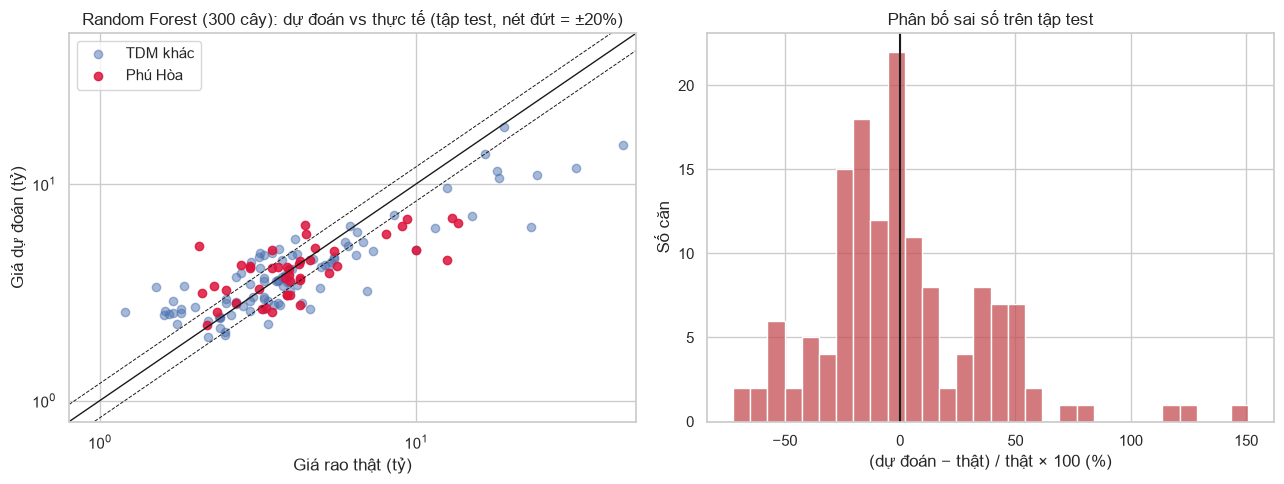

In [27]:
gia_that, gia_dd = test["gia_ty"].to_numpy(), np.exp(p_test[ten_tot_nhat])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
ax.scatter(gia_that[~m_ph], gia_dd[~m_ph], alpha=0.5, label="TDM khác")
ax.scatter(gia_that[m_ph], gia_dd[m_ph], alpha=0.85, color="crimson", label="Phú Hòa")
lim = [0.8, max(gia_that.max(), gia_dd.max()) * 1.1]
ax.plot(lim, lim, "k-", lw=1); ax.plot(lim, [v * 1.2 for v in lim], "k--", lw=0.7); ax.plot(lim, [v / 1.2 for v in lim], "k--", lw=0.7)
ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="Giá rao thật (tỷ)", ylabel="Giá dự đoán (tỷ)",
       title=f"{ten_tot_nhat}: dự đoán vs thực tế (tập test, nét đứt = ±20%)"); ax.legend()
sai_so = (gia_dd - gia_that) / gia_that * 100
sns.histplot(sai_so, bins=30, ax=axes[1], color="#C44E52"); axes[1].axvline(0, color="k")
axes[1].set(title="Phân bố sai số trên tập test", xlabel="(dự đoán − thật) / thật × 100 (%)", ylabel="Số căn")
plt.tight_layout(); plt.show()

In [28]:
A_, B0_, V1_ = TEN_DOI_CHUNG, "Baseline (đơn giá phường)", "Cách làm phiên bản 1 (Ridge, chỉ Phú Hòa)"
mp = lambda b, t: vn(b.loc[t, "MAPE (%)"])
chong = lambda b, a, c: b.loc[a, "MAPE thấp (95%)"] <= b.loc[c, "MAPE cao (95%)"] and b.loc[c, "MAPE thấp (95%)"] <= b.loc[a, "MAPE cao (95%)"]
tat_ca_chong = all(chong(bang_test_ph, ten_tot_nhat, t) for t in (A_, B0_, V1_))
thang_bl = not chong(bang_test_tdm, ten_tot_nhat, B0_) and bang_test_tdm.loc[ten_tot_nhat, "MAPE (%)"] < bang_test_tdm.loc[B0_, "MAPE (%)"]
AB_chong = chong(bang_test_ph, ten_tot_nhat, A_) and chong(bang_test_tdm, ten_tot_nhat, A_)
nx(f'''**Con số nên trình bày:** MAPE trên tập test kèm khoảng tin cậy (kết quả chính), cùng MAPE kiểm định chéo ở Bước 8 (bổ trợ).

**So sánh trên tập test.** Ở Phú Hòa ({int(bang_test_ph.loc[ten_tot_nhat, "Số căn"])} căn): mô hình cuối ({ten_tot_nhat}) {mp(bang_test_ph, ten_tot_nhat)}%, đối chứng {mp(bang_test_ph, A_)}%, phiên bản 1 {mp(bang_test_ph, V1_)}%, baseline {mp(bang_test_ph, B0_)}% – {"khoảng tin cậy của cả bốn chồng nhau, nên tập test Phú Hòa **không phân hạng được** các mô hình" if tat_ca_chong else "có mô hình khác biệt rõ với mô hình được chọn (khoảng tin cậy không chồng nhau)"}. Trên toàn Thủ Dầu Một ({int(bang_test_tdm.loc[ten_tot_nhat, "Số căn"])} căn): mô hình cuối {mp(bang_test_tdm, ten_tot_nhat)}%, đối chứng {mp(bang_test_tdm, A_)}%, baseline {mp(bang_test_tdm, B0_)}%, phiên bản 1 {mp(bang_test_tdm, V1_)}%.

**Kết luận trung thực:** mô hình cuối {"thắng rõ baseline trên toàn vùng" if thang_bl else "chưa thắng rõ baseline trên toàn vùng"}; so với mô hình đối chứng thì {"hai mô hình **ngang nhau** trên tập test (khoảng tin cậy chồng nhau): kỹ thuật ngoài bài giảng **không cho lợi ích chứng minh được** trên dữ liệu chưa thấy" if AB_chong else "khác biệt có ý nghĩa (khoảng tin cậy không chồng nhau)"}. Sai số cỡ {"–".join(dict.fromkeys(vn(v, 0) for v in sorted([bang_test_ph.loc[ten_tot_nhat, "MAPE (%)"], bang_test_tdm.loc[ten_tot_nhat, "MAPE (%)"]])))}% là của **giá rao bán**: cùng một căn có thể được các môi giới rao với giá khác nhau, người bán còn để "phần thương lượng". Phần sai số này nằm ở chính dữ liệu, mô hình không thể loại bỏ.''')

**Con số nên trình bày:** MAPE trên tập test kèm khoảng tin cậy (kết quả chính), cùng MAPE kiểm định chéo ở Bước 8 (bổ trợ).

**So sánh trên tập test.** Ở Phú Hòa (44 căn): mô hình cuối (Random Forest (300 cây)) 26,4%, đối chứng 27,1%, phiên bản 1 29,1%, baseline 26,1% – khoảng tin cậy của cả bốn chồng nhau, nên tập test Phú Hòa **không phân hạng được** các mô hình. Trên toàn Thủ Dầu Một (142 căn): mô hình cuối 26,4%, đối chứng 25,6%, baseline 36,3%, phiên bản 1 38,0%.

**Kết luận trung thực:** mô hình cuối chưa thắng rõ baseline trên toàn vùng; so với mô hình đối chứng thì hai mô hình **ngang nhau** trên tập test (khoảng tin cậy chồng nhau): kỹ thuật ngoài bài giảng **không cho lợi ích chứng minh được** trên dữ liệu chưa thấy. Sai số cỡ 26% là của **giá rao bán**: cùng một căn có thể được các môi giới rao với giá khác nhau, người bán còn để "phần thương lượng". Phần sai số này nằm ở chính dữ liệu, mô hình không thể loại bỏ.

### Mô hình có định giá lệch theo loại nhà không?
Kiểm tra **sai lệch có dấu** của dự đoán ngoài-fold (dương = mô hình đoán cao hơn giá rao) theo loại lối vào và theo mức giá. Nếu mô hình lệch có hệ thống với một loại nhà, trung vị sai lệch của loại đó sẽ xa 0.

In [29]:
tr_tdm = train[la_tdm].copy()
tr_tdm["lech_pt"] = (np.exp(OOF[ten_tot_nhat].mean(0)[la_tdm] - tr_tdm["y"]) - 1) * 100
tr_tdm["Loại"] = np.where(tr_tdm["mat_tien_duong"] == 1, "Mặt tiền đường", "Trong hẻm")
tr_tdm["Mức giá"] = pd.qcut(tr_tdm["gia_ty"], 4, labels=["Rẻ nhất 25%", "25–50%", "50–75%", "Đắt nhất 25%"])
tk = lambda g: g["lech_pt"].describe(percentiles=[.1, .5, .9])[["count", "10%", "50%", "90%"]]
display(tr_tdm.groupby("Loại").apply(tk).round(1)); display(tr_tdm.groupby("Mức giá", observed=True).apply(tk).round(1))

lech_pt,count,10%,50%,90%
Loại,,,,
Mặt tiền đường,273.0,-38.4,-3.7,47.2
Trong hẻm,292.0,-31.4,-0.5,37.5


lech_pt,count,10%,50%,90%
Mức giá,,,,
Rẻ nhất 25%,144.0,-4.1,18.7,66.0
25–50%,139.0,-21.5,-3.1,35.5
50–75%,141.0,-24.7,-8.1,30.3
Đắt nhất 25%,141.0,-48.9,-25.7,31.4


**Quan sát:**
- **Theo loại lối vào:** trung vị sai lệch của nhà mặt tiền và nhà trong hẻm đều gần 0, hai phân bố gần giống nhau → mô hình **không định giá lệch có hệ thống** với nhà mặt tiền.
- **Theo mức giá:** nhóm rao đắt nhất bị đoán thấp, nhóm rao rẻ nhất bị đoán cao. Đây là hiện tượng **co về trung bình**, có ở mọi mô hình khi chia nhóm theo chính giá rao: một căn rao rất cao một phần vì nó tốt thật, một phần vì người bán "hét giá", và mô hình chỉ thấy phần thứ nhất. Hệ quả: các căn bị chẩn đoán "cao hơn thị trường" ở Bước 11 gồm cả căn rao giá ảo lẫn căn có ưu điểm mô hình không thấy; cần xem tận nơi để phân biệt.

### Đặc trưng nào quan trọng?
Dùng **permutation importance theo nhóm** trên tập test: xáo trộn cùng lúc một nhóm cột rồi đo MAE trên log(giá) tăng bao nhiêu.

Mức tăng MAE (log giá) khi xáo trộn từng nhóm: {'Diện tích đất': 0.132, 'Số tầng, sàn, phòng, WC': 0.069, 'Vị trí (tọa độ, phường, đường)': 0.063, 'Lối vào (mặt tiền, hẻm)': 0.021, 'Mô tả tin (từ khóa + văn bản)': 0.017, 'Kích thước (ngang, dài)': 0.012}


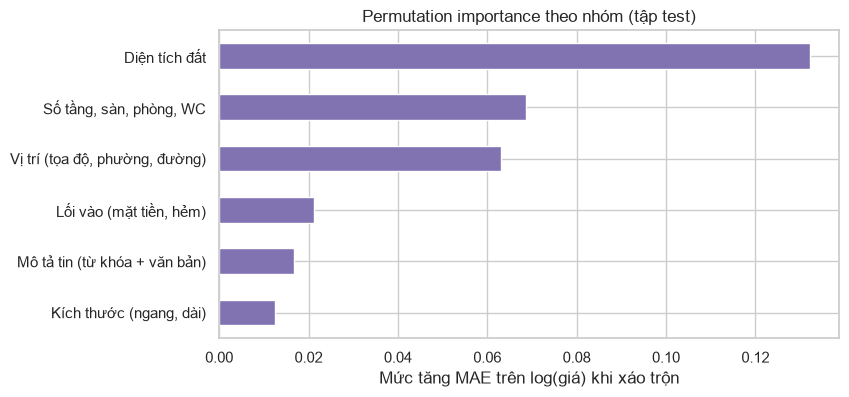

In [30]:
def mae_log(model, X):
    return np.mean(np.abs(model.predict(X) - X["y"].to_numpy()))

NHOM_DT = {
    "Diện tích đất": ["log_dt", "dt_dat"], "Kích thước (ngang, dài)": ["ngang", "dai"],
    "Số tầng, sàn, phòng, WC": ["so_tang", "dt_san", "ty_le_san", "phong_ngu", "so_wc"],
    "Lối vào (mặt tiền, hẻm)": ["mat_tien_duong", "cap_loi_vao", "hem_rong", "t_hem_xe_hoi", "t_hem_nho", "t_mat_tien"],
    "Vị trí (tọa độ, phường, đường)": ["lat", "lon", "kc_trung_tam_km", "phuong", "duong"],
    "Mô tả tin (từ khóa + văn bản)": [c for c in CO_CHU if c not in ("t_hem_xe_hoi", "t_hem_nho", "t_mat_tien")] + ["van_ban", "so_chung", "noi_that"],
}
goc = mae_log(mo_hinh_tot, test)
rng = np.random.default_rng(0)
pi = {}
for ten, cols in NHOM_DT.items():
    tang_ = []
    for _ in range(5):
        Xp = test.copy()
        perm = rng.permutation(len(Xp))
        for c_ in cols:
            Xp[c_] = Xp[c_].to_numpy()[perm]
        tang_.append(mae_log(mo_hinh_tot, Xp) - goc)
    pi[ten] = np.mean(tang_)
print("Mức tăng MAE (log giá) khi xáo trộn từng nhóm:", pd.Series(pi).sort_values(ascending=False).round(3).to_dict())
ax = pd.Series(pi).sort_values().plot.barh(color="#8172B2", figsize=(8, 4))
ax.set(title="Permutation importance theo nhóm (tập test)", xlabel="Mức tăng MAE trên log(giá) khi xáo trộn")
plt.show()

In [31]:
pi_ = pd.Series(pi).sort_values(ascending=False)
nx(f'''**Quan sát:** nhóm quan trọng nhất là **{pi_.index[0]}** (xáo trộn làm MAE log tăng ≈ {vn(pi_.iloc[0], 2)}), tiếp theo {", ".join(f"{k} (≈ {vn(v, 2)})" for k, v in pi_.iloc[1:4].items())}. Mô hình cuối thấy vị trí qua tọa độ, khoảng cách tới trung tâm và vài từ khóa trong mô tả (như "khu dân cư"), nên xáo riêng tọa độ đo được phần lớn, chưa phải toàn bộ, ảnh hưởng của vị trí.''')

**Quan sát:** nhóm quan trọng nhất là **Diện tích đất** (xáo trộn làm MAE log tăng ≈ 0,13), tiếp theo Số tầng, sàn, phòng, WC (≈ 0,07), Vị trí (tọa độ, phường, đường) (≈ 0,06), Lối vào (mặt tiền, hẻm) (≈ 0,02). Mô hình cuối thấy vị trí qua tọa độ, khoảng cách tới trung tâm và vài từ khóa trong mô tả (như "khu dân cư"), nên xáo riêng tọa độ đo được phần lớn, chưa phải toàn bộ, ảnh hưởng của vị trí.

## Bước 10: Khoảng giá 80% (hiệu chỉnh từ sai số ngoài-fold)
Một con số dự đoán đơn lẻ chưa đủ để ra quyết định. Ta muốn khoảng [thấp, cao] **chứa giá rao thật của khoảng 80% số căn**.

**Cách làm:** lấy sai số ngoài-fold của mô hình trên **các căn Thủ Dầu Một** trong tập train (cả 3 lần lặp), r = log(giá thật) − log(giá dự đoán). Phân vị 10% và 90% của r cho biên dưới/biên trên: khoảng = dự đoán × [e^q10, e^q90].

**Về tên gọi:** cách làm này mượn ý tưởng của *conformal prediction* (dùng phân vị sai số trên dữ liệu mô hình chưa thấy làm biên khoảng), nhưng **không phải** conformal "chuẩn" có bảo đảm lý thuyết: sai số lấy từ kiểm định chéo (ngoài-fold) trong khi khoảng được áp cho mô hình cuối huấn luyện trên toàn bộ dữ liệu, và dữ liệu có thể không hoán đổi được (tin đăng theo thời gian, theo khu). Vì vậy ta gọi đây là **khoảng hiệu chỉnh thực nghiệm** và chỉ tin vào nó qua **độ phủ quan sát được trên tập test riêng** (kèm kiểm định nhị thức), không tuyên bố bảo đảm 80%.

**Biên độ riêng theo mức giá (hiệu chỉnh theo nhóm, giống ý tưởng Mondrian conformal).** Nếu dùng một biên độ chung cho mọi căn, độ phủ trung bình đúng 80% nhưng **không đều**: nhà giá cao dao động mạnh hơn nên khoảng quá hẹp, nhà rẻ thì khoảng thừa rộng. Vì vậy chia các căn thành nhóm và tính phân vị sai số riêng cho từng nhóm: căn **Phú Hòa** – nơi cần định giá – là một nhóm riêng, được hiệu chỉnh bằng chính sai số ngoài-fold của các căn Phú Hòa trong tập train; các căn còn lại chia 4 mức theo **giá dự đoán** (tứ phân vị). Phân nhóm theo giá **dự đoán** (không theo giá thật) để dùng được cho căn mới chưa biết giá. Mọi biên độ chỉ tính từ sai số ngoài-fold của **tập train**; tập test chỉ dùng để kiểm tra độ phủ. Ô dưới so độ phủ từng nhóm giữa biên độ chung và biên độ theo nhóm.

In [32]:
from mo_hinh_gia import hieu_chinh_khoang, phan_vi_cho, nhom_khoang
P_tdm, Y_tdm = OOF[ten_tot_nhat][:, la_tdm], train["y"].to_numpy()[la_tdm]
NGUONG = np.quantile(P_tdm.mean(axis=0), [0.25, 0.5, 0.75]).tolist()          # ngưỡng 4 mức giá (log tỷ)
r = (Y_tdm - P_tdm).ravel()
la_ph_tdm = np.tile(train["phu_hoa"].to_numpy()[la_tdm] == 1, P_tdm.shape[0])  # căn Phú Hòa, lặp theo số lần kiểm định chéo
m_all = nhom_khoang(P_tdm.ravel(), NGUONG, la_ph_tdm)                       # nhóm: "ph" cho Phú Hòa, "0".."3" cho căn khác
KHOANG = hieu_chinh_khoang(r, m_all)
KHOANG["nguong"] = NGUONG
Q = KHOANG["chung"]                                                           # biên độ chung (để so sánh)

NHOM_KH = ["0", "1", "2", "3", "ph"]
ten_muc = ["Rẻ nhất 25% (ngoài Phú Hòa)", "25–50% (ngoài Phú Hòa)", "50–75% (ngoài Phú Hòa)", "Đắt nhất 25% (ngoài Phú Hòa)", "Phú Hòa (mọi mức giá)"]
q_rieng = phan_vi_cho(m_all, KHOANG)
so_sanh_kh = pd.DataFrame({
    "Số sai số ngoài-fold": [int((m_all == k).sum()) for k in NHOM_KH],
    "Độ phủ – biên độ chung (%)": [np.mean(((r >= Q["q10"]) & (r <= Q["q90"]))[m_all == k]) * 100 for k in NHOM_KH],
    "Độ phủ – biên độ theo nhóm (%)": [np.mean(((r >= q_rieng["q10"]) & (r <= q_rieng["q90"]))[m_all == k]) * 100 for k in NHOM_KH],
    "Biên độ 80% theo nhóm": [f"{(np.exp(KHOANG['nhom'][k]['q10']) - 1) * 100:+.0f}% … {(np.exp(KHOANG['nhom'][k]['q90']) - 1) * 100:+.0f}%" for k in NHOM_KH],
}, index=ten_muc)
display(so_sanh_kh.round(1))

q_test = phan_vi_cho(nhom_khoang(p_test[ten_tot_nhat], NGUONG, test["phu_hoa"].to_numpy() == 1), KHOANG)
lo80, hi80 = p_test[ten_tot_nhat] + q_test["q10"], p_test[ten_tot_nhat] + q_test["q90"]
lo50, hi50 = p_test[ten_tot_nhat] + q_test["q25"], p_test[ten_tot_nhat] + q_test["q75"]
yt = test["y"].to_numpy()
pd.DataFrame({
    "Khoảng 80%": [np.mean((yt >= lo80) & (yt <= hi80)) * 100, np.mean(((yt >= lo80) & (yt <= hi80))[m_ph]) * 100],
    "Khoảng 50%": [np.mean((yt >= lo50) & (yt <= hi50)) * 100, np.mean(((yt >= lo50) & (yt <= hi50))[m_ph]) * 100],
}, index=[f"Độ phủ trên test TDM ({len(test)} căn, %)", f"Độ phủ trên test Phú Hòa ({int(m_ph.sum())} căn, %)"]).round(1)

,Số sai số ngoài-fold,Độ phủ – biên độ chung (%),Độ phủ – biên độ theo nhóm (%),Biên độ 80% theo nhóm
Rẻ nhất 25% (ngoài Phú Hòa),347,89.6,79.8,-28% … +36%
25–50% (ngoài Phú Hòa),241,85.9,80.1,-30% … +33%
50–75% (ngoài Phú Hòa),287,74.9,79.8,-38% … +45%
Đắt nhất 25% (ngoài Phú Hòa),289,64.0,79.9,-32% … +81%
Phú Hòa (mọi mức giá),531,82.3,80.0,-27% … +60%


,Khoảng 80%,Khoảng 50%
"Độ phủ trên test TDM (142 căn, %)",76.1,43.7
"Độ phủ trên test Phú Hòa (44 căn, %)",75.0,40.9


In [33]:
# Độ phủ đo trên vài chục căn dao động nhiều. Kiểm định nhị thức: nếu khoảng thật sự phủ 80%,
# xác suất thấy độ phủ thấp như trên test là bao nhiêu? Đồng thời đo độ phủ trên tập lớn hơn:
# dự đoán ngoài-fold của TẤT CẢ căn TDM (mỗi căn được dự đoán bởi mô hình không học nó).
from scipy.stats import binomtest
trong = (yt >= lo80) & (yt <= hi80)
PHU_TEST = {}
for nhan, m_ in [("test TDM", m_tdm), ("test Phú Hòa", m_ph)]:
    k, n = int(trong[m_].sum()), int(m_.sum())
    p_ = binomtest(k, n, 0.8, alternative="less").pvalue
    PHU_TEST[nhan] = (k, n, p_)
    print(f"{nhan}: {k}/{n} căn trong khoảng ({k / n * 100:.0f}%), p = {p_:.2f} → "
          + ("không đủ bằng chứng để nói khoảng quá hẹp (p ≥ 0,05)" if p_ >= 0.05 else "khoảng có thể quá hẹp (p < 0,05)"))
# Độ phủ theo mức giá TRÊN TẬP TEST (chưa dùng để tính biên độ) – kiểm tra cách chia theo mức có giữ được trên dữ liệu mới
m_te = nhom_khoang(p_test[ten_tot_nhat], NGUONG, test["phu_hoa"].to_numpy() == 1)
q_chung_lo, q_chung_hi = p_test[ten_tot_nhat] + Q["q10"], p_test[ten_tot_nhat] + Q["q90"]
display(pd.DataFrame({"Số căn test": [int((m_te == k).sum()) for k in NHOM_KH],
                      "Biên độ chung (%)": [np.mean(((yt >= q_chung_lo) & (yt <= q_chung_hi))[m_te == k]) * 100 for k in NHOM_KH],
                      "Biên độ theo nhóm (%)": [np.mean(trong[m_te == k]) * 100 for k in NHOM_KH]}, index=ten_muc).round(0))

test TDM: 108/142 căn trong khoảng (76%), p = 0.14 → không đủ bằng chứng để nói khoảng quá hẹp (p ≥ 0,05)
test Phú Hòa: 33/44 căn trong khoảng (75%), p = 0.25 → không đủ bằng chứng để nói khoảng quá hẹp (p ≥ 0,05)


,Số căn test,Biên độ chung (%),Biên độ theo nhóm (%)
Rẻ nhất 25% (ngoài Phú Hòa),29,76.0,66.0
25–50% (ngoài Phú Hòa),22,82.0,77.0
50–75% (ngoài Phú Hòa),32,88.0,94.0
Đắt nhất 25% (ngoài Phú Hòa),15,47.0,60.0
Phú Hòa (mọi mức giá),44,80.0,75.0


In [34]:
sk = so_sanh_kh
c_, t_ = "Độ phủ – biên độ chung (%)", "Độ phủ – biên độ theo nhóm (%)"
(k1, n1, p1), (k2, n2, p2) = PHU_TEST["test TDM"], PHU_TEST["test Phú Hòa"]
nx(f'''**Quan sát:**
- Trên sai số ngoài-fold của tập train, biên độ chung phủ nhóm nhà đắt nhất (ngoài Phú Hòa) {vn(sk.loc[ten_muc[3], c_], 0)}% và nhóm rẻ nhất {vn(sk.loc[ten_muc[0], c_], 0)}%; biên độ theo nhóm đưa cả 5 nhóm về {"–".join(dict.fromkeys([vn(sk[t_].min(), 0), vn(sk[t_].max(), 0)]))}%. Riêng Phú Hòa, biên độ chung phủ {vn(sk.loc[ten_muc[4], c_], 0)}% trên tập train; biên độ riêng của Phú Hòa là {sk.loc[ten_muc[4], "Biên độ 80% theo nhóm"]}.
- **Trên tập test** (dữ liệu chưa dùng để tính biên độ): toàn Thủ Dầu Một {vn(k1 / n1 * 100, 0)}% ({k1}/{n1} căn, p = {vn(p1, 2)}), Phú Hòa {vn(k2 / n2 * 100, 0)}% ({k2}/{n2} căn, p = {vn(p2, 2)}). {"Kiểm định nhị thức **không bác bỏ** mức 80% ở cả hai." if min(p1, p2) >= 0.05 else "Có nơi kiểm định nhị thức bác bỏ mức 80% (p < 0,05): khoảng **quá hẹp** ở đó."}
- Chỉ khi p < 0,05 mới có cơ sở nói khoảng giá quá hẹp; mỗi nhóm test chỉ vài chục căn nên độ phủ theo nhóm dao động mạnh.
- Khoảng 80% chung là {vn((np.exp(KHOANG["chung"]["q10"]) - 1) * 100, 0)}% … +{vn((np.exp(KHOANG["chung"]["q90"]) - 1) * 100, 0)}% quanh giá dự đoán: tính theo % thì biên trên xa hơn biên dưới (sai số đối xứng trên thang log cho ra như vậy){", và ngay trên thang log biên trên cũng xa hơn – có những tin rao cao hơn hẳn mặt bằng" if KHOANG["chung"]["q90"] > -KHOANG["chung"]["q10"] else ""}. Đó là mức bất định thật của giá rao, báo cáo cần nêu rõ thay vì chỉ đưa một con số.''')

**Quan sát:**
- Trên sai số ngoài-fold của tập train, biên độ chung phủ nhóm nhà đắt nhất (ngoài Phú Hòa) 64% và nhóm rẻ nhất 90%; biên độ theo nhóm đưa cả 5 nhóm về 80%. Riêng Phú Hòa, biên độ chung phủ 82% trên tập train; biên độ riêng của Phú Hòa là -27% … +60%.
- **Trên tập test** (dữ liệu chưa dùng để tính biên độ): toàn Thủ Dầu Một 76% (108/142 căn, p = 0,14), Phú Hòa 75% (33/44 căn, p = 0,25). Kiểm định nhị thức **không bác bỏ** mức 80% ở cả hai.
- Chỉ khi p < 0,05 mới có cơ sở nói khoảng giá quá hẹp; mỗi nhóm test chỉ vài chục căn nên độ phủ theo nhóm dao động mạnh.
- Khoảng 80% chung là -30% … +56% quanh giá dự đoán: tính theo % thì biên trên xa hơn biên dưới (sai số đối xứng trên thang log cho ra như vậy), và ngay trên thang log biên trên cũng xa hơn – có những tin rao cao hơn hẳn mặt bằng. Đó là mức bất định thật của giá rao, báo cáo cần nêu rõ thay vì chỉ đưa một con số.

## Bước 11: Chẩn đoán giá từng căn ở Phú Hòa
Với **mỗi tin rao Phú Hòa**, so giá rao với giá thị trường mô hình ước lượng. Giá ước lượng của một căn được tính bằng mô hình **không học căn đó và không học các tin gần trùng với nó** (kiểm định chéo theo nhóm trên toàn bộ dữ liệu, trung bình 3 lần lặp).
- **Rẻ hơn thị trường:** giá rao thấp hơn biên dưới khoảng 80%.
- **Cao hơn thị trường:** giá rao cao hơn biên trên khoảng 80%.
- **Hợp lý:** nằm trong khoảng.

In [35]:
oof_all = du_doan_cheo_lap(MO_HINH[ten_tot_nhat], df, so_lan=SO_LAN, seed=7).mean(axis=0)
df["gia_uoc_luong_ty"] = np.exp(oof_all)
q_all = phan_vi_cho(nhom_khoang(oof_all, NGUONG, df["phu_hoa"].to_numpy() == 1), KHOANG)   # biên độ theo nhóm của từng căn
df["khoang80_thap"] = np.exp(oof_all + q_all["q10"]); df["khoang80_cao"] = np.exp(oof_all + q_all["q90"])
df["chenh_lech_pt"] = (df["gia_ty"] / df["gia_uoc_luong_ty"] - 1) * 100
df["chan_doan"] = np.select([df["gia_ty"] < df["khoang80_thap"], df["gia_ty"] > df["khoang80_cao"]],
                            ["Rẻ hơn thị trường", "Cao hơn thị trường"], "Hợp lý")
ph = df[df["phu_hoa"] == 1]
display(ph["chan_doan"].value_counts().to_frame("Số căn Phú Hòa").assign(**{"%": lambda t: (t["Số căn Phú Hòa"] / len(ph) * 100).round(1)}))
cot = ["nguon", "tieu_de", "dt_dat", "so_tang", "gia_ty", "gia_uoc_luong_ty", "khoang80_thap", "khoang80_cao", "chenh_lech_pt"]
print("5 căn giá rao thấp nhất so với thị trường:"); display(ph.sort_values("chenh_lech_pt")[cot].head(5).round(2))
print("5 căn giá rao cao nhất so với thị trường:"); display(ph.sort_values("chenh_lech_pt")[cot].tail(5).round(2))

,Số căn Phú Hòa,%
chan_doan,,
Hợp lý,180,81.4
Rẻ hơn thị trường,24,10.9
Cao hơn thị trường,17,7.7


5 căn giá rao thấp nhất so với thị trường:


,nguon,tieu_de,dt_dat,so_tang,gia_ty,gia_uoc_luong_ty,khoang80_thap,khoang80_cao,chenh_lech_pt
839,chotot,"Nhà 1 trệt 2 lầu, 4PN, 100m2, 2.05 tỷ",100.0,3.0,2.05,5.37,3.90,8.58,-61.84
1067,guland,Bán nhà 287m² cấp 4 ngang 8m tại đường Phú Hòa...,287.0,1.0,3.30,7.81,5.68,12.47,-57.76
1258,guland,Bán nhà 194m² 2 tầng ngang 6m tại đường Nguyễn...,194.0,2.0,4.55,9.47,6.88,15.13,-51.97
1363,guland,Bán nhà 382m² cấp 4 ngang 19m tại đường Phú Hò...,382.0,1.0,7.00,13.66,9.92,21.81,-48.75
1226,guland,Bán nhà 169m² cấp 4 ngang 7m tại Đường Lê Hồng...,169.0,1.0,4.30,7.53,5.47,12.03,-42.92


5 căn giá rao cao nhất so với thị trường:


,nguon,tieu_de,dt_dat,so_tang,gia_ty,gia_uoc_luong_ty,khoang80_thap,khoang80_cao,chenh_lech_pt
1478,guland,Bán Nhà riêng 257m2 có sẵn 200 m2 thổ cư giá 2...,257.0,3.0,22.00,8.93,6.49,14.25,146.42
1489,guland,"Bán nhà 553m² 2 tầng ngang 12,4m nở hậu 13,3m ...",553.0,2.0,36.00,13.70,9.95,21.87,162.80
1414,guland,"Bán nhà 106.5m² có sẵn 93m² thổ cư ngang 4,2m ...",106.5,NaN,9.90,3.63,2.64,5.80,172.63
1432,guland,"Bán nhà mtkd lê hồng phong, 6x26m, có nhà lầu ...",142.0,NaN,12.50,4.52,3.28,7.21,176.75
1368,chotot,"Bán nhà khu dân cư Phú Hoà 1, Dĩ An, Bình Dương",120.0,2.0,7.29,2.54,1.85,4.06,186.91


In [36]:
xuat = ph.assign(dien_tich_m2=ph["dt_dat"]).rename(columns={"id": "ma_tin", "url": "link_tin", "gia_ty": "gia_rao_ty"})
xuat[["ma_tin", "nguon", "link_tin", "tieu_de", "dien_tich_m2", "ngang", "so_tang", "phong_ngu", "so_wc", "cap_loi_vao",
      "hem_rong", "duong", "t_kdc", "t_hem_xe_hoi", "t_so_rieng", "t_ban_gap"]].to_csv(KET_QUA / "input.csv", index=False, encoding="utf-8-sig")
xuat.assign(gia_du_doan_ty=xuat["gia_uoc_luong_ty"].round(3),
            khoang_80_ty=xuat["khoang80_thap"].round(2).astype(str) + " - " + xuat["khoang80_cao"].round(2).astype(str),
            chenh_lech_pt=xuat["chenh_lech_pt"].round(1), mo_hinh=ten_tot_nhat)[
    ["ma_tin", "nguon", "dien_tich_m2", "gia_rao_ty", "gia_du_doan_ty", "khoang_80_ty", "chenh_lech_pt", "chan_doan", "mo_hinh"]
].to_csv(KET_QUA / "output.csv", index=False, encoding="utf-8-sig")
print("Đã ghi results/input.csv (thông số", len(xuat), "căn Phú Hòa) và results/output.csv (giá ước lượng, khoảng 80%, chẩn đoán)")

Đã ghi results/input.csv (thông số 221 căn Phú Hòa) và results/output.csv (giá ước lượng, khoảng 80%, chẩn đoán)


In [37]:
cd_ = ph["chan_doan"].value_counts(normalize=True) * 100
hai_phia = 100 - cd_.get("Hợp lý", 0)
nx(f'''**Quan sát:** {vn(cd_.get("Hợp lý", 0), 0)}% căn Phú Hòa có giá rao "hợp lý" theo mô hình, {vn(cd_.get("Rẻ hơn thị trường", 0))}% "rẻ hơn" và {vn(cd_.get("Cao hơn thị trường", 0))}% "cao hơn" thị trường – {"gần với" if abs(hai_phia - 20) <= 5 else "lệch khỏi"} kỳ vọng của khoảng 80% (mỗi phía 10%); đây cũng là độ phủ của khoảng 80% trên toàn bộ {len(ph)} căn Phú Hòa (dự đoán chéo theo nhóm). Nhóm "cao hơn thị trường" gồm tin rao kỳ vọng cao và căn có yếu tố mô hình không thấy (nhà mới xây cao cấp, vị trí đặc biệt), xem phân tích co về trung bình ở Bước 9. Nhóm "rẻ hơn" là ứng viên đáng xem (thường có tin "bán gấp/ngộp"), nhưng cũng cần kiểm tra pháp lý và hiện trạng. Kết quả là **gợi ý sàng lọc**, không thay thế thẩm định thực tế.''')

**Quan sát:** 81% căn Phú Hòa có giá rao "hợp lý" theo mô hình, 10,9% "rẻ hơn" và 7,7% "cao hơn" thị trường – gần với kỳ vọng của khoảng 80% (mỗi phía 10%); đây cũng là độ phủ của khoảng 80% trên toàn bộ 221 căn Phú Hòa (dự đoán chéo theo nhóm). Nhóm "cao hơn thị trường" gồm tin rao kỳ vọng cao và căn có yếu tố mô hình không thấy (nhà mới xây cao cấp, vị trí đặc biệt), xem phân tích co về trung bình ở Bước 9. Nhóm "rẻ hơn" là ứng viên đáng xem (thường có tin "bán gấp/ngộp"), nhưng cũng cần kiểm tra pháp lý và hiện trạng. Kết quả là **gợi ý sàng lọc**, không thay thế thẩm định thực tế.

### Kiểm tra độ tin cậy của dữ liệu và kết quả
Một con số MAPE chung có thể che giấu chỗ mô hình yếu. Ba phép kiểm dưới đây trả lời: mô hình sai nhiều hơn ở đâu, kết quả có phụ thuộc vào quy tắc lọc không, và việc gom tin trùng có đúng không.

**1. Sai số theo nhóm.** Dùng dự đoán chéo theo nhóm của **mọi** căn (ở trên). Nhóm dưới 20 căn ghi "chưa đủ mẫu" thay vì đưa ra con số dễ gây hiểu nhầm.

In [38]:
d_ = df.assign(ape=np.abs(df["gia_uoc_luong_ty"] / df["gia_ty"] - 1) * 100,
               thong_so=np.where(df[["dt_san", "so_tang", "ngang", "cap_loi_vao"]].notna().sum(axis=1) >= 3,
                                 "Đủ thông số (≥ 3 trong 4: sàn, tầng, ngang, lối vào)", "Thiếu thông số (≤ 2 trong 4)"),
               muc_gia=pd.qcut(df["gia_ty"], 4, labels=["Rẻ nhất 25%", "25–50%", "50–75%", "Đắt nhất 25%"]))
def sai_so_theo(cot, ten, du_lieu=d_):
    dong = []
    for k, g in du_lieu.groupby(cot, observed=True):
        if len(g) < 20:
            dong.append({ten: k, "Số căn": len(g), "MAPE (%)": np.nan, "KTC 95%": "chưa đủ mẫu"}); continue
        lo, hi = ktc_bootstrap(g["ape"].to_numpy(), g["nhom"].to_numpy())
        dong.append({ten: k, "Số căn": len(g), "MAPE (%)": round(g["ape"].mean(), 1), "KTC 95%": f"{lo:.1f} – {hi:.1f}"})
    return pd.DataFrame(dong).set_index(ten)
TC = {}
for cot, ten in [("nguon", "Nguồn tin"), ("muc_toa_do", "Mức chính xác của tọa độ"), ("thong_so", "Thông số căn nhà"), ("muc_gia", "Mức giá rao")]:
    TC[cot] = sai_so_theo(cot, ten); display(TC[cot])
TC["phuong"] = sai_so_theo("phuong", "Phường (Thủ Dầu Một)", d_[d_["tdm"] == 1]).sort_values("Số căn", ascending=False)
display(TC["phuong"])

,Số căn,MAPE (%),KTC 95%
Nguồn tin,,,
alonhadat,154,22.7,19.7 – 25.7
chotot,1588,23.7,22.3 – 25.1
guland,140,25.5,21.9 – 29.6


,Số căn,MAPE (%),KTC 95%
Mức chính xác của tọa độ,,,
1. tọa độ riêng,463,21.6,19.7 – 23.5
2. theo tuyến đường,525,23.7,21.7 – 25.9
3. tâm phường,888,24.8,23.0 – 26.7
4. tâm quận,6,NaN,chưa đủ mẫu


,Số căn,MAPE (%),KTC 95%
Thông số căn nhà,,,
Thiếu thông số (≤ 2 trong 4),509,28.4,26.0 – 30.8
"Đủ thông số (≥ 3 trong 4: sàn, tầng, ngang, lối vào)",1373,22.0,20.7 – 23.4


,Số căn,MAPE (%),KTC 95%
Mức giá rao,,,
Rẻ nhất 25%,475,31.6,28.1 – 35.2
25–50%,479,19.5,17.5 – 21.5
50–75%,467,17.8,16.4 – 19.3
Đắt nhất 25%,461,26.0,24.3 – 27.8


,Số căn,MAPE (%),KTC 95%
Phường (Thủ Dầu Một),,,
phu hoa,221,24.2,21.0 – 27.7
chanh my,105,33.0,26.0 – 41.1
phu my,65,13.2,10.6 – 16.3
phu loi,54,24.5,18.7 – 30.9
hiep thanh,45,25.1,20.3 – 30.4
chanh nghia,36,25.4,18.8 – 31.8
tuong binh hiep,36,18.8,13.5 – 22.4
hoa phu,34,27.3,21.4 – 34.9
hiep an,26,11.2,7.2 – 15.9


**2. Độ nhạy theo ngưỡng lọc "đơn giá lệch quá xa khu vực".** Quy tắc này có thể loại nhầm căn cao cấp hay vị trí hiếm có đơn giá cao thật. Ta học lại mô hình với 4 ngưỡng (giữ nguyên các quy tắc lọc khác), rồi chấm **trên cùng một tập căn**: những căn được giữ lại ở **mọi** ngưỡng. Chấm trên cùng tập thì so sánh mới công bằng; nếu chấm trên tập của từng ngưỡng, ngưỡng lỏng sẽ "bị phạt" chỉ vì phải đoán cả các tin giá bất thường.

In [39]:
NGUONG_LECH = {"Chặt hơn: lệch > 2 lần": np.log(2), "Đang dùng: lệch > 3 lần": np.log(3),
               "Lỏng hơn: lệch > 5 lần": np.log(5), "Không lọc theo đơn giá": np.inf}
qua_quy_tac_khac = df_truoc_loc["ly_do_loai"].isin(["", "Đơn giá lệch > 3 lần khu vực"]).to_numpy()
DU_DOAN_NG = {}
for ten, t in NGUONG_LECH.items():
    d = df_truoc_loc[qua_quy_tac_khac & (df_truoc_loc["lech_log"] <= t).to_numpy()].copy()
    d["y"], d["log_dt"], d["ty_le_san"] = np.log(d["gia_ty"]), np.log(d["dt_dat"]), d["dt_san"] / d["dt_dat"]
    d["phu_hoa"], d["tdm"] = (d["phuong"] == "phu hoa").astype(int), (d["quan"] == "thu dau mot").astype(int)
    d = d.reset_index(names="goc")
    d["nhom"] = nhom_gan_trung(d)
    DU_DOAN_NG[ten] = (pd.Series(du_doan_cheo_lap(MO_HINH[ten_tot_nhat], d, so_lan=1)[0], index=d["goc"]), len(d))
chung = sorted(set.intersection(*[set(p.index) for p, _ in DU_DOAN_NG.values()]))
goc_ = df_truoc_loc.loc[chung]
nhom_chung = nhom_gan_trung(goc_.reset_index(drop=True))          # nhóm gần trùng trên tập chấm chung (cho khoảng tin cậy)
dong = []
for ten, (p, n) in DU_DOAN_NG.items():
    ape = np.abs(np.exp(p.loc[chung].to_numpy()) / goc_["gia_ty"].to_numpy() - 1) * 100
    m_ph, m_tdm = (goc_["phuong"] == "phu hoa").to_numpy(), (goc_["quan"] == "thu dau mot").to_numpy()
    lo, hi = ktc_bootstrap(ape[m_tdm], nhom_chung[m_tdm])
    dong.append({"Ngưỡng lọc": ten, "Số căn dùng để học": n, "MAPE Phú Hòa (%)": round(ape[m_ph].mean(), 1),
                 "MAPE Thủ Dầu Một (%)": round(ape[m_tdm].mean(), 1), "KTC 95% (TDM)": f"{lo:.1f} – {hi:.1f}"})
print(f"Chấm trên {len(chung)} căn được giữ ở mọi ngưỡng (Phú Hòa {int((goc_['phuong'] == 'phu hoa').sum())}, TDM {int((goc_['quan'] == 'thu dau mot').sum())}); kiểm định chéo theo nhóm 5-fold:")
bang_nguong = pd.DataFrame(dong).set_index("Ngưỡng lọc"); display(bang_nguong)

Chấm trên 1691 căn được giữ ở mọi ngưỡng (Phú Hòa 205, TDM 631); kiểm định chéo theo nhóm 5-fold:


,Số căn dùng để học,MAPE Phú Hòa (%),MAPE Thủ Dầu Một (%),KTC 95% (TDM)
Ngưỡng lọc,,,,
Chặt hơn: lệch > 2 lần,1691,22.0,22.1,20.3 – 23.9
Đang dùng: lệch > 3 lần,1882,22.9,21.6,19.9 – 23.3
Lỏng hơn: lệch > 5 lần,1918,22.3,21.3,19.6 – 23.1
Không lọc theo đơn giá,1920,22.5,21.6,20.0 – 23.3


**3. Kiểm tra tay việc gom tin trùng.** Quy tắc gom tin gần trùng chỉ được kiểm thử trên ví dụ dựng sẵn; muốn biết nó đúng đến đâu trên dữ liệu thật thì **người phải xem từng cặp**. Ô dưới xuất 25 cặp **đã gom** và 25 cặp **gần giống nhưng không gom** (cùng quận, diện tích lệch ≤ 3%, giá lệch ≤ 12%) ra `dataset/labeled/cap_tin_gan_trung.csv`, xáo thứ tự để người gán nhãn không biết cặp nào đã gom. Mở file, xem hai tin (tiêu đề, giá, diện tích, phường, đường, link), điền cột `cung_mot_can`: **1** = cùng một căn, **0** = hai căn khác nhau. Chạy lại notebook thì ô này tính:
- **Gom đúng** = trong các cặp đã gom, bao nhiêu % thật sự cùng một căn;
- **Bỏ sót** = trong các cặp không gom, bao nhiêu % thật ra là cùng một căn (tin trùng lọt qua → kết quả đánh giá có thể đẹp giả).

File đã có thì không bị ghi đè, để không mất nhãn đã điền.

In [40]:
CAP = GOC / "dataset" / "labeled" / "cap_tin_gan_trung.csv"
if not CAP.exists():
    rng_cap = np.random.default_rng(0)
    da_gom = [tuple(g.index[:2]) for _, g in df.groupby("nhom") if len(g) >= 2]
    gan_khong_gom = []
    for _, g in df.groupby("quan"):
        a, p, ix, nh = g["dt_dat"].to_numpy(), g["gia_ty"].to_numpy(), g.index.to_numpy(), g["nhom"].to_numpy()
        for k in range(len(g)):
            m = (np.abs(a - a[k]) / a[k] <= 0.03) & (np.abs(p - p[k]) / p[k] <= 0.12) & (nh != nh[k])
            m[: k + 1] = False
            gan_khong_gom += [(ix[k], ix[j]) for j in np.where(m)[0]]
    cap = [(c, "đã gom") for c in (da_gom[i] for i in rng_cap.choice(len(da_gom), min(25, len(da_gom)), replace=False))] + \
          [(c, "không gom") for c in (gan_khong_gom[i] for i in rng_cap.choice(len(gan_khong_gom), min(25, len(gan_khong_gom)), replace=False))]
    rng_cap.shuffle(cap)
    cot = ["tieu_de", "gia_ty", "dt_dat", "phuong", "duong", "nguon", "url"]
    dong = [{"ma_cap": n + 1, **{f"{c}_1": df.loc[i, c] for c in cot}, **{f"{c}_2": df.loc[j, c] for c in cot},
             "cung_mot_can": "", "quy_tac_da_gom": loai} for n, ((i, j), loai) in enumerate(cap)]
    CAP.parent.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(dong).to_csv(CAP, index=False, encoding="utf-8-sig")
    print(f"Đã xuất {len(dong)} cặp ra {CAP.relative_to(GOC)}: điền cột cung_mot_can (1/0) rồi chạy lại notebook.")
else:
    nhan = pd.read_csv(CAP)
    da_dien = nhan[nhan["cung_mot_can"].isin([0, 1])]
    if len(da_dien) < len(nhan):
        print(f"{CAP.relative_to(GOC)}: mới điền {len(da_dien)}/{len(nhan)} cặp. Điền cột cung_mot_can (1 = cùng căn, 0 = khác căn) cho mọi cặp rồi chạy lại.")
    else:
        # Quyết định của quy tắc được tính lại trên dữ liệu HIỆN TẠI (dữ liệu cập nhật thì nhóm có thể đổi);
        # ghép tin theo mã tin ở cuối đường dẫn vì một trang có thể đổi dạng đường dẫn giữa các lần thu thập.
        ma = lambda u: (re.search(r"(\d+)(?:\.html?)?$", str(u)) or [None, None])[1]
        nhom_theo_ma = dict(zip(df["url"].map(ma), df["nhom"]))
        g1, g2 = da_dien["url_1"].map(ma).map(nhom_theo_ma), da_dien["url_2"].map(ma).map(nhom_theo_ma)
        con = g1.notna() & g2.notna()
        da_dien = da_dien[con].assign(gom_hien_tai=(g1 == g2)[con])
        print(f"{int(con.sum())}/{len(nhan)} cặp còn cả hai tin trong dữ liệu hiện tại (tin đã gỡ khỏi dữ liệu không tính).")
        gom, khong = da_dien[da_dien["gom_hien_tai"]], da_dien[~da_dien["gom_hien_tai"]]
        NHAN_GOM = (int(gom["cung_mot_can"].sum()), len(gom), int(khong["cung_mot_can"].sum()), len(khong))
        print(f"Gom đúng: {gom['cung_mot_can'].mean() * 100:.0f}% ({int(gom['cung_mot_can'].sum())}/{len(gom)} cặp quy tắc gom thật sự cùng một căn)")
        print(f"Bỏ sót: {khong['cung_mot_can'].mean() * 100:.0f}% ({int(khong['cung_mot_can'].sum())}/{len(khong)} cặp quy tắc không gom thật ra là cùng một căn)")

39/50 cặp còn cả hai tin trong dữ liệu hiện tại (tin đã gỡ khỏi dữ liệu không tính).
Gom đúng: 59% (13/22 cặp quy tắc gom thật sự cùng một căn)
Bỏ sót: 0% (0/17 cặp quy tắc không gom thật ra là cùng một căn)


In [41]:
kt = lambda b, k: tuple(float(x) for x in b.loc[k, "KTC 95%"].split(" – "))
chong2 = lambda a, b: a[0] <= b[1] and b[0] <= a[1]
ng, tsx, td, mg, pw = TC["nguon"], TC["thong_so"], TC["muc_toa_do"], TC["muc_gia"], TC["phuong"].dropna(subset=["MAPE (%)"])
ds_ng = list(ng.index)
ng_chong = all(chong2(kt(ng, a), kt(ng, b)) for a in ds_ng for b in ds_ng)
thieu, du = [k for k in tsx.index if k.startswith("Thiếu")][0], [k for k in tsx.index if k.startswith("Đủ")][0]
tl_loai = theo_nguon["Tỷ lệ bị loại (%)"]
mt = bang_nguong["MAPE Thủ Dầu Một (%)"]
g1_, n1_, g2_, n2_ = NHAN_GOM if "NHAN_GOM" in globals() else (0, 0, 0, 0)
nx(f'''**Đọc kết quả ba phép kiểm:**
- **Theo nguồn:** {", ".join(f"{k} {vn(ng.loc[k, 'MAPE (%)'])}%" for k in ds_ng)} – {"khoảng tin cậy chồng nhau → **không thấy mô hình kém hẳn với nguồn nào**" if ng_chong else "có nguồn khác biệt rõ (khoảng tin cậy không chồng nhau)"}. Tỷ lệ tin bị lọc theo nguồn: {", ".join(f"{k} {vn(v)}%" for k, v in tl_loai.items())}.
- **Thiếu thông số:** tin thiếu từ 2 trong 4 thông số (sàn, tầng, ngang, lối vào) sai {vn(tsx.loc[thieu, "MAPE (%)"])}%, tin đủ thông số sai {vn(tsx.loc[du, "MAPE (%)"])}%, {"hai khoảng tin cậy **không chồng nhau**" if not chong2(kt(tsx, thieu), kt(tsx, du)) else "khoảng tin cậy chồng nhau"}. Vì vậy trang demo hiện nhãn "Thiếu vài thông số" khi người dùng nhập thiếu.
- **Độ chính xác tọa độ:** {", ".join(f"{k[3:]} {vn(td.loc[k, 'MAPE (%)'])}%" for k in td.index if pd.notna(td.loc[k, "MAPE (%)"]))}. Có tọa độ chính xác giúp được một phần nhưng không phải nguồn sai số chính.
- **Theo mức giá rao:** {", ".join(f"{k} {vn(mg.loc[k, 'MAPE (%)'])}%" for k in mg.index)}. Tin rẻ bất thường thường là giá mồi, nhà nát, đất chưa thổ cư mà quy tắc lọc chưa bắt hết.
- **Theo phường:** từ {vn(pw["MAPE (%)"].min(), 0)}% ({pw["MAPE (%)"].idxmin()}) đến {vn(pw["MAPE (%)"].max(), 0)}% ({pw["MAPE (%)"].idxmax()}); {int(TC["phuong"]["MAPE (%)"].isna().sum())} phường dưới 20 căn ghi "chưa đủ mẫu", không nên kết luận về các phường này.
- **Ngưỡng lọc đơn giá:** chấm trên cùng {len(chung)} căn, MAPE Thủ Dầu Một của 4 ngưỡng chỉ trong khoảng {vn(mt.min())}–{vn(mt.max())}% → {"**kết quả không phụ thuộc đáng kể vào ngưỡng lọc** (kể cả khi không lọc), nên giữ ngưỡng 3 lần" if mt.max() - mt.min() < 2 else "ngưỡng lọc ảnh hưởng đáng kể tới kết quả, cần xem lại"}.
- **Gom tin trùng:** nhãn 50 cặp trong `dataset/labeled/cap_tin_gan_trung.csv` (Claude gán, đối chiếu hai lần với mô tả đầy đủ; mỗi cặp có lý do ở cột `ly_do`, nên có người kiểm lại). Trong các cặp quy tắc gom, {g1_}/{n1_} thật sự cùng một căn (quy tắc cố ý gom rộng: gom thừa chỉ làm đánh giá khắt khe hơn); trong các cặp quy tắc không gom, {g2_}/{n2_} thật ra cùng một căn (bỏ sót → tin trùng lọt qua giữa train và test).''')

**Đọc kết quả ba phép kiểm:**
- **Theo nguồn:** alonhadat 22,7%, chotot 23,7%, guland 25,5% – khoảng tin cậy chồng nhau → **không thấy mô hình kém hẳn với nguồn nào**. Tỷ lệ tin bị lọc theo nguồn: alonhadat 12,5%, chotot 7,0%, guland 5,4%.
- **Thiếu thông số:** tin thiếu từ 2 trong 4 thông số (sàn, tầng, ngang, lối vào) sai 28,4%, tin đủ thông số sai 22,0%, hai khoảng tin cậy **không chồng nhau**. Vì vậy trang demo hiện nhãn "Thiếu vài thông số" khi người dùng nhập thiếu.
- **Độ chính xác tọa độ:** tọa độ riêng 21,6%, theo tuyến đường 23,7%, tâm phường 24,8%. Có tọa độ chính xác giúp được một phần nhưng không phải nguồn sai số chính.
- **Theo mức giá rao:** Rẻ nhất 25% 31,6%, 25–50% 19,5%, 50–75% 17,8%, Đắt nhất 25% 26,0%. Tin rẻ bất thường thường là giá mồi, nhà nát, đất chưa thổ cư mà quy tắc lọc chưa bắt hết.
- **Theo phường:** từ 11% (hiep an) đến 33% (chanh my); 6 phường dưới 20 căn ghi "chưa đủ mẫu", không nên kết luận về các phường này.
- **Ngưỡng lọc đơn giá:** chấm trên cùng 1691 căn, MAPE Thủ Dầu Một của 4 ngưỡng chỉ trong khoảng 21,3–22,1% → **kết quả không phụ thuộc đáng kể vào ngưỡng lọc** (kể cả khi không lọc), nên giữ ngưỡng 3 lần.
- **Gom tin trùng:** nhãn 50 cặp trong `dataset/labeled/cap_tin_gan_trung.csv` (Claude gán, đối chiếu hai lần với mô tả đầy đủ; mỗi cặp có lý do ở cột `ly_do`, nên có người kiểm lại). Trong các cặp quy tắc gom, 13/22 thật sự cùng một căn (quy tắc cố ý gom rộng: gom thừa chỉ làm đánh giá khắt khe hơn); trong các cặp quy tắc không gom, 0/17 thật ra cùng một căn (bỏ sót → tin trùng lọt qua giữa train và test).

## Bước 12: Lưu mô hình và hàm dự đoán
- Huấn luyện lại mô hình đã chọn trên **toàn bộ** dữ liệu sạch → `models/mo_hinh_gia_nha.joblib` (kèm phân vị sai số để tính khoảng tin cậy).
- `models/mo_hinh_gia_nha.json`: **mô hình rút gọn** (Ridge, 11 thông số người dùng nhập được) cho trang demo `web/index.html` tính ngay trên trình duyệt. Mô hình này huấn luyện lại trên dữ liệu Phú Hòa mới, các thông số được **chặn trên ở phân vị 97%** để mô hình tuyến tính không ngoại suy quá đà. Sai số kiểm định chéo của nó được ghi kèm để trang demo hiển thị trung thực.
- `dataset/processed/nha_da_xu_ly.csv`: dữ liệu sạch + giá ước lượng (notebook xu hướng dùng lại).

In [42]:
import json, joblib

mo_hinh_cuoi = MO_HINH[ten_tot_nhat]().fit(df, df["y"])
mo_hinh_cuoi_muc_tieu = getattr(getattr(mo_hinh_cuoi, "m_", None) if hasattr(mo_hinh_cuoi, "chu_") else mo_hinh_cuoi, "muc_tieu", "gia")
joblib.dump({"model": mo_hinh_cuoi, "ten": ten_tot_nhat, "phan_vi_sai_so": Q, "khoang_theo_muc": KHOANG, "dac_trung": DAC_TRUNG,
             "ngay_du_lieu": str(raw_chotot["ngay_thu_thap"].max()), "so_can": len(df)}, MODEL_DIR / "mo_hinh_gia_nha.joblib")

# --- mô hình rút gọn cho trang demo (cùng 11 đặc trưng như phiên bản 1) ---
ph_all = df[df["phu_hoa"] == 1].copy()
ph_all["duong_ntmk"] = ph_all["duong"].fillna("").str.contains("minh khai").astype(int)
ph_all["duong_lhp"] = ph_all["duong"].fillna("").str.contains("le hong phong").astype(int)
DEMO = {"dt_dat": "dt_dat", "mat_tien_x": "ngang", "so_tang_x": "so_tang", "dt_san_x": "dt_san", "phong_ngu_x": "phong_ngu",
        "so_wc": "so_wc", "vi_tri_cap": "cap_loi_vao", "hem_rong_x": "hem_rong", "duong_ntmk": "duong_ntmk",
        "duong_lhp": "duong_lhp", "noi_that_x": "noi_that"}
Xd = ph_all[list(DEMO.values())].astype(float); Xd.columns = list(DEMO)
# Mô hình tuyến tính ngoại suy rất sai với giá trị cực lớn (sàn 2.000 m², hẻm 60 m) -> chặn trên ở phân vị 97%.
# Trang web áp dụng đúng ngưỡng này trước khi tính (MODEL.clip_max).
CLIP = Xd.quantile(0.97)
Xd = Xd.clip(upper=CLIP, axis=1)
demo = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=3.0))
p_demo = np.zeros(len(Xd))
for tr, va in GroupKFold(5, shuffle=True, random_state=RANDOM_STATE).split(Xd, groups=ph_all["nhom"]):     # cũng chia theo nhóm
    p_demo[va] = demo.fit(Xd.iloc[tr], ph_all["y"].iloc[tr]).predict(Xd.iloc[va])
cv_demo = chi_so_danh_gia(ph_all["y"], p_demo)
demo.fit(Xd, ph_all["y"])
imp, sc, rg = demo.named_steps["simpleimputer"], demo.named_steps["standardscaler"], demo.named_steps["ridge"]
json.dump({"features": list(DEMO), "medians": imp.statistics_.tolist(), "model": "Ridge (rút gọn cho web)",
           "scaler": {"mean": sc.mean_.tolist(), "scale": sc.scale_.tolist()}, "type": "linear",
           "coef": rg.coef_.tolist(), "intercept": float(rg.intercept_), "cv_mape": round(cv_demo["MAPE (%)"], 1),
           "clip_max": CLIP.round(3).tolist(),
           "n_samples": int(len(Xd)), "mo_hinh_day_du": ten_tot_nhat,
           "mo_hinh_day_du_mape_cv_phu_hoa": round(float(bang_cv_ph.loc[ten_tot_nhat, "MAPE (%)"]), 1)},
          open(MODEL_DIR / "mo_hinh_gia_nha.json", "w", encoding="utf-8"), ensure_ascii=False)

ghi = lambda b: b.round(3).reset_index(names="Mô hình").to_dict("records")
json.dump({"ten_mo_hinh": ten_tot_nhat, "mo_hinh_mape_thap_nhat": tot_nhat, "so_lan_lap": SO_LAN,
           "kiem_dinh_cheo_phu_hoa": ghi(bang_cv_ph), "kiem_dinh_cheo_tdm": ghi(bang_cv_tdm),
           "kiem_chung_phu_hoa": ghi(kiem_chung), "chon_mo_hinh": ghi(so_sanh.astype(float)),
           "test_phu_hoa": ghi(bang_test_ph), "test_tdm": ghi(bang_test_tdm),
           "phan_vi_sai_so_log": Q, "khoang_theo_muc": KHOANG, "do_phu_theo_muc": so_sanh_kh.round(2).reset_index(names="Mức giá").to_dict("records"), "mo_hinh_web": {"MAPE (%)": round(cv_demo["MAPE (%)"], 2), "Số căn": len(Xd)},
           "so_can": {"tat_ca": len(df), "tdm": int(df["tdm"].sum()), "phu_hoa": int(df["phu_hoa"].sum()), "so_nhom": int(df["nhom"].nunique())}},
          open(MODEL_DIR / "danh_gia_mo_hinh.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)

luu = [c for c in df.columns if c not in ("van_ban", "mo_ta", "form_dac_diem")]
df[luu].to_csv(PROC / "nha_da_xu_ly.csv", index=False, encoding="utf-8-sig")
print("Mô hình web (Ridge rút gọn) – kiểm định chéo trên Phú Hòa:", {k: round(v, 2) for k, v in cv_demo.items()})
print("Đã lưu:", sorted(p.name for p in MODEL_DIR.iterdir()))

Mô hình web (Ridge rút gọn) – kiểm định chéo trên Phú Hòa: {'MAE (tỷ)': np.float64(1.51), 'MAPE (%)': np.float64(25.62), 'MdAPE (%)': np.float64(18.85), 'Trong ±10% (%)': np.float64(24.43), 'Trong ±20% (%)': np.float64(52.94), 'R²': np.float64(0.73), 'Số căn': 221}
Đã lưu: ['danh_gia_mo_hinh.json', 'danh_gia_mo_hinh_can_ho.json', 'danh_gia_mo_hinh_dat.json', 'gia_thue_web.json', 'giai_thich_nha.json', 'mo_hinh_gia_can_ho.joblib', 'mo_hinh_gia_can_ho.json', 'mo_hinh_gia_dat.joblib', 'mo_hinh_gia_dat.json', 'mo_hinh_gia_nha.joblib', 'mo_hinh_gia_nha.json', 'mo_hinh_gia_thue.joblib', 'tro_ly_y_dinh.joblib', 'xu_huong_gia.json']


### Giải thích dự đoán của mô hình cuối cho từng căn
Permutation importance (Bước 9) cho biết nhóm đặc trưng nào quan trọng **trên toàn bộ dữ liệu**. Người xem một căn cụ thể cần câu trả lời khác: *vì sao căn **này** được định giá như vậy?*

Mô hình cây (cây quyết định, Random Forest) tách được dự đoán thành **đóng góp của từng đặc trưng** mà không cần thư viện ngoài (phương pháp Saabas, như thư viện `treeinterpreter`): đi theo đường của căn nhà từ gốc xuống lá; mỗi lần cây tách theo đặc trưng nào thì phần thay đổi của giá trị nút (log giá trung bình của các căn trong nút) được ghi cho đặc trưng đó. Dự đoán log = giá trị nền (giá trị ở gốc, tức trung bình dữ liệu học) + tổng đóng góp; với Random Forest lấy trung bình trên các cây. Mỗi đóng góp đổi ra **% làm tăng/giảm giá** so với căn trung bình, rồi cộng theo nhóm dễ hiểu (vị trí, lối vào, diện tích…).

Mỗi căn được giải thích bằng mô hình **không học căn đó** (kiểm định chéo theo nhóm), giống giá ước lượng ở Bước 11; nếu dùng mô hình học trên toàn bộ dữ liệu, Random Forest "nhớ" giá rao của chính căn và lời giải thích bị lệch theo giá rao.

Giá trị nền của mô hình (trung bình dữ liệu, thang log giá tỷ): 1.315


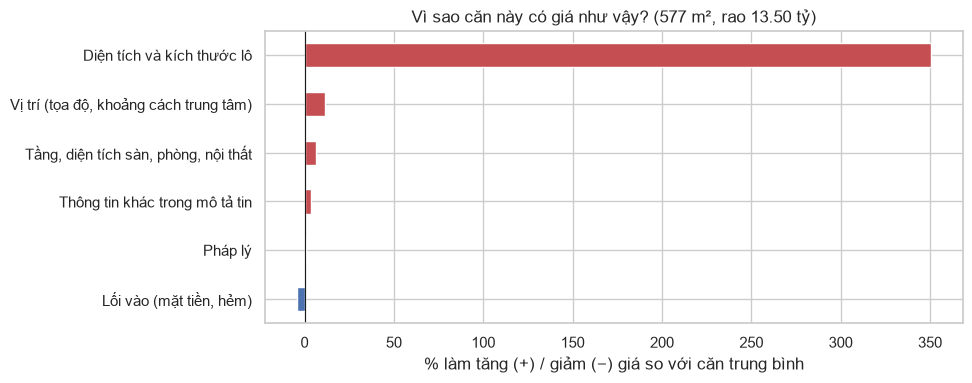

Đóng góp trung bình tuyệt đối theo nhóm (Phú Hòa, % giá):


,% trung bình
Diện tích và kích thước lô,42.2
"Tầng, diện tích sàn, phòng, nội thất",15.4
"Vị trí (tọa độ, khoảng cách trung tâm)",10.5
"Lối vào (mặt tiền, hẻm)",6.4
Pháp lý,3.8
Thông tin khác trong mô tả tin,1.4


Đã lưu models/giai_thich_nha.json cho 221 căn Phú Hòa


In [43]:
from scipy import sparse
NHOM_GT = {
    "Vị trí (tọa độ, khoảng cách trung tâm)": ["lat", "lon", "kc_trung_tam_km"],
    "Diện tích và kích thước lô": ["log_dt", "ngang", "dai"],
    "Tầng, diện tích sàn, phòng, nội thất": ["so_tang", "dt_san", "ty_le_san", "phong_ngu", "so_wc", "noi_that", "t_cap4", "t_nha_moi", "t_nha_nat", "t_thang_may", "t_biet_thu"],
    "Lối vào (mặt tiền, hẻm)": ["mat_tien_duong", "cap_loi_vao", "hem_rong", "t_hem_xe_hoi", "t_hem_nho", "t_mat_tien", "t_goc", "t_kinh_doanh"],
    "Pháp lý": ["so_chung", "t_so_rieng", "t_so_chung", "t_chua_hc"],
}
def dong_gop_cay(goi_mh, X):
    # Đóng góp theo đường đi trên cây (Saabas) cho mô hình cây / rừng cây của sklearn bọc trong MoHinhGia.
    # Trả về (giá trị nền, DataFrame đóng góp log theo đặc trưng); mô hình khác trả (None, None).
    pipe = goi_mh.m_
    est = pipe[-1] if hasattr(pipe, "steps") else pipe
    cac_cay = list(getattr(est, "estimators_", [])) or ([est] if hasattr(est, "tree_") else [])
    if not cac_cay or getattr(goi_mh, "khong_gian", True):
        return None, None
    Z = goi_mh._Z(X)
    cot = list(pipe[:-1].get_feature_names_out()) if hasattr(pipe, "steps") else list(Z.columns)
    Z = np.asarray(pipe[:-1].transform(Z) if hasattr(pipe, "steps") else Z, dtype=np.float32)
    nen, C = 0.0, np.zeros(Z.shape)
    for t in cac_cay:
        tr = t.tree_; v = tr.value[:, 0, 0]
        cha = np.full(tr.node_count, -1)
        nut = np.where(tr.children_left >= 0)[0]
        cha[tr.children_left[nut]] = nut; cha[tr.children_right[nut]] = nut
        con = np.where(cha >= 0)[0]
        # mỗi nút con: (giá trị nút − giá trị nút cha) ghi cho đặc trưng mà nút cha dùng để tách
        M = sparse.csr_matrix((v[con] - v[cha[con]], (con, tr.feature[cha[con]])), shape=(tr.node_count, Z.shape[1]))
        C += (t.decision_path(Z) @ M).toarray(); nen += v[0]
    return nen / len(cac_cay), pd.DataFrame(C / len(cac_cay), columns=cot, index=X.index)

# Giải thích ngoài-fold: mỗi căn được giải thích bởi mô hình không học căn đó (5-fold theo nhóm trên toàn bộ dữ liệu)
DG, nen_fold = pd.DataFrame(index=df.index, columns=DT_CO_BAN, dtype=float), []
for a, b in GroupKFold(5, shuffle=True, random_state=RANDOM_STATE).split(df, groups=df["nhom"]):
    m_ = MO_HINH[ten_tot_nhat]().fit(df.iloc[a], df["y"].iloc[a])
    nen_f, C_f = dong_gop_cay(m_, df.iloc[b])
    if C_f is None:
        break
    assert np.allclose(nen_f + C_f.sum(axis=1), m_.predict(df.iloc[b]), atol=1e-4)   # tự kiểm: nền + tổng đóng góp = dự đoán
    DG.loc[C_f.index, C_f.columns] = C_f.to_numpy(); nen_fold.append(nen_f)
if not nen_fold:
    GT = None
    print(f"Mô hình cuối ({ten_tot_nhat}) không phải mô hình cây: bỏ qua phần giải thích đóng góp.")
else:
    nen = float(np.mean(nen_fold))
    da_dung = set()
    GT = {}
    for ten, cols in NHOM_GT.items():
        cc = [c for c in cols if c in DG]; da_dung |= set(cc); GT[ten] = DG[cc].sum(axis=1)
    GT["Thông tin khác trong mô tả tin"] = DG[[c for c in DG if c not in da_dung]].sum(axis=1)
    GT = pd.DataFrame(GT)
    print(f"Giá trị nền của mô hình (trung bình dữ liệu, thang log giá tỷ): {nen:.3f}")
    vd = df.index[(df["phu_hoa"] == 1)][np.argmax(np.abs(GT.loc[df["phu_hoa"] == 1].sum(axis=1)).to_numpy())]
    hieu_ung = (np.exp(GT.loc[vd]) - 1) * 100
    ax = hieu_ung.sort_values().plot.barh(color=np.where(hieu_ung.sort_values() > 0, "#C44E52", "#4C72B0"), figsize=(9, 3.8))
    ax.axvline(0, color="k", lw=0.8)
    ax.set(title=f"Vì sao căn này có giá như vậy? ({df.loc[vd, 'dt_dat']:.0f} m², rao {df.loc[vd, 'gia_ty']:.2f} tỷ)", xlabel="% làm tăng (+) / giảm (−) giá so với căn trung bình")
    plt.show()
    print("Đóng góp trung bình tuyệt đối theo nhóm (Phú Hòa, % giá):")
    dong_gop_ph = ((np.exp(GT.loc[df["phu_hoa"] == 1].abs()) - 1) * 100).mean().sort_values(ascending=False)
    display(dong_gop_ph.round(1).to_frame("% trung bình"))
    gt_ph = {str(df.loc[i, "id"]): {k: round(float(v), 4) for k, v in GT.loc[i].items()} for i in df.index[df["phu_hoa"] == 1]}
    json.dump({"nen_log": round(nen, 4), "muc_tieu": mo_hinh_cuoi_muc_tieu, "mo_hinh": ten_tot_nhat, "nhom": list(GT.columns), "can": gt_ph},
              open(MODEL_DIR / "giai_thich_nha.json", "w", encoding="utf-8"), ensure_ascii=False)
    print("Đã lưu models/giai_thich_nha.json cho", len(gt_ph), "căn Phú Hòa")

In [44]:
if GT is not None:
    nx(f'''**Đọc biểu đồ:** cột đỏ là yếu tố làm căn này **đắt hơn** căn trung bình trong dữ liệu, cột xanh làm **rẻ hơn**. Trung bình trên các căn Phú Hòa (bảng trên), **{dong_gop_ph.index[0]}** đóng góp nhiều nhất (≈ {vn(dong_gop_ph.iloc[0], 0)}% giá), rồi {", ".join(f"{k} (≈ {vn(v, 0)}%)" for k, v in dong_gop_ph.iloc[1:3].items())}. Trang demo hiển thị đúng phân tích này trong phần chi tiết của từng tin.''')

**Đọc biểu đồ:** cột đỏ là yếu tố làm căn này **đắt hơn** căn trung bình trong dữ liệu, cột xanh làm **rẻ hơn**. Trung bình trên các căn Phú Hòa (bảng trên), **Diện tích và kích thước lô** đóng góp nhiều nhất (≈ 42% giá), rồi Tầng, diện tích sàn, phòng, nội thất (≈ 15%), Vị trí (tọa độ, khoảng cách trung tâm) (≈ 11%). Trang demo hiển thị đúng phân tích này trong phần chi tiết của từng tin.

Hàm dự đoán cho một căn nhà mới. Thông số nào không biết thì để `None`. Nếu không có tọa độ, hàm dùng tọa độ trung vị của tuyến đường (hoặc của phường Phú Hòa). Có thể dán **mô tả tin** vào `mo_ta` để mô hình đọc thêm thông tin.

In [45]:
goi = joblib.load(MODEL_DIR / "mo_hinh_gia_nha.joblib")

def du_doan_gia(dt_dat, ngang=None, dai=None, so_tang=None, dt_san=None, phong_ngu=None, so_wc=None,
                mat_tien_duong=0, cap_loi_vao=None, hem_rong=None, duong=None, phuong="phu hoa", quan="thu dau mot",
                lat=None, lon=None, mo_ta=""):
    van_ban = khong_dau(mo_ta)
    if lat is None:
        if duong and (quan, khong_dau(duong)) in xy_duong.index:
            lat, lon = xy_duong.loc[(quan, khong_dau(duong))].values
        else:
            lat, lon = xy_phuong.loc[(quan, phuong)].values
    can = pd.DataFrame([{"dt_dat": dt_dat, "ngang": ngang, "dai": dai, "so_tang": so_tang, "dt_san": dt_san,
                         "phong_ngu": phong_ngu, "so_wc": so_wc, "mat_tien_duong": mat_tien_duong, "cap_loi_vao": cap_loi_vao,
                         "hem_rong": hem_rong, "so_chung": np.nan, "noi_that": np.nan, "quan": quan, "phuong": phuong,
                         "duong": khong_dau(duong) if duong else None, "lat": lat, "lon": lon, "van_ban": van_ban}])
    can = pd.concat([can, trich_dac_trung_chu(can["van_ban"])], axis=1)
    can["log_dt"] = np.log(can["dt_dat"]); can["ty_le_san"] = can["dt_san"] / can["dt_dat"]
    can["kc_trung_tam_km"] = np.hypot((lat - TRUNG_TAM_TDM[0]) * 110.6, (lon - TRUNG_TAM_TDM[1]) * 109.3)
    can = can.astype({c_: float for c_ in ["ngang", "dai", "so_tang", "dt_san", "phong_ngu", "so_wc", "cap_loi_vao", "hem_rong"]})
    p = float(goi["model"].predict(can)[0])
    q = {k_: float(v[0]) for k_, v in phan_vi_cho(nhom_khoang(p, goi["khoang_theo_muc"]["nguong"], phuong == "phu hoa"), goi["khoang_theo_muc"]).items()}
    return {"gia_du_doan_ty": round(np.exp(p), 2), "khoang_80_ty": (round(np.exp(p + q["q10"]), 2), round(np.exp(p + q["q90"]), 2))}

vi_du = {
    "Nhà cấp 4, 100 m² (5x20), hẻm xe hơi 4m": dict(dt_dat=100, ngang=5, dai=20, so_tang=1, dt_san=100, phong_ngu=2, so_wc=1,
                                                     cap_loi_vao=2, hem_rong=4, mo_ta="nhà cấp 4 hẻm xe hơi sổ riêng"),
    "Nhà 1 trệt 1 lầu, 80 m², hẻm xe tải 6m, khu dân cư": dict(dt_dat=80, ngang=4.5, so_tang=2, dt_san=160, phong_ngu=3, so_wc=2,
                                                                cap_loi_vao=3, hem_rong=6, mo_ta="1 trệt 1 lầu kdc hẻm 6m sổ hồng riêng"),
    "Nhà 1 trệt 2 lầu, 120 m², mặt tiền Nguyễn Thị Minh Khai": dict(dt_dat=120, ngang=6, dai=20, so_tang=3, dt_san=300, phong_ngu=4,
                                                                     so_wc=4, mat_tien_duong=1, cap_loi_vao=5, hem_rong=20,
                                                                     duong="Nguyễn Thị Minh Khai", mo_ta="mặt tiền kinh doanh"),
}
pd.DataFrame({k: du_doan_gia(**v) for k, v in vi_du.items()}).T

,gia_du_doan_ty,khoang_80_ty
"Nhà cấp 4, 100 m² (5x20), hẻm xe hơi 4m",2.99,"(2.17, 4.77)"
"Nhà 1 trệt 1 lầu, 80 m², hẻm xe tải 6m, khu dân cư",3.41,"(2.48, 5.45)"
"Nhà 1 trệt 2 lầu, 120 m², mặt tiền Nguyễn Thị Minh Khai",6.41,"(4.65, 10.23)"


## Kết luận

**Kết quả đạt được** (các con số chính và hạn chế định lượng được in từ kết quả ở ô cuối notebook)
- Đánh giá bằng **kiểm định chéo lặp, chia theo nhóm tin gần trùng**, mọi chỉ số có khoảng tin cậy 95%. Mô hình cuối là mô hình tốt nhất trong các mô hình của môn học (Phần A), được so với một mô hình đối chứng ngoài bài giảng (Bước 8–9). Con số trình bày gồm **ba cách đo** trên các căn Phú Hòa: kiểm định chéo (Bước 8), tập test giữ riêng (Bước 9) và dự đoán chéo theo nhóm trên toàn bộ căn Phú Hòa (Bước 11), mỗi số kèm khoảng tin cậy và cách đọc (bảng ngay dưới phần kết luận).
- So với cách làm của phiên bản 1 và baseline đơn giá phường: xem bảng kiểm chứng ở Bước 8, có kèm khoảng tin cậy của chênh lệch.
- Mỗi dự đoán có **khoảng giá 80%** đã kiểm chứng độ phủ, và mỗi tin Phú Hòa có **chẩn đoán** rẻ / hợp lý / cao so với thị trường (`results/output.csv`).
- Yếu tố quyết định giá: diện tích đất, **vị trí** (tọa độ, khoảng cách tới trung tâm), sau đó là lối vào và thông tin trong mô tả tin.

**Những gì đã thử nhưng không cải thiện (đã gỡ khỏi quy trình)**
- Định vị tuyến đường bằng OpenStreetMap: chỉ áp dụng được cho một số ít tin, không giảm sai số đo được. Nguyên nhân: tin rao không có số nhà, nên biết tuyến đường cũng chỉ định vị tới mức "đâu đó trên đường".
- Đặc trưng "giá các căn gần nhất cùng loại lối vào": không giảm sai số; mô hình vốn không lệch có hệ thống với nhà mặt tiền (Bước 9).

**Hạn chế còn lại (cần nêu khi trình bày; phần có số liệu ở ô cuối)**
- Mô hình ước lượng **mặt bằng giá rao**, không phải giá giao dịch: vẫn là **giá rao bán**, chưa phải giá giao dịch công chứng (dữ liệu này không công khai). Phần lớn sai số (con số ở ô kết luận cuối) đến từ độ "ảo" của giá rao.
- Vị trí chỉ chính xác tới **tuyến đường hoặc phường** với phần lớn tin; muốn tốt hơn cần số nhà hoặc tọa độ do người đăng ghim.
- Không có thông tin chất lượng xây dựng thật (vật liệu, tuổi nhà); chỉ đọc được gián tiếp qua mô tả.
- **Căn hộ chung cư** không nằm trong mô hình này: xem notebook `du_doan_gia_can_ho.ipynb` (cùng quy trình đánh giá, đặc trưng riêng: dự án, tầng, pháp lý, nhà ở xã hội).
- Mô hình phản ánh thị trường **tháng 11/2026**; cần cập nhật dữ liệu định kỳ (`scripts/cap_nhat_dinh_ky.py`). Xu hướng giá được phân tích ở notebook `du_doan_xu_huong_gia.ipynb`.

In [46]:
# Con số cần trình bày: 3 cách đo trên các căn Phú Hòa, mỗi số kèm khoảng tin cậy 95% (bootstrap theo nhóm tin gần trùng)
cv_, te_ = bang_cv_ph.loc[ten_tot_nhat], bang_test_ph.loc[ten_tot_nhat]
ph_all_ = df[df["phu_hoa"] == 1]
ape_all = np.abs(ph_all_["gia_uoc_luong_ty"] / ph_all_["gia_ty"] - 1).to_numpy() * 100     # dự đoán chéo theo nhóm ở Bước 11
lo_all, hi_all = ktc_bootstrap(ape_all, ph_all_["nhom"].to_numpy())
phu_all = ((ph_all_["gia_ty"] >= ph_all_["khoang80_thap"]) & (ph_all_["gia_ty"] <= ph_all_["khoang80_cao"])).mean() * 100
TOM_TAT = pd.DataFrame({
    "Cách đo": ["KẾT QUẢ CHÍNH – Tập test giữ riêng: căn Phú Hòa chưa dùng ở bất kỳ bước nào",
                "Bổ trợ – Kiểm định chéo lặp theo nhóm: căn Phú Hòa trong tập train",
                "Bổ trợ – Dự đoán chéo theo nhóm trên TOÀN BỘ căn Phú Hòa (Bước 11)"],
    "Số căn": [int(te_["Số căn"]), int(cv_["Số căn"]), len(ph_all_)],
    "MAPE (%)": [round(te_["MAPE (%)"], 1), round(cv_["MAPE (%)"], 1), round(ape_all.mean(), 1)],
    "KTC 95%": [f"{te_['MAPE thấp (95%)']:.1f} – {te_['MAPE cao (95%)']:.1f}", f"{cv_['MAPE thấp (95%)']:.1f} – {cv_['MAPE cao (95%)']:.1f}", f"{lo_all:.1f} – {hi_all:.1f}"],
}).set_index("Cách đo")
display(TOM_TAT)
print(f"Độ phủ khoảng 80% trên toàn bộ {len(ph_all_)} căn Phú Hòa: {phu_all:.1f}%")
print("Cách đọc: tập test là KẾT QUẢ CHÍNH vì là bằng chứng sạch nhất (căn chưa từng dùng ở bất kỳ bước nào), nhưng chỉ vài chục căn nên khoảng tin cậy rộng. "
      "Dòng cuối dùng mọi căn Phú Hòa, mỗi căn được dự đoán bởi mô hình không học căn đó và các tin gần trùng, nên khoảng tin cậy hẹp hơn nhiều; "
      "nhưng các căn của tập train đã tham gia bước CHỌN mô hình, nên nó có thể lạc quan nhẹ và chỉ dùng để bổ trợ, không thay thế tập test. Ba con số nhất quán với nhau "
      "thì mới kết luận sai số ở Phú Hòa vào khoảng giữa các giá trị này.")

,Số căn,MAPE (%),KTC 95%
Cách đo,,,
KẾT QUẢ CHÍNH – Tập test giữ riêng: căn Phú Hòa chưa dùng ở bất kỳ bước nào,44,26.4,19.5 – 38.7
Bổ trợ – Kiểm định chéo lặp theo nhóm: căn Phú Hòa trong tập train,177,23.5,20.4 – 27.3
Bổ trợ – Dự đoán chéo theo nhóm trên TOÀN BỘ căn Phú Hòa (Bước 11),221,24.2,21.0 – 27.7


Độ phủ khoảng 80% trên toàn bộ 221 căn Phú Hòa: 81.4%
Cách đọc: tập test là KẾT QUẢ CHÍNH vì là bằng chứng sạch nhất (căn chưa từng dùng ở bất kỳ bước nào), nhưng chỉ vài chục căn nên khoảng tin cậy rộng. Dòng cuối dùng mọi căn Phú Hòa, mỗi căn được dự đoán bởi mô hình không học căn đó và các tin gần trùng, nên khoảng tin cậy hẹp hơn nhiều; nhưng các căn của tập train đã tham gia bước CHỌN mô hình, nên nó có thể lạc quan nhẹ và chỉ dùng để bổ trợ, không thay thế tập test. Ba con số nhất quán với nhau thì mới kết luận sai số ở Phú Hòa vào khoảng giữa các giá trị này.


In [47]:
# Kết luận có số liệu: in từ kết quả vừa tính (không viết tay)
A_ = TEN_DOI_CHUNG
te_tdm_ = bang_test_tdm.loc[ten_tot_nhat]
thieu_, du_ = [TC["thong_so"].loc[k, "MAPE (%)"] for k in sorted(TC["thong_so"].index, key=lambda k: not k.startswith("Thiếu"))]
k_ph, n_ph, p_ph = PHU_TEST["test Phú Hòa"]
nx(f'''**Kết luận – các con số chính**
- **Dữ liệu thật** từ 3 nguồn (guland, Chợ Tốt Nhà, alonhadat), hợp nhất mọi kỳ thu thập: sau khi sửa lỗi, loại trùng và loại tin không phải giá thị trường còn {vn(len(df), 0)} căn, trong đó Phú Hòa {int(df["phu_hoa"].sum())} căn. Không dùng dữ liệu mô phỏng.
- **Mô hình cuối: {ten_tot_nhat}** (tốt nhất trong các mô hình của môn học, chọn bằng kiểm định chéo ở Phần A). Trên tập test sai {vn(te_tdm_["MAPE (%)"])}% trên toàn Thủ Dầu Một và {vn(te_["MAPE (%)"])}% trên Phú Hòa (khoảng tin cậy {vn(te_["MAPE thấp (95%)"])}–{vn(te_["MAPE cao (95%)"])}%); kiểm định chéo trên Phú Hòa {vn(cv_["MAPE (%)"])}%. Baseline đơn giá phường: {vn(bang_test_tdm.loc["Baseline (đơn giá phường)", "MAPE (%)"])}% và {vn(bang_test_ph.loc["Baseline (đơn giá phường)", "MAPE (%)"])}%.
- **{A_}** (ngoài bài giảng): {vn(bang_test_tdm.loc[A_, "MAPE (%)"])}% trên toàn Thủ Dầu Một và {vn(bang_test_ph.loc[A_, "MAPE (%)"])}% trên Phú Hòa; {"khoảng tin cậy chồng với mô hình cuối ở cả hai vùng, nên giữ mô hình của môn học không làm mất độ chính xác chứng minh được" if AB_chong else "khác biệt với mô hình cuối có ý nghĩa ở ít nhất một vùng (xem Bước 9)"}.
- **Sai số không đều:** tin thiếu thông số sai {vn(thieu_, 0)}% so với {vn(du_, 0)}% ở tin đủ thông số; nhóm giá rẻ nhất sai nhiều nhất; vài phường chưa đủ mẫu (Bước 11).
- **Tập test Phú Hòa nhỏ** ({int(te_["Số căn"])} căn): khoảng tin cậy rộng, không đủ để phân hạng các mô hình ở riêng Phú Hòa; cần thêm tin Phú Hòa qua các kỳ thu thập định kỳ (dữ liệu đã tự hợp nhất mọi kỳ).
- **Khoảng 80% ở Phú Hòa:** phủ {vn(k_ph / n_ph * 100, 0)}% trên {n_ph} căn test (p = {vn(p_ph, 2)}{", chưa bác bỏ được mức 80%" if p_ph >= 0.05 else ", khoảng quá hẹp"}) và {vn(phu_all, 0)}% trên toàn bộ {len(ph_all_)} căn Phú Hòa.''')

**Kết luận – các con số chính**
- **Dữ liệu thật** từ 3 nguồn (guland, Chợ Tốt Nhà, alonhadat), hợp nhất mọi kỳ thu thập: sau khi sửa lỗi, loại trùng và loại tin không phải giá thị trường còn 1.882 căn, trong đó Phú Hòa 221 căn. Không dùng dữ liệu mô phỏng.
- **Mô hình cuối: Random Forest (300 cây)** (tốt nhất trong các mô hình của môn học, chọn bằng kiểm định chéo ở Phần A). Trên tập test sai 26,4% trên toàn Thủ Dầu Một và 26,4% trên Phú Hòa (khoảng tin cậy 19,5–38,7%); kiểm định chéo trên Phú Hòa 23,5%. Baseline đơn giá phường: 36,3% và 26,1%.
- **Đối chứng: LightGBM + giá khu vực** (ngoài bài giảng): 25,6% trên toàn Thủ Dầu Một và 27,1% trên Phú Hòa; khoảng tin cậy chồng với mô hình cuối ở cả hai vùng, nên giữ mô hình của môn học không làm mất độ chính xác chứng minh được.
- **Sai số không đều:** tin thiếu thông số sai 28% so với 22% ở tin đủ thông số; nhóm giá rẻ nhất sai nhiều nhất; vài phường chưa đủ mẫu (Bước 11).
- **Tập test Phú Hòa nhỏ** (44 căn): khoảng tin cậy rộng, không đủ để phân hạng các mô hình ở riêng Phú Hòa; cần thêm tin Phú Hòa qua các kỳ thu thập định kỳ (dữ liệu đã tự hợp nhất mọi kỳ).
- **Khoảng 80% ở Phú Hòa:** phủ 75% trên 44 căn test (p = 0,25, chưa bác bỏ được mức 80%) và 81% trên toàn bộ 221 căn Phú Hòa.